# Standalone tests and feature selection

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/firefly1248/demo-notebooks/blob/main/notebooks/feature_selection/standalone_tests_feature_selection.ipynb)

A standalone test scores one feature at a time: how does the target depend on `x` alone?
Correlation, mutual information (how much knowing `x` reduces the uncertainty about `y`),
chi-square, information value (a credit-scoring measure of how the class shares differ across bins
of `x`) and single-feature AUC are standalone tests. A model uses a feature given the other
features, so a feature with no standalone signal can still be one of its most important inputs.

- **Part 2** reproduces the post's numbers on three small simulations (city and price, hour x
  distance, a linear suppressor). It is an existence proof: one feature's standalone signal is
  zero by construction, so no standalone test can find it. It says nothing about how often this
  happens in real data.
- **Part 3** asks which cheap selection methods keep the features that matter only in
  combination, at what cost, and where they fail. It weakens the joint effects to look for the point
  where model-based methods fail too; a contest one side wins everywhere would show nothing.
- **Part 4** stress-tests these methods on the pool with more seeds and weaker joint effects, on a grid of sample sizes, and
  adds other filters (scores computed without fitting the final model), the `feature_engine`
  selectors and CatBoost's own recursive elimination.
- **Part 5** asks whether a shortlist selected with CatBoost helps other final models, whether the
  forest's failure in the weak pool (4a at s = 0.25) lies in the model or in its importance, and how LightGBM does
  as the selector. 5d draws Figure 3 and Figure 2.

Every random draw uses a named seed. In a check run (not printed here) the results did not depend on the thread count.
Across CPU types CatBoost AUC values move in the third decimal, while CTR counts and interaction
ranks move more; Parts 3 to 5 were run on one CPU type. The nearest-neighbor mutual information can move
with the scikit-learn version. The claims cell at the end checks the Part 2 numbers against the
reference run (a Linux container, 2 cores, catboost 1.2.10) and repeats the main Part 3 tables.

The full run takes about 3 hours 15 minutes on an Apple M4 Pro with all 14 cores (`N_JOBS=-1`, the
default), most of it in Part 4; the last cell prints the runtime. A free Colab runtime has 2
cores, so expect it to take much longer there. For a quicker check set the environment variable
`QUICK=1` (on Colab, run `%env QUICK=1` before the first code cell). Part 2 and its checks stay as
they are, with 2 refit seeds instead of 5. 3a uses 2 seeds, strengths 1 and 0.25, and N = 20,000;
3b uses one seed, N = 10,000 and one shuffle; 3c, 3d, Parts 4 and 5 (with Figures 2 and 3) and the hypotheses are skipped. This
took about 8 minutes in a check run on the same machine with 2 threads (`N_JOBS=2`), more on Colab. The numbers
then differ from the published ones, and the text still describes the full run.

## Changes since 173eae7

- Part 4 (4a to 4e, hypotheses H8 to H18) and Part 5 (5a to 5d, H19 to H24) are new. The numbers
  of Parts 1 to 3 are unchanged; Part 2 has a new figure (acceptance by city and price) and Part 3
  a new row, CB SHAP.
- Figures 1 and 2 are redrawn. Figure 2 also shows the weak pool of 4a, so it is now drawn in 5d, and drops the s = 1
  columns of 3a.
  Figure 3 is new.
- Summary corrections: H3 and H5 no longer say that the rows a score is computed on do not matter
  (only CB LFC and CB permutation were computed on the training rows). H1 and the 3b text now
  separate the 3b pool from 4a, where at s = 1 MI, the F test and IV put up to 1 of the 4
  interaction-only features in their top 14 (mRMR F up to 2). The "Not tested" item on where
  permutation importance, CB LFC and drop-column fail is replaced by Part 4. H4 (the forest's `max_features`) is tested in 5b as H22.
  The Summary notes hour's small standalone effect in the pool.
- Case A is no longer called an interaction: city sets the price level, an additive term in the
  log-odds. "Interaction-only" is defined in Part 3.
- Part 4 verdicts: H8, H10, H11 and H17 partly, the others confirmed.
- Part 5 verdicts: H20 and H23 confirmed, H19 and H22 partly, H21 and H24 not confirmed.

In [1]:
from importlib.metadata import version, PackageNotFoundError

PINS = {"catboost": "1.2.10", "mrmr_selection": "0.2.8", "feature_engine": "1.9.4", "skrebate": "0.8.4",
        "lightgbm": "4.7.0"}


def installed(package):
    try:
        return version(package)
    except PackageNotFoundError:
        return None


if any(installed(p) != v for p, v in PINS.items()):
    specs = " ".join(f"{p}=={v}" for p, v in PINS.items())
    !pip install -q {specs}

import json
import os
import platform
import subprocess
import tempfile
import time
import warnings
from collections import Counter, namedtuple
from contextlib import contextmanager
from itertools import permutations

import catboost
import category_encoders as ce
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from catboost import CatBoostClassifier, Pool
from feature_engine.selection import MRMR, ProbeFeatureSelection, RecursiveFeatureElimination, SelectByShuffling
from lightgbm import LGBMClassifier
from mrmr import mrmr_classif
from skrebate import MultiSURF
from scipy import stats
from scipy.stats import chi2_contingency, false_discovery_control
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import f_classif, mutual_info_classif, mutual_info_regression
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import log_loss, roc_auc_score
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220, "display.max_columns", 40)


def cpu_model():
    if os.path.exists("/proc/cpuinfo"):
        return next((l.split(":", 1)[1].strip() for l in open("/proc/cpuinfo") if l.startswith("model name")),
                    platform.processor())
    return subprocess.run(["sysctl", "-n", "machdep.cpu.brand_string"], capture_output=True, text=True).stdout.strip()


N_JOBS = int(os.environ.get("N_JOBS", -1))  # threads for CatBoost and the random forest; results do not depend on it
print(f"python {platform.python_version()}, " + ", ".join(
    f"{m.__name__} {m.__version__}" for m in (np, pd, scipy, sklearn, catboost, matplotlib)))
print(f"CPU: {cpu_model()}, {os.cpu_count()} logical cores, N_JOBS = {N_JOBS}")
print(f"mrmr_selection {version('mrmr_selection')}, feature_engine {version('feature_engine')}, "
      f"skrebate {version('skrebate')} (Part 4c to 4e), lightgbm {version('lightgbm')} (Part 5)")
QUICK = os.environ.get("QUICK") == "1"  # on Colab: run %env QUICK=1 before this cell
if QUICK:
    print("QUICK mode: numbers are not the published ones")

# Seeds and sizes
SEED_A, SEED_B, SEED_C = 42, 7, 1      # post datasets
CV_SEED = 0                            # StratifiedKFold
MI_SEEDS = range(1000, 1020)           # repeated mutual information top 2
INTERACTION_SEEDS = range(2000, 2006)  # interaction importance check
REFIT_SEEDS = range(2 if QUICK else 5) # CatBoost random_seed values for the refit-noise check
STRENGTH_SEEDS = range(6000, 6002 if QUICK else 6005)  # Part 3a
STRENGTHS = (1, 0.25) if QUICK else (1, 0.5, 0.25, 0.1)  # interaction multiplier in Part 3a
FRESH_OFFSET = 500                     # a selected set is scored on a fresh draw with seed + FRESH_OFFSET
POOL_SEEDS = range(6100, 6101 if QUICK else 6103)      # Part 3b
SHADOW_REPEATS = 1 if QUICK else 5     # shuffles per pool seed for the shadow cutoff
POOL_N = 10_000 if QUICK else 20_000
MAIN_SEEDS = range(6200, 6210)         # Part 3c
MAIN_EFFECTS = (0, 0.1, 0.2, 0.4)
DUP_SEEDS = range(6300, 6305)          # Part 3d
CB_REFIT_NOISE = 0.004                 # Part 2: CatBoost refit noise in AUC, the tolerance of the claims cell
AUX_OFFSET = 900                       # columns added to a generated dataset (3a control, 3b shadows, 3d copy) use seed + AUX_OFFSET
# Part 4, new seeds
POOL2_SEEDS = range(7100, 7106)        # Part 4a
POOL2_STRENGTHS = (1, 0.25)
POOL2_SHUFFLES = 2
GRID_SEEDS = range(7200, 7205)         # 4b
GRID_N = (2_000, 5_000, 10_000, 40_000)
GRID_S = (0.25, 0.1, 0.05)
EXTEND_N = (1_000, 500)                # 4b, run only if some method never fails in the grid
WIDE_SEEDS = range(7300, 7305)         # 4b, 100 noise columns
WIDE_N, WIDE_S = 10_000, (0.5, 0.25)
LEAK_SEED = 7400                       # 4c
# Part 5
P5_S = 0.25                            # Part 5: the pool at s = 0.25
P5A_SEEDS = POOL2_SEEDS                # 5a: final models on the 4a column sets
P5A_STRENGTHS = (0.25, 1)              # 5a: s = 1 too, since the timing check left room in the budget
P5B_SEEDS = range(7100, 7103)          # 5b: forest max_features
RF_VARIANTS = (("sqrt", 20), (1.0, 20), (1.0, 5))  # 5b: (max_features, min_samples_leaf)
P5C_POOL_SEEDS = P5B_SEEDS             # 5c: LightGBM as the selector on the pool
LGB_SHUFFLES = 2                       # 5c: shuffles of the LightGBM shadow cutoff

TIMES = {}


@contextmanager
def timed(block, store=TIMES):
    t = time.perf_counter()
    yield
    store[block] = time.perf_counter() - t


T0 = time.perf_counter()
plt.rcParams.update({"font.size": 15, "axes.titlesize": 16, "axes.labelsize": 15, "xtick.labelsize": 15,
                     "ytick.labelsize": 15, "legend.fontsize": 14, "legend.frameon": False,
                     "axes.spines.top": False, "axes.spines.right": False, "savefig.dpi": 200})

python 3.12.12, numpy 2.5.3, pandas 3.0.5, scipy 1.18.1, sklearn 1.9.1, catboost 1.2.10, matplotlib 3.11.2
CPU: Apple M4 Pro, 14 logical cores, N_JOBS = -1
mrmr_selection 0.2.8, feature_engine 1.9.4, skrebate 0.8.4 (Part 4c to 4e), lightgbm 4.7.0 (Part 5)


## Part 1: data generators

The generators below are used unchanged. Case A: a driver accepts an order when the price
is high for this city, and every city sits at the same point of the same curve, so the acceptance
rate is about 50% in each city. Case B is an interaction: at night long trips are accepted and at noon
short ones, so the effect of distance flips its sign during the day. Case C: `x2` is pure noise that also sits
inside `x1`. Case A is the same mechanism as C with a categorical column: in the logit (log-odds)
the term is `log_price` minus the city's price level, so city has no signal of its own and only
corrects price. In log-odds there is no interaction. Each generator also returns the true probability, or the clean target for C, so the
best possible AUC (the ceiling) is known.

In [2]:
import numpy as np, pandas as pd

N = 40_000

def add_noise(df, rng, k=3):
    for i in range(k):
        df[f"noise_{i + 1}"] = rng.normal(size=len(df))
    return df

def gen_a(seed):
    """City shifts the price threshold. Acceptance is about 50% in every city."""
    rng = np.random.default_rng(seed)
    city_levels = np.log([300, 600, 900, 1500])
    city = rng.integers(0, 4, N)
    log_price = city_levels[city] + rng.normal(0, 0.25, N)
    p = 1 / (1 + np.exp(-8 * (log_price - city_levels[city])))
    y = rng.binomial(1, p)
    df = add_noise(pd.DataFrame({"log_price": log_price, "city": city}), rng)
    return df, y, p

def gen_b(seed):
    """Hour flips the sign of the distance effect."""
    rng = np.random.default_rng(seed)
    hour = rng.uniform(0, 24, N)
    distance_km = rng.lognormal(mean=np.log(6), sigma=0.6, size=N)
    z = (np.log(distance_km) - np.log(6)) / 0.6
    night = np.cos(2 * np.pi * hour / 24)          # +1 at midnight, -1 at noon
    p = 1 / (1 + np.exp(-(0.3 * z + 2.5 * night * z)))
    y = rng.binomial(1, p)
    df = add_noise(pd.DataFrame({"distance_km": distance_km, "hour": hour}), rng)
    return df, y, p

def gen_c(seed=1):
    """Linear suppressor: x2 has no link to the target but cancels noise in x1."""
    rng = np.random.default_rng(seed)
    s = rng.normal(size=N)              # signal
    nz = rng.normal(size=N)             # noise
    x1 = s + 2 * nz
    x2 = nz
    t = s + rng.normal(0, 0.3, N)
    return x1, x2, t

## Part 2: the numbers of the post

Standalone tests used here:

- **Mutual information**, in nats: scikit-learn's `mutual_info_classif`, with `city` marked as
  discrete. Discrete columns get a plug-in estimate (computed from the counts in each cell),
  continuous ones a nearest-neighbor estimate (from distances between nearby points) clipped at
  zero. Their biases differ: the plug-in estimate for a 4-level column with no link to
  `y` is about (4 - 1) / (2N) = 0.00004, while a continuous noise column often gets exactly 0.
- **p-value**: chi-square test of independence for `city`, ANOVA F-test for numeric columns.
- **Information value**: 10 quantile bins for numeric columns, 0.5 added to every cell.
- **AUC alone**: out-of-fold ROC AUC of CatBoost trained on that one column.

In-model score:

- **Drop-column importance**: the AUC of the model on all columns minus the AUC of a model
  retrained without the column, on the same folds.

CatBoost: 300 iterations, depth 6, learning rate 0.1, `city` categorical. CV is 5-fold
stratified, and the AUC is computed on the pooled out-of-fold predictions.

In [3]:
CV = StratifiedKFold(5, shuffle=True, random_state=CV_SEED)
NOISE = ["noise_1", "noise_2", "noise_3"]  # the noise columns of add_noise
P2 = {}  # Part 2 values for the claims cell


def information_value(x, y, bins=10):
    x = pd.Series(np.asarray(x))
    g = pd.qcut(x, bins, duplicates="drop") if x.nunique() > bins else x
    t = pd.crosstab(g, np.asarray(y))
    pos = (t[1] + 0.5) / (t[1].sum() + 0.5 * len(t))
    neg = (t[0] + 0.5) / (t[0].sum() + 0.5 * len(t))
    return float(((pos - neg) * np.log(pos / neg)).sum())


def standalone_logp(x, y, is_cat):
    # log p-value: chi-square for a categorical column, ANOVA F-test for a numeric one (log avoids underflow)
    if is_cat:
        stat, _, dof, _ = chi2_contingency(pd.crosstab(np.asarray(x), np.asarray(y)))
        return stats.chi2.logsf(stat, dof)
    f = f_classif(np.asarray(x).reshape(-1, 1), y)[0][0]
    return stats.f.logsf(f, 1, len(y) - 2)


def make_model(cats=(), **kw):
    params = dict(iterations=300, depth=6, learning_rate=0.1, random_seed=0, verbose=0,
                  thread_count=N_JOBS, allow_writing_files=False)
    params.update(kw)
    return CatBoostClassifier(cat_features=list(cats), **params)


def cv_auc(df, y, cols, cat_cols=(), **kw):
    # ROC AUC of the pooled out-of-fold predictions of CatBoost trained on `cols`
    oof = np.zeros(len(y))
    cats = [c for c in cols if c in cat_cols]
    for tr, te in CV.split(df, y):
        m = make_model(cats, **kw).fit(df.iloc[tr][cols], y[tr])
        oof[te] = m.predict_proba(df.iloc[te][cols])[:, 1]
    return roc_auc_score(y, oof)


def report(df, y, p, pair, cat_cols=()):
    cols = list(df.columns)
    mi = mutual_info_classif(df, y, discrete_features=[c in cat_cols for c in cols], random_state=0)
    full = cv_auc(df, y, cols, cat_cols)
    tab = pd.DataFrame({
        "MI": mi,
        "p (chi2 / ANOVA)": [np.exp(standalone_logp(df[c], y, c in cat_cols)) for c in cols],
        "IV": [information_value(df[c], y) for c in cols],
        "AUC alone": [cv_auc(df, y, [c], cat_cols) for c in cols],
        "drop-col dAUC": [full - cv_auc(df, y, [k for k in cols if k != c], cat_cols) for c in cols],
    }, index=cols)
    top2 = tab["MI"].nlargest(2).index.tolist()
    aucs = {"all five columns": full,
            f"{pair[0]} + {pair[1]} only": cv_auc(df, y, list(pair), cat_cols),
            "MI top 2": cv_auc(df, y, top2, cat_cols),
            "ceiling (true probability)": roc_auc_score(y, p)}
    with pd.option_context("display.float_format", "{:.5f}".format):
        print(tab.to_string())
    print()
    for k, v in aucs.items():
        label = f"MI top 2 ({top2[0]} + {top2[1]})" if k == "MI top 2" else k
        print(f"AUC, {label:<36}: {v:.4f}")
    return tab, top2, aucs

### Case A: city and price (seed 42)

Every standalone test sees the acceptance rate by city first, and that rate is flat.

In [4]:
with timed("Part 2 case A"):
    df_a, y_a, p_a = gen_a(SEED_A)
    rates_a = pd.Series(y_a).groupby(df_a["city"].values).mean()
    print("acceptance rate by city:", rates_a.round(3).to_dict(), "\n")
    tab_a, top2_a, aucs_a = report(df_a, y_a, p_a, pair=("log_price", "city"), cat_cols=("city",))
P2["A"] = dict(rates=rates_a, tab=tab_a, top2=top2_a, aucs=aucs_a)

acceptance rate by city: {0: 0.496, 1: 0.496, 2: 0.506, 3: 0.5} 



               MI  p (chi2 / ANOVA)      IV  AUC alone  drop-col dAUC
log_price 0.07101           0.00000 0.49613    0.69325        0.34716
city      0.00003           0.42613 0.00028    0.50000        0.16912
noise_1   0.00222           0.38348 0.00123    0.50555       -0.00033
noise_2   0.00479           0.93080 0.00091    0.49754       -0.00104
noise_3   0.00177           0.82229 0.00077    0.50767       -0.00077

AUC, all five columns                    : 0.8575
AUC, log_price + city only               : 0.8598
AUC, MI top 2 (log_price + noise_2)      : 0.6905
AUC, ceiling (true probability)          : 0.8608


City scores no better than the noise columns on every standalone test, and CatBoost on city alone is a coin
flip. Inside the model city is second only to price by drop-column importance, and price with
city gets close to the ceiling. The model on the mutual information top 2 is price plus a noise
column.

Top: the acceptance rate by city, which is all a standalone test of city sees. Bottom: the
acceptance rate against price for each city, over the same range around the city's price level
(12 price bins per city, price on a log scale); each dot marks the price at which the city reaches
50% acceptance. City sets that price, so it matters only together with price.

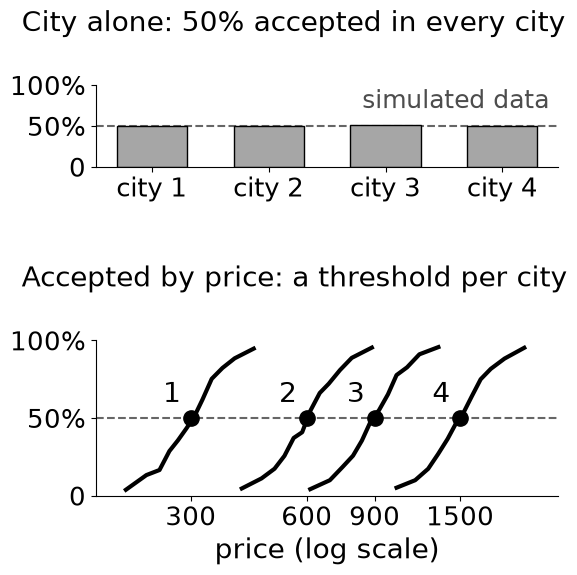

In [5]:
d = df_a.assign(y=y_a, price=np.exp(df_a.log_price))
levels = [300, 600, 900, 1500]   # the price levels of gen_a: acceptance is 50% at a city's level
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(6, 6), gridspec_kw={"height_ratios": [1, 1.9]})
rates = d.groupby("city").y.mean()
ax1.bar([f"city {c + 1}" for c in rates.index], rates.values, color="0.65", edgecolor="black", width=0.6)
ax1.text(0.98, 0.95, "simulated data", transform=ax1.transAxes, ha="right", va="top", fontsize=18, color="0.3")
for c, g in d.groupby("city"):
    g = g[(np.log(g.price / levels[c])).abs() <= 0.5]   # the same range around each city's level (2 sd)
    b = g.groupby(pd.qcut(g.price, 12), observed=True).agg(price=("price", "median"), y=("y", "mean"))
    ax2.plot(b.price, b.y, color="black", lw=3)
    ax2.plot(levels[c], 0.5, "o", color="black", ms=11)
    ax2.text(levels[c] / 1.06, 0.56, str(c + 1), fontsize=20, ha="right", va="bottom")
ax2.set_xscale("log")
ax2.set_xlim(170, 2700)
ax2.set_xticks(levels, [str(v) for v in levels])
ax2.minorticks_off()
ax2.set_xlabel("price (log scale)", fontsize=20)
for ax, title in ((ax1, "City alone: 50% accepted in every city"), (ax2, "Accepted by price: a threshold per city")):
    ax.axhline(0.5, color="0.4", ls="--", lw=1.5, zorder=0)
    ax.set_ylim(0, 1)
    ax.set_yticks([0, 0.5, 1], ["0", "50%", "100%"])
    ax.tick_params(labelsize=19)
    ax.annotate(title, xy=(-0.16, 1), xycoords="axes fraction", xytext=(0, 34), textcoords="offset points",
                fontsize=20, ha="left", va="bottom")  # one empty line between the title and the plot
fig.tight_layout(h_pad=3)
fig.savefig("standalone_tests_city_price.png")
plt.show()

### Case B: hour x distance (seed 7)

In [6]:
with timed("Part 2 case B"):
    df_b, y_b, p_b = gen_b(SEED_B)
    rates_b = pd.Series(y_b).groupby((df_b["hour"] // 4).astype(int).values * 4).mean()
    print("acceptance rate by 4-hour bin:", rates_b.round(3).to_dict(), "\n")
    tab_b, top2_b, aucs_b = report(df_b, y_b, p_b, pair=("distance_km", "hour"))
P2["B"] = dict(rates=rates_b, tab=tab_b, top2=top2_b, aucs=aucs_b)

acceptance rate by 4-hour bin: {0: 0.507, 4: 0.492, 8: 0.501, 12: 0.488, 16: 0.503, 20: 0.504} 



                 MI  p (chi2 / ANOVA)      IV  AUC alone  drop-col dAUC
distance_km 0.00239           0.00000 0.01971    0.53226        0.30992
hour        0.00048           0.74590 0.00088    0.50310        0.28293
noise_1     0.00338           0.26691 0.00054    0.49975       -0.00131
noise_2     0.00000           0.33011 0.00081    0.50107       -0.00185
noise_3     0.00000           0.40996 0.00025    0.49664       -0.00126

AUC, all five columns                    : 0.8098
AUC, distance_km + hour only             : 0.8133
AUC, MI top 2 (noise_1 + distance_km)    : 0.5296
AUC, ceiling (true probability)          : 0.8160


Averaged over the day the acceptance rate barely moves with the hour, so hour scores like noise
and distance scores only its small main effect (the `0.3 * z` term). Inside the model hour is
almost as important as distance. A model on the mutual information top 2 is, in effect, distance
alone.

### Mutual information top 2 over 20 other seeds

The same rule, keep the two columns with the highest mutual information, on 20 fresh datasets
per case. The table counts how often each column made the top 2, so the rate of the weak feature
can be read against the rate of a pure noise column.

In [7]:
with timed("Part 2 MI seeds"):
    counts, zeros_when_city, city_mi = {}, [], []
    for case, gen, cat_cols in [("A", gen_a, ("city",)), ("B", gen_b, ())]:
        picked = []
        for seed in MI_SEEDS:
            d, yy, _ = gen(seed)
            mi = pd.Series(mutual_info_classif(d, yy, discrete_features=[c in cat_cols for c in d.columns],
                                               random_state=seed), index=d.columns)
            picked.append(set(mi.nlargest(2).index))
            if case == "A":
                city_mi.append(mi["city"])
                if "city" in picked[-1]:
                    zeros_when_city.append(int((mi[NOISE] == 0).sum()))
        counts[case] = {c: sum(c in s for s in picked) for c in d.columns}
        weak, strong = ("city", "log_price") if case == "A" else ("hour", "distance_km")
        counts[case]["both real"] = sum({weak, strong} <= s for s in picked)
mi_seeds = pd.concat([pd.DataFrame(counts["A"], index=["A"]).T.rename(index={"city": "weak", "log_price": "strong"}),
                      pd.DataFrame(counts["B"], index=["B"]).T.rename(index={"hour": "weak", "distance_km": "strong"})], axis=1)
P2["mi_seeds"] = mi_seeds
print(f"Times in the top 2 over {len(MI_SEEDS)} seeds:")
print(mi_seeds.to_string())
print(f"\nA: number of noise columns (of 3) with MI exactly 0 in each seed where city made the top 2: {zeros_when_city}")
print(f"A: MI of city over the {len(MI_SEEDS)} seeds: mean {np.mean(city_mi):.6f}, min {np.min(city_mi):.6f}, "
      f"max {np.max(city_mi):.6f}; plug-in bias of a 4-level column with no effect, (4 - 1) / (2 * {N}) = {3 / (2 * N):.6f}")

Times in the top 2 over 20 seeds:
            A   B
strong     20  17
weak        4   4
noise_1     6   8
noise_2     5   4
noise_3     5   7
both real   4   3

A: number of noise columns (of 3) with MI exactly 0 in each seed where city made the top 2: [3, 3, 3, 3]
A: MI of city over the 20 seeds: mean 0.000034, min 0.000003, max 0.000111; plug-in bias of a 4-level column with no effect, (4 - 1) / (2 * 40000) = 0.000037


The weak feature makes the top 2 about as often as a pure noise column, which is what a column
with no standalone signal should do. In case A, `city` gets in only when the nearest-neighbor
estimate of every noise column was clipped to exactly 0, so the plug-in bias of the discrete
estimate (above) is enough to win.

### City coding and CTRs

City enters CatBoost as a categorical feature. With 4 values and the default
`one_hot_max_size`, it is encoded by CTRs, target statistics per category. A CTR of city alone is
the same for every city, because the acceptance rate is. CatBoost can also build CTRs of feature
combinations, city together with binarized splits of numeric columns; `max_ctr_complexity=1`
forbids those. The ids 0 to 3 of `gen_a` are ordered by price level, which gives a tree an easy
split when city is passed as a plain number. The check relabels the ids with the permutation of
0-3 whose correlation with the price level is smallest, and Part 3 uses the same relabeling.

In [8]:
CITY_LEVELS = np.log([300, 600, 900, 1500])
CITY_RELABEL = np.array(min(permutations(range(4)), key=lambda q: abs(np.corrcoef(q, CITY_LEVELS)[0, 1])))
df_a_relabeled = df_a.assign(city=CITY_RELABEL[df_a["city"]])
print(f"relabeling {list(range(4))} -> {CITY_RELABEL.tolist()}; corr(city id, log_price): "
      f"ordered {np.corrcoef(df_a['city'], df_a['log_price'])[0, 1]:.3f}, "
      f"relabeled {np.corrcoef(df_a_relabeled['city'], df_a_relabeled['log_price'])[0, 1]:.3f}\n")

allc = list(df_a.columns)
with timed("Part 2 coding"):
    enc = pd.Series({
        "city as categorical, defaults": aucs_a["all five columns"],
        "city as categorical, max_ctr_complexity=1": cv_auc(df_a, y_a, allc, ("city",), max_ctr_complexity=1),
        "city as categorical, one_hot_max_size=4": cv_auc(df_a, y_a, allc, ("city",), one_hot_max_size=4),
        "city as a plain number, ordered ids": cv_auc(df_a, y_a, allc),
        "city as a plain number, relabeled ids": cv_auc(df_a_relabeled, y_a, allc),
    }, name="CV AUC")
P2["encodings"] = enc
print(enc.round(4).to_string())

m_a = make_model(["city"]).fit(df_a, y_a)
path = os.path.join(tempfile.mkdtemp(), "model.json")
m_a.save_model(path, format="json")
fi = json.load(open(path))["features_info"]
float_name = {f["feature_index"]: f["feature_id"] for f in fi["float_features"]}  # float_feature_index counts float columns only
ctrs = fi["ctrs"]
with_numeric = [c for c in ctrs if any(e["combination_element"] == "float_feature" for e in c["elements"])]
elements = Counter(float_name[e["float_feature_index"]] for c in ctrs for e in c["elements"]
                   if e["combination_element"] == "float_feature")
n_elem = sum(elements.values())
P2["ctr"] = dict(n=len(ctrs), with_numeric=len(with_numeric), log_price_share=elements["log_price"] / n_elem)
print(f"\nCTR definitions in the default model fitted on all rows: {len(ctrs)}; with a numeric split inside: "
      f"{len(with_numeric)} ({len(with_numeric) / len(ctrs):.3f})")
print(f"numeric elements inside CTRs: {n_elem}; by column: {dict(elements.most_common())}; "
      f"log_price share {elements['log_price'] / n_elem:.3f}")

relabeling [0, 1, 2, 3] -> [1, 3, 0, 2]; corr(city id, log_price): ordered 0.915, relabeled 0.070



city as categorical, defaults                0.8575
city as categorical, max_ctr_complexity=1    0.6906
city as categorical, one_hot_max_size=4      0.8572
city as a plain number, ordered ids          0.8568
city as a plain number, relabeled ids        0.8567



CTR definitions in the default model fitted on all rows: 103; with a numeric split inside: 100 (0.971)
numeric elements inside CTRs: 170; by column: {'log_price': 120, 'noise_2': 21, 'noise_1': 20, 'noise_3': 9}; log_price share 0.706


Without CTR combinations (`max_ctr_complexity=1`) the AUC falls to the level of price alone,
because the CTR of city alone is flat. That limits the encoding, not the model: a tree can split on
city directly, and one-hot city and city as a plain number reach the same AUC as the default, and so does a plain number with relabeled ids, so the order of the ids does not matter here. Inside the default model almost every CTR
includes a numeric split. Most of those numeric elements are `log_price` splits, but a sizable
share are splits on noise columns.

### Interaction importance

`get_feature_importance(type="Interaction")` scores pairs of features from the trees. The rank of
the true pair among the 10 pairs moves between CPU types, so it is printed, not asserted. In A the
pair is additive in log-odds, so a high rank shows that the trees split on both columns together,
not that the data hold an interaction.

In [9]:
def pair_rank(model, cols, pair):
    order = [frozenset((cols[int(i)], cols[int(k)])) for i, k, _ in model.get_feature_importance(type="Interaction")]
    return order.index(frozenset(pair)) + 1


inter = m_a.get_feature_importance(type="Interaction")
print("case A, seed 42, top 4 pairs:", [(allc[int(i)], allc[int(k)], round(float(s), 2)) for i, k, s in inter[:4]])
P2["inter_rank_42"] = pair_rank(m_a, allc, ("log_price", "city"))
print("rank of (log_price, city):", P2["inter_rank_42"], "of", len(inter))
P2["inter_ranks"] = {}
with timed("Part 2 interaction"):
    for name, gen, pair, cats in [("A, city as categorical", gen_a, ("log_price", "city"), ["city"]),
                                  ("A, city as a number", gen_a, ("log_price", "city"), []),
                                  ("B", gen_b, ("distance_km", "hour"), [])]:
        P2["inter_ranks"][name] = [pair_rank(make_model(cats).fit(d, yy), list(d.columns), pair)
                                   for d, yy, _ in (gen(s) for s in INTERACTION_SEEDS)]
        print(f"{name:<24}: rank of the true pair on seeds {INTERACTION_SEEDS.start}-{INTERACTION_SEEDS.stop - 1}: "
              f"{P2['inter_ranks'][name]}")

case A, seed 42, top 4 pairs: [('noise_1', 'noise_3', 13.52), ('log_price', 'city', 12.92), ('log_price', 'noise_1', 12.64), ('noise_1', 'noise_2', 11.74)]
rank of (log_price, city): 2 of 10


A, city as categorical  : rank of the true pair on seeds 2000-2005: [2, 2, 1, 3, 1, 2]


A, city as a number     : rank of the true pair on seeds 2000-2005: [1, 1, 1, 1, 1, 1]


B                       : rank of the true pair on seeds 2000-2005: [1, 1, 1, 1, 1, 1]


### Refit noise

How far does a drop-column number move when only CatBoost's own `random_seed` changes? This sets
how many decimals the post can quote, and the tolerance of the claims cell.

In [10]:
with timed("Part 2 refit noise"):
    # random_seed 0 is the Part 2 model, so its values are reused
    refit = pd.DataFrame({
        "drop city (A)": [tab_a.loc["city", "drop-col dAUC"]]
                         + [cv_auc(df_a, y_a, allc, ("city",), random_seed=k)
                            - cv_auc(df_a, y_a, [c for c in allc if c != "city"], random_seed=k) for k in REFIT_SEEDS[1:]],
        "drop hour (B)": [tab_b.loc["hour", "drop-col dAUC"]]
                         + [cv_auc(df_b, y_b, list(df_b.columns), random_seed=k)
                            - cv_auc(df_b, y_b, [c for c in df_b.columns if c != "hour"], random_seed=k) for k in REFIT_SEEDS[1:]],
    }, index=pd.Index(REFIT_SEEDS, name="random_seed"))
P2["refit"] = refit
print(refit.round(4).to_string())
print("\nrange:", (refit.max() - refit.min()).round(4).to_dict(), " sd:", refit.std().round(4).to_dict())

             drop city (A)  drop hour (B)
random_seed                              
0                   0.1691         0.2829
1                   0.1683         0.2829
2                   0.1683         0.2832
3                   0.1694         0.2865
4                   0.1682         0.2850

range: {'drop city (A)': 0.0012, 'drop hour (B)': 0.0036}  sd: {'drop city (A)': 0.0006, 'drop hour (B)': 0.0016}


The third decimal of a drop-column loss moves with CatBoost's seed alone, about as much as it moves
between CPU types. A re-run reproduces these numbers to within about 0.004, so even the second
decimal can move by 0.01.

### Case C: a linear suppressor (seed 1)

The target follows a signal `s`; `x1 = s + 2 * noise` and `x2 = noise`. With target noise
`N(0, 0.3^2)` the population values are `corr(x1, t) = 1 / sqrt(5 * 1.09)` and R2 of `x1` alone
`1 / (5 * 1.09)`; adding `x2` with coefficient -2 removes the noise from `x1` and leaves R2
`1 / 1.09`. The fit uses the first half of the rows and R2 is computed on the second half.

In [11]:
x1, x2, t = gen_c(SEED_C)
h = N // 2
P2["C"] = {"corr x1": np.corrcoef(x1, t)[0, 1], "corr x2": np.corrcoef(x2, t)[0, 1]}
print(f"corr(x1, t) = {P2['C']['corr x1']:.3f}   corr(x2, t) = {P2['C']['corr x2']:.3f}")
for name, X in [("x1", x1[:, None]), ("x2", x2[:, None]), ("x1 + x2", np.c_[x1, x2])]:
    lr = LinearRegression().fit(X[:h], t[:h])
    P2["C"][f"R2 {name}"] = lr.score(X[h:], t[h:])
    P2["C"][f"coef {name}"] = lr.coef_
    print(f"holdout R2, {name:<8}: {P2['C'][f'R2 {name}']:6.3f}   coefficients {np.round(lr.coef_, 2)}")

corr(x1, t) = 0.427   corr(x2, t) = 0.001
holdout R2, x1      :  0.182   coefficients [0.2]
holdout R2, x2      : -0.000   coefficients [0.]
holdout R2, x1 + x2 :  0.916   coefficients [ 1. -2.]


### Figure 1: the gap

For city, hour and `x2`, two numbers on one scale: the share of the full model's skill. For city and
hour the skill is the full model's AUC minus 0.5; for `x2` it is the R2 of the model on `x1` and
`x2`. "Alone" is the feature's own skill as that share (its AUC alone minus 0.5, or its R2
alone). "In the model" is the skill lost when the feature is removed (its drop-column AUC loss,
or the drop in R2). A value of 1 means the feature carries all of the model's skill.

      alone  in model
city   0.00     0.473
hour   0.01     0.913
x2    -0.00     0.801


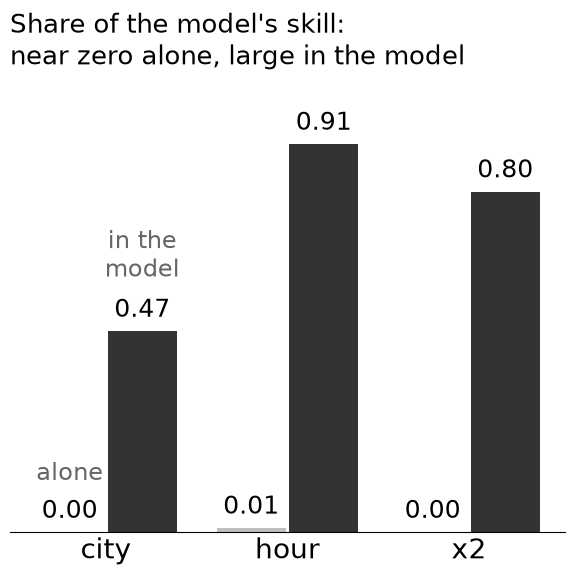

In [12]:
c = P2["C"]
skill_a, skill_b = aucs_a["all five columns"] - 0.5, aucs_b["all five columns"] - 0.5
gap = pd.DataFrame({
    "alone": [(tab_a.loc["city", "AUC alone"] - 0.5) / skill_a,
              (tab_b.loc["hour", "AUC alone"] - 0.5) / skill_b,
              c["R2 x2"] / c["R2 x1 + x2"]],
    "in model": [tab_a.loc["city", "drop-col dAUC"] / skill_a,
                 tab_b.loc["hour", "drop-col dAUC"] / skill_b,
                 (c["R2 x1 + x2"] - c["R2 x1"]) / c["R2 x1 + x2"]],
}, index=["city", "hour", "x2"])
print(gap.round(3).to_string())

fig, ax = plt.subplots(figsize=(6, 6))
xs = np.arange(len(gap))
ax.bar(xs - 0.2, gap["alone"].clip(lower=0), 0.38, color="0.75")
ax.bar(xs + 0.2, gap["in model"], 0.38, color="0.2")
for x, (a, b) in zip(xs, gap.to_numpy()):
    ax.text(x - 0.2, max(a, 0) + 0.02, f"{round(a, 2) + 0:.2f}", ha="center", va="bottom", fontsize=18)
    ax.text(x + 0.2, b + 0.02, f"{b:.2f}", ha="center", va="bottom", fontsize=18)
# series names at the first pair instead of a legend; the value labels replace the y axis
ax.text(-0.2, max(gap["alone"].iloc[0], 0) + 0.11, "alone", ha="center", va="bottom", fontsize=17, color="0.4")
ax.text(0.2, gap["in model"].iloc[0] + 0.11, "in the\nmodel", ha="center", va="bottom", fontsize=17, color="0.4")
ax.set_xticks(xs, gap.index, fontsize=20)
ax.tick_params(axis="x", length=0)
ax.set_yticks([])
ax.spines["left"].set_visible(False)
ax.set_ylim(0, 1.08)
ax.set_title("Share of the model's skill:\nnear zero alone, large in the model", fontsize=19, loc="left")
fig.tight_layout()
fig.savefig("standalone_tests_gap.png")
plt.show()

## Part 3: what to use instead

**Question.** You must cut a pool of candidate features to a short list, and the model that
follows learns interactions. Which cheap selection methods keep the features that matter only in
combination?

**Methods.** Each gives one score per column; columns are ranked by score (1 = best). Ties get
the worst rank of the tie, and a column a method never ranks gets the last rank, so a tie never
favors a method.

| Method | What it is |
|---|---|
| MI | mutual information, standalone test |
| F test | chi-square for categorical columns, ANOVA F-test otherwise, ranked by p-value |
| IV | information value, standalone test |
| mRMR F | mRMR (minimum redundancy, maximum relevance): a greedy order that picks, at each step, the column with the highest relevance divided by its mean absolute correlation with the columns already picked; relevance is the ANOVA F statistic |
| mRMR RF | the same with relevance from the random forest below (its impurity importance) |
| RF impurity | random forest, mean decrease in impurity |
| RF permutation | permutation importance of the same forest: the drop in holdout AUC when one column is shuffled, 5 repeats |
| CB PVC | CatBoost `PredictionValuesChange`, the default of `get_feature_importance()`: how much the predictions change, on average, across the splits on a column, from the training data |
| CB SHAP | mean absolute SHAP value of the column, CatBoost model on the holdout |
| CB LFC | CatBoost `LossFunctionChange` on the holdout: how much the loss grows when the column's contribution is removed from the trees, without a refit |
| CB permutation | permutation importance of the CatBoost model on the holdout, 5 repeats |
| Drop-column | holdout AUC of CatBoost minus that of CatBoost retrained without the column (Part 2 uses out-of-fold AUC; Part 3 uses one holdout to keep the cost down) |

mRMR is implemented here in about 15 lines, so that it sees the same inputs as the other methods:
the score is relevance divided by the mean absolute correlation with the columns already picked,
with a floor of 0.001, and categorical columns enter as raw integer ids, as the forest sees them.
mRMR RF takes its relevance from the forest of RF impurity. Part 4c compares this with the
`mrmr_selection` library.

**Fixed settings.** Random forest: `n_estimators=300, min_samples_leaf=20, max_features="sqrt",
random_state=seed`. CatBoost: the Part 2 setup. One stratified 70/30 split per seed: the forest,
CatBoost and the standalone tests use the 70% part, and permutation importance, LFC and the
drop-column AUC use the 30% part. City ids are relabeled as in the coding check, so no method gets
the ordered ids; the ordered coding appears only in Part 2. Nothing was tuned.

**Blocks.**

- **3a, strength.** Cases A, B and D, five columns each (two real, three noise), N = 40,000,
  seeds 6000-6004. Case D is a pure XOR: `u` and `v` are independent N(0, 1), the logit (log-odds) term is
  `1.5 * sign(u) * sign(v)`, and neither column has any standalone effect. In A and B one feature
  of the pair has a standalone effect a tree can split on first; D has none. The joint term
  is multiplied by s in {1, 0.5, 0.25, 0.1} (the 8 in A, the 2.5 in B, the 1.5 in D). At s = 1, A
  and B are the Part 1 generators with relabeled city ids.
- **3b, mixed pool.** 8 additive features (logit coefficients +0.4 and -0.4), the pairs of A, B
  and D at s = 1, 150 Gaussian and 32 four-level noise columns: 8 + 6 + 182 = 196 columns. The
  logit intercept is -1 (base rate about 0.39).
  N = 20,000, seeds 6100-6102. Adds each method's usual cutoff, a shadow cutoff and drop-column
  on a CatBoost shortlist (defined in 3b). City, hour, `u` and `v` are called interaction-only
  features below: none has a standalone signal by construction (hour has a small one in the pool,
  see the Summary), and each matters only together with its partner. For hour, `u` and `v` that
  joint effect is an interaction; for city it is additive in the logit, as in case A. Some
  hypotheses below, fixed before this was noted, call the city effect an interaction too.
- **3c, main effect.** Standalone tests only: A and B with a small main effect (one that moves the
  acceptance rate by itself) added to city or hour, to show where a standalone test starts to keep the weak feature.
- **3d, correlated copy.** Case B plus a copy of distance with correlation 0.95, to show what a
  correlated column does to each score.

**Metrics** (3a): rank of the weak feature (city, hour; in D the worse of `u` and `v`), rank of
the strong one, "found" = both real features in the top 2, the number of columns to keep so that
both are kept (the larger of the two ranks), the AUC of CatBoost trained on the method's top 2 and
scored on a fresh draw (seed + 500), the margin, and wall time. The margin is the weak feature's
score minus the largest noise score, divided by the standard deviation of the three noise scores,
for methods whose scores are importances: below 0 means some noise column scores higher.

**Chance baselines.** A method that ranks the strong feature first and orders the rest at random
puts the weak feature in the top 2 with probability 1/4, so it misses with probability 3/4; this
is the relevant baseline for the standalone tests in A and B, which rank the strong feature first
in most runs. Missing in all five seeds of a cell then has probability 0.75^5 = 0.24. In D the weak feature is the worse of two symmetric features, and a random order misses
with probability 9/10, and in all five seeds with probability 0.59.

**Hypotheses, fixed before the run.** "Miss" means the weak feature ranks below 2 of 5 (3a), or
below 30 of 196 (3b).

- **H1 (control).** MI, the F test and IV miss city, hour, `u` and `v` at every strength: the weak
  feature in every seed of every case and strength of 3a, and all four features in every seed of
  3b. This bar is strict: by the chance baselines above, a method that is blind to the weak
  feature still finds it in some seed of most cells.
- **H2.** In A at s = 1, mRMR RF ranks city lower than RF impurity alone in at least 4 of 5 seeds:
  the redundancy term, not the forest, loses city.
- **H3.** In A at s = 0.25 and s = 0.1, RF impurity ranks city lower than RF permutation in at
  least 4 of 5 seeds.
- **H4** (the forest's `max_features`) is not tested in Part 3 (5b tests it as H22), and the
  optional CMIM method is not run in Part 3 (it runs in 4c).
- **H5.** In A at s = 0.25, CB PVC misses city in at least 4 of 5 seeds, while CB LFC and CB
  permutation miss it in at most 1. (This was seen on seeds 5000 and 5001 before this run.)
- **H6.** In 3b the shadow cutoff keeps at most twice the number of noise columns expected by
  chance, and recalls at least 12 of the 14 useful features, on average over seeds (and over 5
  shuffles per seed).
- **H7.** In 3a, drop-column and CB permutation agree on the top 2 in every seed where the weak
  feature's drop-column loss is above 3 standard deviations of the refit noise (the larger of the
  two in Part 2).

In [13]:
CITY_MAIN = np.array([-1, -1 / 3, 1 / 3, 1])  # per-level main effect of city in 3c, ordered by price level


N3 = 20_000 if QUICK else N  # rows in the Part 3 generators


def gen_a3(seed, s=1.0, main=0.0, n=N3):
    """gen_a with the interaction scaled by s, an optional main effect of city, relabeled city ids."""
    rng = np.random.default_rng(seed)
    city = rng.integers(0, 4, n)
    log_price = CITY_LEVELS[city] + rng.normal(0, 0.25, n)
    p = 1 / (1 + np.exp(-(8 * s * (log_price - CITY_LEVELS[city]) + main * CITY_MAIN[city])))
    y = rng.binomial(1, p)
    df = add_noise(pd.DataFrame({"log_price": log_price, "city": CITY_RELABEL[city]}), rng)
    return df, y, p


def gen_b3(seed, s=1.0, main=0.0, n=N3):
    """gen_b with the interaction scaled by s and an optional main effect of hour."""
    rng = np.random.default_rng(seed)
    hour = rng.uniform(0, 24, n)
    distance_km = rng.lognormal(mean=np.log(6), sigma=0.6, size=n)
    z = (np.log(distance_km) - np.log(6)) / 0.6
    night = np.cos(2 * np.pi * hour / 24)
    p = 1 / (1 + np.exp(-(0.3 * z + 2.5 * s * night * z + main * night)))
    y = rng.binomial(1, p)
    df = add_noise(pd.DataFrame({"distance_km": distance_km, "hour": hour}), rng)
    return df, y, p


def gen_d3(seed, s=1.0, n=N3):
    """Pure XOR: neither u nor v has any standalone effect."""
    rng = np.random.default_rng(seed)
    u, v = rng.normal(size=n), rng.normal(size=n)
    p = 1 / (1 + np.exp(-1.5 * s * np.sign(u) * np.sign(v)))
    y = rng.binomial(1, p)
    df = add_noise(pd.DataFrame({"u": u, "v": v}), rng)
    return df, y, p


METHODS = ["MI", "F test", "IV", "mRMR F", "mRMR RF", "RF impurity", "RF permutation",
           "CB PVC", "CB SHAP", "CB LFC", "CB permutation", "Drop-column"]
IMPORTANCE_METHODS = [m for m in METHODS if not m.startswith("mRMR")]  # scores comparable as a ratio


def rank_of(score):
    # 1 = best; ties get the worst rank of the tie; unranked (NaN) columns get the last rank
    return score.rank(ascending=False, method="max").fillna(len(score))


def split(X, y, seed):
    # the stratified 70/30 split used everywhere: Xtr, Xte, ytr, yte
    return train_test_split(X, y, test_size=0.3, random_state=seed, stratify=y)


def found_count(G, m, case, s):
    # seeds in which method m keeps both real features, in one case and strength
    return int(G[(G.method == m) & (G.case == case) & (G.s == s)].found.sum())


def mrmr_order(X, relevance):
    # Own mRMR (MIQ form): relevance / mean |corr| with the picked columns, |corr| floored at 0.001.
    # Columns with zero relevance are never picked. Returns a score: higher = picked earlier.
    keep = [c for c in X.columns if relevance[c] > 0]
    corr = np.clip(np.abs(np.corrcoef(X[keep].to_numpy(dtype=float), rowvar=False)), 0.001, None)
    rel = relevance[keep].to_numpy()
    red, left, order = np.zeros(len(keep)), np.ones(len(keep), bool), []
    for _ in keep:
        score = rel / (red / len(order)) if order else rel.copy()
        j = int(np.argmax(np.where(left, score, -np.inf)))
        order.append(j)
        left[j] = False
        red += corr[:, j]
    return pd.Series({keep[j]: -i for i, j in enumerate(order)}).reindex(X.columns)


def make_rf(seed):
    return RandomForestClassifier(n_estimators=300, min_samples_leaf=20, max_features="sqrt",
                                  n_jobs=N_JOBS, random_state=seed)


def fit_cb(Xtr, ytr, cats):
    return make_model([c for c in cats if c in Xtr]).fit(Xtr, ytr)


def holdout_auc(Xtr, ytr, Xte, yte, cats):
    return roc_auc_score(yte, fit_cb(Xtr, ytr, cats).predict_proba(Xte)[:, 1])


def perm(model, X, y, seed, repeats=5):
    # permutation importance on (X, y): mean drop in AUC and its standard error over the repeats
    r = permutation_importance(model, X, y, scoring="roc_auc", n_repeats=repeats, random_state=seed)
    return (pd.Series(r.importances_mean, index=X.columns),
            pd.Series(r.importances.std(axis=1, ddof=1) / np.sqrt(repeats), index=X.columns))


def lfc(model, X, y, cats):
    pool = Pool(X, y, cat_features=[c for c in cats if c in X])
    return pd.Series(model.get_feature_importance(pool, type="LossFunctionChange"), index=X.columns)


def drop_scores(Xtr, ytr, Xte, yte, cats, base):
    # holdout AUC lost when each column is removed and CatBoost is refit; base = AUC with all columns
    return pd.Series({c: base - holdout_auc(Xtr.drop(columns=c), ytr, Xte.drop(columns=c), yte, cats) for c in Xtr})


def standalone_scores(Xtr, ytr, cats, seed):
    S, T = {}, {}
    with timed("MI", T):
        S["MI"] = pd.Series(mutual_info_classif(Xtr, ytr, discrete_features=[c in cats for c in Xtr],
                                                random_state=seed), index=Xtr.columns)
    with timed("F test", T):
        S["F test"] = pd.Series({c: -standalone_logp(Xtr[c], ytr, c in cats) for c in Xtr})
    with timed("IV", T):
        S["IV"] = pd.Series({c: information_value(Xtr[c], ytr) for c in Xtr})
    return S, T


def score_methods(Xtr, ytr, Xte, yte, cats, seed, shortlist=None):
    # One score per column for every method (higher = more important), its wall time in seconds,
    # and the standard error of the permutation importances.
    # shortlist=None: drop-column on every column; shortlist=k: on the CB LFC top k only, refit on those k.
    S, T = standalone_scores(Xtr, ytr, cats, seed)
    SE = {}
    with timed("mRMR F", T):
        S["mRMR F"] = mrmr_order(Xtr, pd.Series(f_classif(Xtr, ytr)[0], index=Xtr.columns))
    with timed("RF impurity", T):
        rf = make_rf(seed).fit(Xtr, ytr)
        S["RF impurity"] = pd.Series(rf.feature_importances_, index=Xtr.columns)
    with timed("mRMR RF", T):
        S["mRMR RF"] = mrmr_order(Xtr, S["RF impurity"])
    with timed("RF permutation", T):
        S["RF permutation"], SE["RF permutation"] = perm(rf, Xte, yte, seed)
    with timed("CB PVC", T):
        cb = fit_cb(Xtr, ytr, cats)
        S["CB PVC"] = pd.Series(cb.get_feature_importance(), index=Xtr.columns)
    full_auc = roc_auc_score(yte, cb.predict_proba(Xte)[:, 1])
    with timed("CB SHAP", T):
        sv = cb.get_feature_importance(Pool(Xte, yte, cat_features=[c for c in cats if c in Xte]), type="ShapValues")
        S["CB SHAP"] = pd.Series(np.abs(sv[:, :-1]).mean(axis=0), index=Xtr.columns)  # last column: expected value
    with timed("CB LFC", T):
        S["CB LFC"] = lfc(cb, Xte, yte, cats)
    with timed("CB permutation", T):
        S["CB permutation"], SE["CB permutation"] = perm(cb, Xte, yte, seed)
    with timed("Drop-column", T):
        cols = list(Xtr.columns) if shortlist is None else list(S["CB LFC"].nlargest(shortlist).index)
        base = full_auc if shortlist is None else holdout_auc(Xtr[cols], ytr, Xte[cols], yte, cats)
        S["Drop-column"] = drop_scores(Xtr[cols], ytr, Xte[cols], yte, cats, base).reindex(Xtr.columns)
    for m in ("mRMR RF", "RF permutation"):                 # these reuse the forest
        T[m] += T["RF impurity"]
    for m in ("CB SHAP", "CB LFC", "CB permutation", "Drop-column"):   # these reuse the CatBoost model
        T[m] += T["CB PVC"]
    return S, T, SE, full_auc


def seeds_str(values):
    # per-seed values as "a,b,c"
    return ",".join(str(int(v)) for v in values)


def top2(score, real):
    # the method's top 2 columns; a tie goes to the noise column
    return tuple(sorted(score.index, key=lambda c: (-np.nan_to_num(score[c], nan=-np.inf), c in real))[:2])

### 3a: strength of the joint effect

In [14]:
CASES = {"A": (gen_a3, "city", "log_price", ("city",), False),
         "B": (gen_b3, "hour", "distance_km", (), False),
         "D": (gen_d3, "v", "u", (), True)}   # symmetric: the weak feature is whichever of u and v ranks worse


def roles(score, weak, strong, symmetric):
    # (weak, strong) columns for this score
    r = rank_of(score)
    return (strong, weak) if symmetric and r[strong] > r[weak] else (weak, strong)


rows, effect = [], []
with timed("Part 3a"):
    for case, (gen, weak, strong, cats, symmetric) in CASES.items():
        for s in STRENGTHS:
            for seed in STRENGTH_SEEDS:
                df, y, p = gen(seed, s)
                Xtr, Xte, ytr, yte = split(df, y, seed)
                S, T, SE, full = score_methods(Xtr, ytr, Xte, yte, cats, seed)
                fresh, fresh_y, _ = gen(seed + FRESH_OFFSET, s)
                drop = S["Drop-column"]
                effect.append(dict(case=case, s=s, seed=seed, oracle=roc_auc_score(yte, p[Xte.index]), model=full,
                                   drop_weak=drop[roles(drop, weak, strong, symmetric)[0]]))
                cache = {}
                for m in METHODS:
                    r = rank_of(S[m])
                    wm, sm = roles(S[m], weak, strong, symmetric)
                    w, st = r[wm], r[sm]
                    weak_score = S[m][wm]
                    sel = top2(S[m], (weak, strong))
                    key = frozenset(sel)
                    if key not in cache:
                        cols = sorted(key)
                        cache[key] = holdout_auc(Xtr[cols], ytr, fresh[cols], fresh_y, cats)
                    noise_sd = S[m][NOISE].std()
                    rows.append(dict(case=case, s=s, seed=seed, method=m, weak_rank=w, strong_rank=st,
                                     k_both=max(w, st), found=max(w, st) <= 2, top2=key,
                                     top2_auc=cache[key], seconds=T[m], drop_weak=effect[-1]["drop_weak"],
                                     margin=(weak_score - S[m][NOISE].max()) / noise_sd
                                     if m in IMPORTANCE_METHODS and noise_sd > 0 else np.nan))
R3 = pd.DataFrame(rows)
E3 = pd.DataFrame(effect)
print("Effect size per case and strength (medians over seeds): holdout AUC of the true probability, of CatBoost,")
print("and the drop-column loss of the weak feature")
print(E3.groupby(["case", "s"])[["oracle", "model", "drop_weak"]].median().round(3).unstack("s").to_string())

Effect size per case and strength (medians over seeds): holdout AUC of the true probability, of CatBoost,
and the drop-column loss of the weak feature
     oracle                       model                      drop_weak                     
s      0.10   0.25   0.50   1.00   0.10   0.25   0.50   1.00      0.10   0.25   0.50   1.00
case                                                                                       
A     0.556  0.632  0.737  0.859  0.534  0.621  0.731  0.857     0.020  0.073  0.129  0.174
B     0.590  0.625  0.707  0.817  0.571  0.611  0.699  0.813     0.004  0.060  0.154  0.286
D     0.536  0.590  0.676  0.816  0.525  0.585  0.676  0.816     0.017  0.084  0.174  0.312


In [15]:
def found_table(R, s):
    g = R[R.s == s].groupby(["method", "case"])
    cell = g.apply(lambda d: f"{int(d.found.sum())}/{len(d)} [{d.weak_rank.median():g}]")
    return cell.unstack("case").reindex(METHODS)


for s in STRENGTHS:
    print(f"s = {s}: found (both real features in the top 2) in x of {len(STRENGTH_SEEDS)} seeds [median rank of the weak feature]")
    print(found_table(R3, s).to_string(), "\n")

s = 1: found (both real features in the top 2) in x of 5 seeds [median rank of the weak feature]
case                  A        B        D
method                                   
MI              1/5 [4]  1/5 [4]  0/5 [5]
F test          1/5 [3]  0/5 [4]  2/5 [4]
IV              0/5 [5]  2/5 [3]  1/5 [3]
mRMR F          0/5 [4]  1/5 [4]  1/5 [4]
mRMR RF         0/5 [4]  4/5 [1]  5/5 [2]
RF impurity     5/5 [2]  5/5 [1]  5/5 [2]
RF permutation  5/5 [2]  5/5 [2]  5/5 [2]
CB PVC          5/5 [2]  5/5 [1]  5/5 [2]
CB SHAP         5/5 [1]  5/5 [2]  5/5 [2]
CB LFC          5/5 [1]  5/5 [2]  5/5 [2]
CB permutation  5/5 [2]  5/5 [2]  5/5 [2]
Drop-column     5/5 [2]  5/5 [2]  5/5 [2] 

s = 0.5: found (both real features in the top 2) in x of 5 seeds [median rank of the weak feature]
case                  A        B        D
method                                   
MI              1/5 [4]  1/5 [5]  0/5 [5]
F test          3/5 [2]  2/5 [4]  0/5 [4]
IV              0/5 [5]  1/5 [4]  0/5 [5]
mRMR

Per-seed ranks of the weak feature, so no median hides a failure. Each cell lists all seeds.

In [16]:
per_seed = (R3.groupby(["method", "case", "s"]).weak_rank
            .apply(seeds_str).unstack(["case", "s"]).reindex(METHODS))
for case in CASES:
    print(f"case {case}: weak-feature rank per seed (columns: s)")
    print(per_seed[case].to_string(), "\n")

case A: weak-feature rank per seed (columns: s)
s                    0.10       0.25       0.50       1.00
method                                                    
MI              3,4,2,3,4  2,4,3,4,5  5,4,2,5,4  4,3,2,4,4
F test          5,3,3,4,2  3,4,3,4,2  2,2,3,5,2  4,2,3,4,3
IV              5,5,5,5,5  5,5,5,5,4  4,5,5,5,5  5,4,5,5,5
mRMR F          5,4,4,4,4  3,4,5,4,5  2,4,3,5,5  4,3,5,5,3
mRMR RF         5,5,5,5,5  5,5,5,5,5  5,5,5,5,5  4,4,5,5,3
RF impurity     5,5,5,5,5  5,5,5,5,5  2,2,2,2,2  2,2,2,2,2
RF permutation  2,2,2,2,2  2,2,2,2,2  2,2,2,2,2  2,2,2,2,2
CB PVC          5,5,5,5,5  5,5,5,5,5  2,2,2,2,2  2,2,2,2,2
CB SHAP         2,2,5,2,2  2,2,2,2,2  2,2,2,2,1  1,1,1,2,2
CB LFC          1,2,2,2,1  2,1,1,2,2  2,1,1,2,1  1,1,1,1,1
CB permutation  2,2,2,2,2  2,2,2,2,2  2,2,2,2,2  2,2,2,2,2
Drop-column     2,2,2,2,2  2,2,2,2,2  2,2,2,2,2  2,2,2,2,2 

case B: weak-feature rank per seed (columns: s)
s                    0.10       0.25       0.50       1.00
method           

- The standalone tests and mRMR F find the pair about as often as chance (1 time in 4 in A and B, 1 in 10
  in D); IV in case A finds it less often, mRMR F in case B more often. In case A, IV ranks
  city last in almost every seed: a 4-level column has less estimator bias than 10 bins of a
  continuous noise column. These methods are blind to the weak feature by construction, so this
  block of rows is the control.
- At s = 1, RF impurity, RF permutation and every CatBoost method find the pair in every seed and
  case, including the XOR case D. The weaker strengths are there to change that.
- In case A at s = 0.25 and s = 0.1, RF impurity and CB PVC rank city last of five, below all three
  noise columns, in every seed. Permutation importance (forest and CatBoost), CB LFC and
  drop-column keep city at rank 1 or 2. So does CB SHAP, except in one seed at s = 0.1. The control
  below shows why.
- In B and D, RF impurity, RF permutation and the CatBoost methods miss in at most one seed at any
  strength; mRMR RF misses more often. For these methods case D is about as hard as B (at s = 0.1, CB PVC
  and CB LFC each miss one seed in D, with a lower oracle AUC than B); case A is the hard one.
- mRMR RF loses city in A at s = 1 and s = 0.5, where the forest alone ranks it 2nd. The
  redundancy term does it: in A, city and log_price are dependent by construction (log_price is the
  city level plus noise), and even the relabeled ids keep a correlation with log_price far above
  that of independent columns (see the coding check), so the score divides city's relevance by a
  correlation many times that of a noise column. At s <= 0.25 the forest itself already ranks city last.

**Control: why RF impurity and CB PVC lose city.** Case A at s = 0.25, the same seeds, three
variants. (1) As in 3a. (2) CB LFC and CB permutation computed on the training rows instead of the
holdout, to test whether the training data is the cause. (3) The three Gaussian noise columns
replaced by four-level noise columns (categorical for CatBoost), so that city is no longer the only
column with few distinct values.

In [17]:
ctrl = []
with timed("Part 3a control"):
    for seed in STRENGTH_SEEDS:
        df, y, _ = gen_a3(seed, 0.25)
        rng = np.random.default_rng(seed + AUX_OFFSET)
        df4 = df.assign(**{c: rng.integers(0, 4, len(df)) for c in NOISE})
        for label, d, cats in (("Gaussian noise", df, ["city"]),
                               ("four-level noise", df4, ["city", *NOISE])):
            Xtr, Xte, ytr, yte = split(d, y, seed)
            rf = make_rf(seed).fit(Xtr, ytr)
            cb = fit_cb(Xtr, ytr, cats)
            sc = {"RF impurity": pd.Series(rf.feature_importances_, index=d.columns),
                  "CB PVC": pd.Series(cb.get_feature_importance(), index=d.columns)}
            if label == "Gaussian noise":
                sc["CB LFC, training rows"] = lfc(cb, Xtr, ytr, cats)
                sc["CB permutation, training rows"] = perm(cb, Xtr, ytr, seed)[0]
            for m, v in sc.items():
                ctrl.append(dict(seed=seed, variant=f"{m}, {label}", city_rank=int(rank_of(v)["city"])))
CTRL = pd.DataFrame(ctrl)
print("Rank of city among 5 columns, case A, s = 0.25, per seed")
print(CTRL.groupby("variant", sort=False).city_rank.apply(seeds_str).to_string())

Rank of city among 5 columns, case A, s = 0.25, per seed
variant
RF impurity, Gaussian noise                      5,5,5,5,5
CB PVC, Gaussian noise                           5,5,5,5,5
CB LFC, training rows, Gaussian noise            2,2,2,2,2
CB permutation, training rows, Gaussian noise    2,2,2,2,2
RF impurity, four-level noise                    2,2,2,2,2
CB PVC, four-level noise                         2,2,2,2,2


Computed on the training rows, CB LFC and CB permutation still keep city near the top, so the
training data is not what breaks RF impurity and CB PVC. With four-level noise columns, both
recover city. Impurity-type scores add up gains over many candidate splits, and a column with many
distinct values offers more chances to fit noise; impurity importance is known to favor such
columns (Strobl et al. 2007, [doi 10.1186/1471-2105-8-25](https://doi.org/10.1186/1471-2105-8-25)).
PVC behaves the same way here. For CatBoost the four-level noise columns are also categorical, so
this control changes the number of distinct values and the column type together. Loss-based and permutation scores measure what the model loses
without the column, so they should not have this bias; this control does not test it (for the pool,
see the median ranks of the two noise types in 3b).

In [18]:
print("AUC of CatBoost trained on each method's top 2, scored on a fresh draw (median over seeds)")
print(R3.pivot_table(index="method", columns=["case", "s"], values="top2_auc", aggfunc="median")
      .reindex(METHODS).round(3).to_string(), "\n")
print("Margin: (weak-feature score - largest noise score) / sd of the noise scores (median over seeds; "
      "importance methods only; below 0 = a noise column scores higher)")
print(R3[R3.method.isin(IMPORTANCE_METHODS)].pivot_table(index="method", columns=["case", "s"], values="margin",
      aggfunc="median").reindex(IMPORTANCE_METHODS).round(1).to_string(), "\n")
print("Columns to keep so that both real features are kept (median over seeds, of 5)")
print(R3.pivot_table(index="method", columns=["case", "s"], values="k_both", aggfunc="median")
      .reindex(METHODS).to_string(), "\n")
print("Wall time per method on 28,000 x 5, seconds (median over all cells)")
print(R3.groupby("method").seconds.median().reindex(METHODS).round(2).to_string())

AUC of CatBoost trained on each method's top 2, scored on a fresh draw (median over seeds)
case                A                           B                           D                     
s                0.10   0.25   0.50   1.00   0.10   0.25   0.50   1.00   0.10   0.25   0.50   1.00
method                                                                                            
MI              0.518  0.556  0.613  0.691  0.573  0.566  0.549  0.523  0.499  0.501  0.500  0.498
F test          0.518  0.557  0.736  0.691  0.572  0.568  0.549  0.526  0.500  0.501  0.500  0.499
IV              0.515  0.555  0.611  0.690  0.574  0.566  0.549  0.530  0.499  0.502  0.501  0.501
mRMR F          0.514  0.557  0.611  0.689  0.574  0.619  0.701  0.526  0.499  0.501  0.499  0.499
mRMR RF         0.514  0.554  0.612  0.690  0.580  0.619  0.701  0.811  0.500  0.500  0.678  0.815
RF impurity     0.514  0.554  0.739  0.862  0.580  0.620  0.701  0.811  0.531  0.591  0.678  0.815
RF permutation  0.

When a method misses the weak feature, the AUC of its top 2 on fresh data falls to about the AUC of
the strong feature with a noise column. The margin shows how close each method is to failing. For
the standalone tests it is below 0 in all cells but one. For the forest and CatBoost importances it
falls by one to three orders of magnitude from s = 1 to s = 0.1, and it turns negative for RF
impurity and CB PVC in case A when they fail. On five columns every method takes seconds; the cost matters in the
pool below.

### 3b: mixed pool

In [19]:
ADD_COEF = 0.4 * np.array([1, -1] * 4)
POOL_INTERCEPT = -1.0
ADD_COLS = [f"add_{i + 1}" for i in range(8)]
PAIR_COLS = ["city", "log_price", "hour", "distance_km", "u", "v"]
USEFUL = ADD_COLS + PAIR_COLS
INTER_ONLY = ["city", "hour", "u", "v"]
GAUSS_NOISE = [f"gnoise_{i + 1}" for i in range(150)]
CAT_NOISE = [f"cnoise_{i + 1}" for i in range(32)]
POOL_NOISE = GAUSS_NOISE + CAT_NOISE
POOL_CATS = ["city"] + CAT_NOISE
POOL_COLS = len(USEFUL) + len(POOL_NOISE)


def gen_pool(seed, s=1.0, n=POOL_N):
    # s multiplies the three interaction terms; the additive part does not change
    rng = np.random.default_rng(seed)
    add = rng.normal(size=(n, 8))
    city = rng.integers(0, 4, n)
    log_price = CITY_LEVELS[city] + rng.normal(0, 0.25, n)
    hour = rng.uniform(0, 24, n)
    distance_km = rng.lognormal(mean=np.log(6), sigma=0.6, size=n)
    z = (np.log(distance_km) - np.log(6)) / 0.6
    night = np.cos(2 * np.pi * hour / 24)
    u, v = rng.normal(size=n), rng.normal(size=n)
    logit = (add @ ADD_COEF + 8 * s * (log_price - CITY_LEVELS[city]) + 0.3 * z + 2.5 * s * night * z
             + 1.5 * s * np.sign(u) * np.sign(v) + POOL_INTERCEPT)
    p = 1 / (1 + np.exp(-logit))
    y = rng.binomial(1, p)
    df = pd.DataFrame(add, columns=ADD_COLS).assign(city=CITY_RELABEL[city], log_price=log_price, hour=hour,
                                                      distance_km=distance_km, u=u, v=v)
    df = pd.concat([df, pd.DataFrame(rng.normal(size=(n, 150)), columns=GAUSS_NOISE),
                    pd.DataFrame(rng.integers(0, 4, (n, 32)), columns=CAT_NOISE)], axis=1)
    return df, y, p


PoolSplit = namedtuple("PoolSplit", "df y p Xtr Xte ytr yte fresh fresh_y fresh_p")


def pool_split(seed, s=1.0):
    # a pool dataset, its split and its fresh draw (seed + FRESH_OFFSET)
    df, y, p = gen_pool(seed, s)
    fresh, fresh_y, fresh_p = gen_pool(seed + FRESH_OFFSET, s)
    return PoolSplit(df, y, p, *split(df, y, seed), fresh, fresh_y, fresh_p)


def add_shadows(df, cats, seed, k):
    # shuffle k of every column, as "shadow_<name>"; returns the augmented frame, its categorical columns, the shadows
    rng = np.random.default_rng(seed + AUX_OFFSET + k)
    shadow = df.apply(lambda col: rng.permutation(col.to_numpy())).add_prefix("shadow_")
    return pd.concat([df, shadow], axis=1), list(cats) + ["shadow_" + c for c in cats], list(shadow.columns)


def shadow_cut(df, Xtr, Xte, ytr, yte, seed, k):
    # shadow cutoff with shuffle k: a real column is kept if its LFC beats the largest LFC of any shadow
    aug, aug_cats, shadows = add_shadows(df, POOL_CATS, seed, k)
    cb = fit_cb(aug.loc[Xtr.index], ytr, aug_cats)
    shadow_lfc = lfc(cb, aug.loc[Xte.index], yte, aug_cats)
    return shadow_lfc[df.columns] > shadow_lfc[shadows].max()


def rank_counts(r, rank_cols=INTER_ONLY):
    # useful and interaction-only features in the top 14 and 30, and the rank of each of rank_cols
    return {**{f"useful in top {k}": int((r[USEFUL] <= k).sum()) for k in (14, 30)},
            **{f"interaction-only in top {k}": int((r[INTER_ONLY] <= k).sum()) for k in (14, 30)},
            **{f"rank {c}": int(r[c]) for c in rank_cols}}


def pool_run(seed, s, shuffles):
    # one pool dataset: per-method ranks, each method's own cutoff, and the shadow cutoff over `shuffles` shuffles
    df, y, p, Xtr, Xte, ytr, yte, *_ = pool_split(seed, s)
    print(f"seed {seed}, s = {s:g}: {df.shape[1]} columns, base rate {y.mean():.3f}, ceiling AUC {roc_auc_score(y, p):.3f}")
    S, T, SE, full = score_methods(Xtr, ytr, Xte, yte, POOL_CATS, seed, shortlist=30)
    with timed("Shadow (CB LFC)", T):
        shadow_kept = shadow_cut(df, Xtr, Xte, ytr, yte, seed, 0)
    shadow = []
    for k in range(shuffles):
        kk = shadow_kept if k == 0 else shadow_cut(df, Xtr, Xte, ytr, yte, seed, k)
        shadow.append(dict(seed=seed, s=s, shuffle=k, useful=int(kk[USEFUL].sum()),
                           interaction_only=int(kk[INTER_ONLY].sum()), noise=int(kk[POOL_NOISE].sum())))
    mi = dict(seed=seed, zero=int((S["MI"] == 0).sum()), useful_zero=int((S["MI"][USEFUL] == 0).sum()),
              four_level_noise_positive=int((S["MI"][CAT_NOISE] > 0).sum()))
    ranks = []
    for m in METHODS:
        r = rank_of(S[m])
        ranks.append(dict(seed=seed, s=s, method=m, seconds=T[m], **rank_counts(r, PAIR_COLS),
                          four_level_noise=r[CAT_NOISE].median(), gaussian_noise=r[GAUSS_NOISE].median()))
    kept = {"MI > 0": S["MI"] > 0,
            "F test, BH q < 0.05": pd.Series(false_discovery_control(np.exp(-S["F test"])) < 0.05, index=df.columns),
            "IV >= 0.02": S["IV"] >= 0.02,
            "RF permutation > 2 SE": S["RF permutation"] > 2 * SE["RF permutation"],
            "CB LFC > 0": S["CB LFC"] > 0,
            "CB permutation > 2 SE": S["CB permutation"] > 2 * SE["CB permutation"],
            "Drop-column > 0 (shortlist of 30)": S["Drop-column"] > 0,
            "Shadow (CB LFC)": shadow_kept}
    cuts = [dict(seed=seed, s=s, rule=rule, useful=int(k[USEFUL].sum()), interaction_only=int(k[INTER_ONLY].sum()),
                 noise=int(k[POOL_NOISE].sum()), dropped=" ".join(c for c in USEFUL if not k[c]), kept=" ".join(k.index[k]),
                 seconds=T.get(rule, np.nan)) for rule, k in kept.items()]
    return ranks, cuts, shadow, mi


pool_rows, cut_rows, mi_counts, shadow_rows = [], [], [], []
with timed("Part 3b"):
    for seed in POOL_SEEDS:
        ranks, cuts, shadow, mi = pool_run(seed, 1, SHADOW_REPEATS)
        pool_rows += ranks
        cut_rows += cuts
        shadow_rows += shadow
        mi_counts.append(mi)
P3B = pd.DataFrame(pool_rows)
CUT = pd.DataFrame(cut_rows)
SHADOW = pd.DataFrame(shadow_rows)
EXPECTED_NOISE_KEPT = len(POOL_NOISE) / (POOL_COLS + 1)

seed 6100, s = 1: 196 columns, base rate 0.392, ceiling AUC 0.932


seed 6101, s = 1: 196 columns, base rate 0.393, ceiling AUC 0.929


seed 6102, s = 1: 196 columns, base rate 0.395, ceiling AUC 0.931


In [20]:
POOL_LABEL = {"Drop-column": "Drop-column (LFC top 30)"}
g = P3B.groupby("method", sort=False)
TOPK = (g[["useful in top 14", "useful in top 30", "interaction-only in top 14", "interaction-only in top 30"]]
        .agg(seeds_str).reindex(METHODS).rename(index=POOL_LABEL))
print("Useful features (14) and interaction-only features (4: city, hour, u, v) in each method's top k, per seed")
print(TOPK.to_string(), "\n")
print("Rank among 196 columns of each pair feature, median rank of the 32 four-level and the 150 Gaussian noise\n"
      "columns (medians over seeds), and wall time in seconds")
print(g[[f"rank {c}" for c in PAIR_COLS] + ["four_level_noise", "gaussian_noise", "seconds"]].median()
      .reindex(METHODS).rename(index=POOL_LABEL).round(1).to_string(), "\n")
print("MI per seed: columns with MI exactly 0 (of 196), useful features among them (of 14), "
      "four-level noise columns with MI > 0 (of 32)")
print(pd.DataFrame(mi_counts).set_index("seed").to_string(), "\n")
CUT_TABLE = CUT.groupby("rule", sort=False)[["useful", "interaction_only", "noise"]].agg(seeds_str)
print(f"Each method's own cutoff: features kept, per seed (useful of 14 / interaction-only of 4 / noise of {len(POOL_NOISE)})")
print(CUT_TABLE.to_string())
print("\nUseful features dropped by the F test and IV cutoffs, per seed")
print(CUT[CUT.rule.isin(["F test, BH q < 0.05", "IV >= 0.02"])].pivot(index="seed", columns="rule", values="dropped").to_string())
print(f"\nShadow cutoff: noise columns expected above the largest shadow by chance = {len(POOL_NOISE)}/{POOL_COLS + 1} "
      f"= {EXPECTED_NOISE_KEPT:.2f}; shadow step {CUT.seconds.dropna().median():.0f} s per shuffle")
print(f"Shadow cutoff over {SHADOW_REPEATS} shuffles (the table above shows shuffle 0): noise columns kept, per seed")
print(SHADOW.pivot(index="seed", columns="shuffle", values="noise").assign(mean=lambda d: d.mean(axis=1)).round(2).to_string())
print(f"useful features kept: {SHADOW.useful.min()} to {SHADOW.useful.max()} of 14")

Useful features (14) and interaction-only features (4: city, hour, u, v) in each method's top k, per seed
                         useful in top 14 useful in top 30 interaction-only in top 14 interaction-only in top 30
method                                                                                                          
MI                                  6,4,1            7,4,2                      0,0,0                      0,0,0
F test                           10,10,10         10,11,10                      0,0,0                      0,1,0
IV                               10,10,10         10,10,10                      0,0,0                      0,0,0
mRMR F                           10,10,10         11,11,10                      0,0,0                      1,1,0
mRMR RF                          12,11,12         12,13,13                      2,1,2                      2,3,3
RF impurity                      11,13,12         11,13,13                      1,3,2                  

**Definitions used in this block.**

- **Drop-column (LFC top 30).** Drop-column on 196 columns would take 197 CatBoost fits per seed,
  so here it runs on the 30 columns with the highest CB LFC: one refit of the shortlist plus 30
  drops. Columns outside the shortlist get the last rank, so its recall is limited by the CB LFC
  shortlist, and its cutoff can keep at most 16 noise columns.
- **Usual cutoffs.** MI above 0; the F test at a false discovery rate of 5% (Benjamini-Hochberg
  adjusted p-value, the q-value, below 0.05); IV at least 0.02, the usual credit-scoring floor;
  CB LFC above 0; permutation importance above 2 standard errors (SE) of its 5 repeats. That SE
  covers only the randomness of the shuffles, not of the model, so it is a loose bar.
- **Shadow cutoff.** Every column gets a copy with its values shuffled (a shadow), CatBoost is fit
  on the 392 columns, and a real column is kept if its LFC is above the largest LFC of any shadow.
  A noise column and a shadow are equally likely to score highest, so on average 182 / (196 + 1)
  noise columns pass by chance. One shuffle gives a noisy count, so the step is repeated with 5
  shuffles per seed.

What the tables show:

- No standalone test puts any of the four interaction-only features in its top 14 in any seed
  (in 4a at s = 1, on other seeds, they put up to 2 of the 4 there; hour also has a small
  standalone effect in the pool, see the Summary),
  and the F test and IV with their usual cutoffs keep none of them. The F test keeps the 8
  additive features and the two partners with a standalone effect (log_price, distance_km). IV
  keeps one fewer, and in most seeds the one below its 0.02 floor is distance_km.
- MI keeps fewer useful features in its top 14 than the F test and IV. Its nearest-neighbor
  estimate is exactly 0 for many columns, useful ones included, so the top 14 fills with the
  largest of many noisy estimates. Its "MI > 0" cutoff keeps 1 to 3 interaction-only features, but
  among about 100 noise columns, including all four-level ones, which pass on the plug-in bias
  alone.
- RF impurity and mRMR RF rank city near the bottom, below the median Gaussian noise column and
  next to the four-level noise columns: the effect of the 3a control again.
- CB PVC, CB SHAP, CB LFC, CB permutation and RF permutation put all 14 useful features in their top 14 in
  every seed; at full strength even CB PVC works. Drop-column on the shortlist puts
  13 or 14 in its top 14.
- Cutoffs: CB LFC > 0 and permutation > 2 SE keep every useful feature but also tens of noise
  columns. The shadow cutoff and drop-column on the shortlist keep every useful feature and only a
  few noise columns.
- RF permutation and drop-column on the shortlist take several times longer than CB LFC.

### 3c: a small main effect

Standalone tests only, cases A and B at s = 1 with a main effect added to the weak feature: in A
the logit gets `main * (-1, -1/3, 1/3, 1)` by city price level, in B `main * night`. The rate
spread is the difference between the highest and lowest acceptance rate across cities (A) or
4-hour bins (B). The noise baseline is how often a single noise column makes the top 2.

In [21]:
if QUICK:
    print("Skipped in QUICK mode.")
else:
    main_rows = []
    with timed("Part 3c"):
        for case, gen, weak, cats in [("A", gen_a3, "city", ("city",)), ("B", gen_b3, "hour", ())]:
            for main in MAIN_EFFECTS:
                for seed in MAIN_SEEDS:
                    df, y, _ = gen(seed, 1, main)
                    Xtr, _, ytr, _ = split(df, y, seed)
                    group = Xtr["city"] if case == "A" else (Xtr["hour"] // 4).astype(int)
                    rates = pd.Series(ytr, index=Xtr.index).groupby(group).mean()
                    S, _ = standalone_scores(Xtr, ytr, cats, seed)
                    for m, sc in S.items():
                        r = rank_of(sc)
                        main_rows.append(dict(case=case, main=main, seed=seed, method=m, spread=rates.max() - rates.min(),
                                              weak_top2=r[weak] <= 2, noise_top2=(r[NOISE] <= 2).mean()))
    M3 = pd.DataFrame(main_rows)
    keys = ["case", "main"]
    print(f"Times in the top 2 of 5 over {len(MAIN_SEEDS)} seeds: the weak feature, and a single noise column (average of 3)")
    print(pd.concat({"rate spread": M3.groupby(keys).spread.median().round(3).to_frame("median"),
                     "weak feature in top 2": M3.pivot_table(index=keys, columns="method", values="weak_top2", aggfunc="sum"),
                     "a noise column in top 2": M3.pivot_table(index=keys, columns="method", values="noise_top2",
                                                               aggfunc="sum").round(1)}, axis=1).to_string())

Times in the top 2 of 5 over 10 seeds: the weak feature, and a single noise column (average of 3)
          rate spread weak feature in top 2        a noise column in top 2          
               median                F test  IV MI                  F test   IV   MI
case main                                                                           
A    0.0        0.010                     2   0  2                     2.7  3.3  2.7
     0.1        0.029                    10   7  3                     0.0  1.0  2.3
     0.2        0.064                    10  10  4                     0.0  0.0  2.0
     0.4        0.122                    10  10  9                     0.0  0.0  0.3
B    0.0        0.017                     4   3  5                     2.0  2.3  2.7
     0.1        0.030                     2   7  5                     2.7  1.0  1.3
     0.2        0.058                     0  10  6                     3.3  0.0  2.3
     0.4        0.105                     1  10  8  

- In A, a main effect of city that moves the acceptance rate across cities by a few points is
  enough for the F test to keep city in every seed; IV follows at the next level and MI last.
- In B the F test does not catch the main effect of hour at any level. The effect follows
  `cos(hour)`, which has no linear trend over the day, and the ANOVA F-test on a numeric column
  compares its mean between the two classes, which `cos(hour)` leaves equal. IV, which bins the column, catches it.
- So a standalone test does find a feature with an effect of its own, if the test can see the
  shape of that effect. Two things defeat it: an effect that exists only together with another feature (Part 2),
  and an effect whose shape the test is blind to (hour and the F test here).

### 3d: a correlated copy

Case B at s = 1 plus `distance_copy`, whose log has correlation 0.95 with the log of distance.
Each method scores distance with and without the copy.

In [22]:
if QUICK:
    print("Skipped in QUICK mode.")
else:
    SIGMA_COPY = 0.6 * np.sqrt(1 / 0.95 ** 2 - 1)
    dup_rows = []
    with timed("Part 3d"):
        for seed in DUP_SEEDS:
            df, y, _ = gen_b3(seed)
            noise_copy = np.random.default_rng(seed + AUX_OFFSET).normal(0, SIGMA_COPY, len(df))
            dfc = df.assign(distance_copy=np.exp(np.log(df["distance_km"]) + noise_copy))
            for label, d in (("without copy", df), ("with copy", dfc)):
                Xtr, Xte, ytr, yte = split(d, y, seed)
                cb = fit_cb(Xtr, ytr, ())
                full = roc_auc_score(yte, cb.predict_proba(Xte)[:, 1])
                sc = {"CB LFC": lfc(cb, Xte, yte, ()), "CB permutation": perm(cb, Xte, yte, seed)[0],
                      "Drop-column": drop_scores(Xtr, ytr, Xte, yte, (), full)}
                for m, s_ in sc.items():
                    dup_rows.append(dict(seed=seed, version=label, method=m, distance=s_["distance_km"],
                                         copy=s_.get("distance_copy", np.nan), hour=s_["hour"],
                                         distance_rank=int(rank_of(s_)["distance_km"])))
            if seed == DUP_SEEDS.start:
                print(f"corr(log distance, log copy) = {np.corrcoef(np.log(dfc.distance_km), np.log(dfc.distance_copy))[0, 1]:.3f}")
    D3 = pd.DataFrame(dup_rows)
    print(D3.groupby(["method", "version"])[["distance", "copy", "hour", "distance_rank"]].median().round(4).to_string())

corr(log distance, log copy) = 0.949


                             distance    copy    hour  distance_rank
method         version                                              
CB LFC         with copy       0.0261 -0.0002  0.0364            2.0
               without copy    0.0358     NaN  0.0334            1.0
CB permutation with copy       0.2838  0.0170  0.3022            2.0
               without copy    0.3084     NaN  0.3030            1.0
Drop-column    with copy       0.0191 -0.0004  0.2841            2.0
               without copy    0.3109     NaN  0.2825            1.0


With the copy in the data, the drop-column importance of distance falls to a small fraction of its
value without the copy, and the copy itself gets about zero: dropping either one costs little,
because the other replaces it. Distance still ranks 2nd, so a cutoff on rank keeps it; a cutoff on
size, set from what distance was worth without the copy, would not. Permutation importance keeps
distance high, and CB LFC gives the copy about zero. The post names a cost for correlated
features: permutation importance can split the credit between them. Here it does not (the copy gets
0.017 against 0.284 for distance), because the model leans on distance; drop-column credits
neither.

### Hypotheses

Each verdict is computed from the tables above with the thresholds fixed before the run.

In [23]:
if QUICK:
    print("Skipped in QUICK mode.")
else:
    def misses(case, s, method):
        d = R3[(R3.case == case) & (R3.s == s) & (R3.method == method)]
        return int((d.weak_rank > 2).sum())


    def verdict(passed):
        return "confirmed" if all(passed) else ("not confirmed" if not any(passed) else "partly")


    lines = []
    cells = [(c, s, m) for c in CASES for s in STRENGTHS for m in ("MI", "F test", "IV")]
    ok = [misses(*x) == 5 for x in cells]
    blind = sum((0.9 if CASES[c][4] else 0.75) ** 5 for c, _, _ in cells)  # chance of a miss in all 5 seeds
    pool_ok = {m: bool((P3B[P3B.method == m][[f"rank {c}" for c in INTER_ONLY]] > 30).all(axis=None))
               for m in ("MI", "F test", "IV")}
    lines.append(("H1", verdict(ok + list(pool_ok.values())),
                  f"3a: {sum(ok)} of {len(ok)} (case, strength, method) cells with a miss in all 5 seeds "
                  f"({blind:.1f} expected for a method that ranks the strong feature first and the rest at random); "
                  "3b: all four interaction-only features ranked below 30 in every seed: "
                  + ", ".join(f"{m} {'yes' if v else 'no'}" for m, v in pool_ok.items())))

    a1 = R3[(R3.case == "A") & (R3.s == 1)].pivot(index="seed", columns="method", values="weak_rank")
    n2 = int((a1["mRMR RF"] > a1["RF impurity"]).sum())
    lines.append(("H2", verdict([n2 >= 4]), f"mRMR RF ranks city lower than RF impurity in {n2} of 5 seeds; "
                  f"city ranks: mRMR RF {a1['mRMR RF'].astype(int).tolist()}, RF impurity {a1['RF impurity'].astype(int).tolist()}"))

    ok3, txt3 = [], []
    for s in (0.25, 0.1):
        a = R3[(R3.case == "A") & (R3.s == s)].pivot(index="seed", columns="method", values="weak_rank")
        n = int((a["RF impurity"] > a["RF permutation"]).sum())
        ok3.append(n >= 4)
        txt3.append(f"s={s:g}: {n} of 5")
    lines.append(("H3", verdict(ok3), "RF impurity ranks city below RF permutation in " + "; ".join(txt3)))

    pvc_miss, lfc_miss, cbp_miss = (misses("A", 0.25, m) for m in ("CB PVC", "CB LFC", "CB permutation"))
    lines.append(("H5", verdict([pvc_miss >= 4, lfc_miss <= 1, cbp_miss <= 1]),
                  f"misses of city at s=0.25: CB PVC {pvc_miss}, CB LFC {lfc_miss}, CB permutation {cbp_miss} of 5"))

    lines.append(("H6", verdict([SHADOW.noise.mean() <= 2 * EXPECTED_NOISE_KEPT, SHADOW.useful.mean() >= 12]),
                  f"over {len(SHADOW)} (seed, shuffle) runs the shadow cutoff keeps {SHADOW.noise.mean():.2f} noise columns "
                  f"on average (chance {EXPECTED_NOISE_KEPT:.2f}, bar {2 * EXPECTED_NOISE_KEPT:.2f}; range "
                  f"{SHADOW.noise.min()} to {SHADOW.noise.max()}) and {SHADOW.useful.mean():.1f} of 14 useful features"))

    h7_bar = 3 * P2["refit"].std().max()
    t2 = R3[R3.method.isin(["Drop-column", "CB permutation"])].pivot_table(
        index=["case", "s", "seed"], columns="method", values=["top2", "drop_weak"], aggfunc="first")
    eligible = t2[t2[("drop_weak", "Drop-column")] > h7_bar]
    agree = eligible[("top2", "Drop-column")] == eligible[("top2", "CB permutation")]
    lines.append(("H7", verdict(list(agree)) if len(agree) else "not tested",
                  f"bar {h7_bar:.4f} (out-of-fold refit noise on 40,000 rows, so lenient for a 12,000-row holdout): "
                  f"{len(eligible)} of {len(t2)} (case, strength, seed) "
                  f"runs above it; drop-column and CB permutation agree on the top 2 in {int(agree.sum())} of them; "
                  f"both methods find the pair in {int(R3[R3.method == 'Drop-column'].found.sum())} and "
                  f"{int(R3[R3.method == 'CB permutation'].found.sum())} of {len(t2)} runs"))
    HYP = pd.DataFrame(lines, columns=["hypothesis", "verdict", "evidence"]).set_index("hypothesis")
    with pd.option_context("display.max_colwidth", 200):
        print(HYP.to_string())

              verdict                                                                                                                                                                                                                                                         evidence
hypothesis                                                                                                                                                                                                                                                                            
H1             partly  3a: 14 of 36 (case, strength, method) cells with a miss in all 5 seeds (12.8 expected for a method that ranks the strong feature first and the rest at random); 3b: all four interaction-only features ranked below 30 in every seed: MI yes, F test no, IV yes
H2          confirmed                                                                                                                                      mRMR RF 

## Part 4: stress tests and other filters

Part 3 leaves two gaps: the pool ran on 3 seeds at full strength only, and permutation importance,
CB LFC and drop-column missed at most one seed in 3a and none in the pool, so their limits are unknown. Part 4 adds blocks with new seeds (7100 and up) and leaves the
Part 3 results unchanged.

- **4a, the pool with more seeds and weaker joint effects.** The 196-column pool of 3b on 6 new seeds (7100-7105), at full
  strength and with the three joint terms multiplied by s = 0.25 (the 8 additive features and the `0.3 * z` term do not
  change). All methods of Part 3; the shadow cutoff uses 2 shuffles per seed.
- **4b, where the model-based methods fail.** Cases A and B with 5 columns, N in {2,000, 5,000,
  10,000, 40,000}, s in {0.25, 0.1, 0.05}, seeds 7200-7204. Then 100 noise columns (80 Gaussian, 20
  four-level) at N = 10,000 and s in {0.5, 0.25}, seeds 7300-7304; drop-column runs there on the
  CB LFC top 30, as in the pool.
- **4c, other filters on the 3a data** (same seeds and strengths 1 and 0.25): mRMR from the
  `mrmr_selection` library, mRMR in its original mutual-information form, and two conditional
  mutual information filters, CMIM and JMI. Then CMIM and JMI on the pool.
- **4d, the selectors of the `feature_engine` library** with their defaults and the CatBoost model of
  Part 3: recursive feature elimination (RFE), the probe selector, selection by shuffling, and its
  mRMR. Data of 3a at s = 0.25 and 0.1 (same seeds), then the pool at s = 0.25.
- **4e, three more candidates:** CatBoost's own recursive elimination (`select_features`, by SHAP
  and by LossFunctionChange), MultiSURF (a Relief filter, `skrebate`, built to find interactions
  without a model), and CatBoost's ranking of feature pairs in the pool. Same data as 4d.

Skipped for time: the pool-size scan (cost against 200 to 5,000 columns), real columns with a
synthetic target, and mRMR in mutual-information form on the pool (about 4 minutes per seed in a check run).

**Hypotheses, fixed before the run.**

- **H8.** In 4a at s = 0.25, RF impurity and CB PVC rank city below 30 in more than half of the
  seeds, while RF permutation, CB LFC and CB permutation keep all four interaction-only features in
  their top 30 in at least 80% of the seeds (5 of 6).
- **H9.** In 4a at s = 0.25, the shadow cutoff keeps at least 3 of the 4 interaction-only features,
  on average over seeds and shuffles.
- **H10.** CMIM and JMI pick first by standalone relevance. In A the strong feature is picked first
  in every run, and the filters then find city given price: the pair in at least 4 of 5 seeds at
  s = 1 and at s = 0.25. In B and D a noise column wins the first pick in at least half of the runs,
  and the pair is found only in runs where a pair member was picked first.
- **H11.** CB SHAP finds the pair in A at s = 0.25 in at least 4 of 5 seeds, because SHAP splits an
  interaction between both partners, and in the 3b pool it shows less of the four-level bias of CB
  PVC: the gap between the median rank of the four-level and of the Gaussian noise columns is
  smaller than for CB PVC.

H12 to H15 were written after a timing check of the 4d selectors on two datasets: case A at
s = 0.25, seed 6000, and the pool at seed 7100, s = 0.25. Both are part of the 4d results.

- **H12.** At s = 0.1, RFE keeps both real features in a run exactly when removing the weak feature
  costs more than 0.01 AUC (its drop-column loss in 3a, same data and seed), in at least 12 of the
  15 runs. In B at s = 0.1, where that loss is about 0.004, it loses hour in at least 3 of 5 seeds.
  At s = 0.25 the losses are 0.06 or more, so keeping both there is expected, not tested.
- **H13.** The probe selector with its defaults compares PVC with one Gaussian probe. In A it drops
  city in at least 4 of 5 seeds at s = 0.25 and at s = 0.1; this carries over from 3a, where PVC
  ranks city below all three Gaussian noise columns, so it is not a new test. The new parts: the
  probe is one draw of noise, so at s = 0.25 it keeps on average at least 1 of the 3 noise columns
  (over A, B and D); and in the pool it keeps a smaller share of the 32 four-level noise columns
  than of the 150 Gaussian ones in every seed, because PVC ranks four-level noise lowest (3b).
- **H14.** Selection by shuffling keeps both real features in at least 4 of 5 seeds in every case
  at s = 0.25. Its bar is the mean AUC drop over the 5 columns, so the weak feature passes only if
  its drop is above about a quarter of the strong feature's; in B at s = 0.1 it loses hour in at
  least 3 of 5 seeds.
- **H15.** The `feature_engine` mRMR keeps both real features in A in at most 1 of 5 seeds at each
  strength. City's relevance is near 0 and its redundancy with log_price is large (city sets the
  price level), while a noise column with zero redundancy gets an infinite or undefined score,
  which the selection takes first.

H16 to H18 were written before any 4e run on these data; only a toy XOR check of the two APIs ran.

- **H16.** CatBoost's recursive elimination, ranked by the order of removal, puts both real features
  in its top 2 in at least 4 of 5 seeds in every case at s = 0.25, by SHAP and by LFC. In the pool
  at s = 0.25 both versions keep all four interaction-only features in their top 30 in at least 5
  of 6 seeds, as CB LFC and CB permutation do in one shot (H8).
- **H17.** MultiSURF finds the XOR pair (both in its top 2) in D in at least 4 of 5 seeds at
  s = 0.25, because it compares each row with its nearest neighbors on all columns at once. It
  misses city in A in at least 4 of 5 seeds at s = 0.25: a four-level column can only differ or
  not between neighbors, and in the toy check such columns got the lowest weights.
- **H18.** In the pool at s = 1, each of the three true pairs (city and log_price, hour and
  distance_km, u and v) is among the top 10 of the 19,110 pairs in CatBoost's interaction ranking
  in every seed. At s = 0.25 at least two of the three are in the top 10 in at least 5 of 6 seeds.

### 4a: the pool with more seeds and weaker joint effects

In [24]:
if QUICK:
    print("Skipped in QUICK mode.")
else:
    def pool_tables(P, CUTS, SH):
        g = P.groupby("method", sort=False)
        print("Useful features (of 14) and interaction-only features (of 4) in each method's top 14 and top 30, per seed")
        print(g[["useful in top 14", "useful in top 30", "interaction-only in top 14", "interaction-only in top 30"]]
              .agg(seeds_str).reindex(METHODS).rename(index=POOL_LABEL).to_string(), "\n")
        print("Rank of city and hour among 196 columns, per seed")
        print(g[["rank city", "rank hour"]].agg(seeds_str).reindex(METHODS).rename(index=POOL_LABEL).to_string(), "\n")
        print("Each method's own cutoff: features kept, per seed (useful of 14 / interaction-only of 4 / noise of 182)")
        print(CUTS.groupby("rule", sort=False)[["useful", "interaction_only", "noise"]].agg(seeds_str).to_string(), "\n")
        print(f"Shadow cutoff over {SH.shuffle.nunique()} shuffles per seed, means: noise kept {SH.noise.mean():.2f} "
              f"(chance {EXPECTED_NOISE_KEPT:.2f}), useful kept {SH.useful.mean():.1f} of 14, "
              f"interaction-only kept {SH.interaction_only.mean():.2f} of 4\n")
        t = g.seconds.median().reindex(METHODS).rename(index=POOL_LABEL)
        t["Shadow step, per shuffle"] = CUTS[CUTS.rule == "Shadow (CB LFC)"].seconds.median()
        print("Wall time per method, seconds (median over seeds)")
        print(t.round(1).to_string())


    rows4a, cuts4a, shadow4a = [], [], []
    with timed("Part 4a"):
        for s in POOL2_STRENGTHS:
            for seed in POOL2_SEEDS:
                ranks, cuts, shadow, _ = pool_run(seed, s, POOL2_SHUFFLES)
                rows4a += ranks
                cuts4a += cuts
                shadow4a += shadow
    P4A, CUT4A, SHADOW4A = pd.DataFrame(rows4a), pd.DataFrame(cuts4a), pd.DataFrame(shadow4a)
    for s in POOL2_STRENGTHS:
        print(f"\n----- s = {s:g} -----\n")
        pool_tables(P4A[P4A.s == s], CUT4A[CUT4A.s == s], SHADOW4A[SHADOW4A.s == s])
    print("\nAcceptance rate by 4-hour bin, all 4a seeds pooled (hour's standalone effect in the pool)")
    for s in POOL2_STRENGTHS:
        hy = pd.concat([pd.DataFrame({"bin": (df.hour // 4).astype(int) * 4, "y": y})
                        for df, y, _ in (gen_pool(seed, s) for seed in POOL2_SEEDS)])
        print(f"s = {s:g}:", hy.groupby("bin").y.mean().round(3).to_dict())

seed 7100, s = 1: 196 columns, base rate 0.390, ceiling AUC 0.931


seed 7101, s = 1: 196 columns, base rate 0.398, ceiling AUC 0.929


seed 7102, s = 1: 196 columns, base rate 0.400, ceiling AUC 0.931


seed 7103, s = 1: 196 columns, base rate 0.401, ceiling AUC 0.930


seed 7104, s = 1: 196 columns, base rate 0.399, ceiling AUC 0.926


seed 7105, s = 1: 196 columns, base rate 0.394, ceiling AUC 0.931


... (4 outputs left out)

seed 7104, s = 0.25: 196 columns, base rate 0.323, ceiling AUC 0.800


seed 7105, s = 0.25: 196 columns, base rate 0.328, ceiling AUC 0.807



----- s = 1 -----

Useful features (of 14) and interaction-only features (of 4) in each method's top 14 and top 30, per seed
                           useful in top 14   useful in top 30 interaction-only in top 14 interaction-only in top 30
method                                                                                                              
MI                              3,3,4,4,2,5        6,6,4,5,4,7                1,0,0,0,0,0                1,0,0,1,0,1
F test                    10,11,11,10,11,10  10,12,11,10,11,11                0,1,1,0,1,0                0,2,1,0,1,1
IV                        10,10,11,10,10,10  10,11,11,10,10,10                0,0,1,0,0,0                0,1,1,0,0,0
mRMR F                    10,12,11,10,10,10  10,12,11,10,11,10                0,2,1,0,0,0                0,2,1,0,1,0
mRMR RF                   11,12,12,11,11,11  12,13,12,12,13,12                2,2,2,1,1,1                2,3,2,2,3,2
RF impurity               12,12,13,11,13,12  13,13,13,1

s = 0.25: {0: 0.335, 4: 0.315, 8: 0.322, 12: 0.322, 16: 0.326, 20: 0.335}


### 4b: where the model-based methods fail

Cases A and B with 5 columns as in 3a. Methods: MI (as the standalone reference), RF impurity, RF
permutation, CB PVC, CB SHAP, CB LFC, CB permutation and drop-column. "Found" = both real features
in the top 2. If some method finds the pair in at least 4 of 5 seeds in every cell of the grid, the
grid is extended to N = 1,000 and 500 at s = 0.05.

In [25]:
if QUICK:
    print("Skipped in QUICK mode.")
else:
    GRID_METHODS = ["MI", "RF impurity", "RF permutation", "CB PVC", "CB SHAP", "CB LFC", "CB permutation", "Drop-column"]
    W_GAUSS = GAUSS_NOISE[:80]
    W_CAT = CAT_NOISE[:20]


    def grid_run(case, n, s, seed, wide=False):
        # one 3a-style dataset with n rows; wide=True replaces the 3 noise columns with 80 Gaussian and 20 four-level ones
        gen, weak, strong, cats, _ = CASES[case]
        df, y, _ = gen(seed, s, n=n)
        cats = list(cats)
        if wide:
            rng = np.random.default_rng(seed + AUX_OFFSET)
            df = pd.concat([df[[strong, weak]], pd.DataFrame(rng.normal(size=(n, 80)), columns=W_GAUSS),
                            pd.DataFrame(rng.integers(0, 4, (n, 20)), columns=W_CAT)], axis=1)
            cats += W_CAT
        Xtr, Xte, ytr, yte = split(df, y, seed)
        S, T, _, _ = score_methods(Xtr, ytr, Xte, yte, cats, seed, shortlist=30 if wide else None)
        out = []
        for m in GRID_METHODS:
            r = rank_of(S[m])
            out.append(dict(case=case, n=n, s=s, seed=seed, method=m, weak_rank=r[weak],
                            found=max(r[weak], r[strong]) <= 2, seconds=T[m]))
        return out


    def found_cells(G, methods=GRID_METHODS):
        # "found in x of k [median weak rank]" per method, case and strength
        cell = G.groupby(["method", "case", "s"]).apply(
            lambda d: f"{int(d.found.sum())}/{len(d)} [{d.weak_rank.median():g}]")
        return cell.unstack(["case", "s"]).reindex(methods)


    def cell_ok(G):
        # found in at least 4 of 5 seeds, per method, case, strength and N
        return G.groupby(["method", "case", "s", "n"]).found.sum() >= 4


    grid_rows = []
    with timed("Part 4b grid"):
        for case in ("A", "B"):
            for n in GRID_N:
                for s in GRID_S:
                    for seed in GRID_SEEDS:
                        grid_rows += grid_run(case, n, s, seed)
    GRID = pd.DataFrame(grid_rows)
    never_fail = [m for m in GRID_METHODS if cell_ok(GRID)[m].all()]
    if never_fail:
        print("Never fails in the grid:", ", ".join(never_fail), f"; extending to N = {EXTEND_N} at s = 0.05\n")
        with timed("Part 4b extension"):
            for case in ("A", "B"):
                for n in EXTEND_N:
                    for seed in GRID_SEEDS:
                        grid_rows += grid_run(case, n, 0.05, seed)
        GRID = pd.DataFrame(grid_rows)
    for n in sorted(GRID.n.unique()):
        print(f"N = {n:,}: found in x of 5 seeds [median rank of the weak feature]")
        print(found_cells(GRID[GRID.n == n]).to_string(), "\n")


    def smallest_n(ok):
        # smallest N from which every larger N in the grid also passes
        ok = ok.droplevel(["method", "case", "s"]).sort_index()
        good = [n for n in ok.index if ok.loc[n:].all()]
        return f"{min(good):,}" if good else "none"


    print("Smallest N from which the method finds both features in at least 4 of 5 seeds at every larger N")
    print("(none = not even at N = 40,000)")
    print(cell_ok(GRID).groupby(["method", "case", "s"]).apply(smallest_n).unstack(["case", "s"]).reindex(GRID_METHODS).to_string())

N = 2,000: found in x of 5 seeds [median rank of the weak feature]
case                  A                          B                  
s                  0.05     0.10     0.25     0.05     0.10     0.25
method                                                              
MI              1/5 [3]  0/5 [3]  0/5 [4]  1/5 [4]  2/5 [2]  1/5 [2]
RF impurity     0/5 [5]  0/5 [5]  0/5 [5]  1/5 [5]  2/5 [3]  4/5 [2]
RF permutation  1/5 [3]  1/5 [4]  4/5 [2]  1/5 [4]  1/5 [3]  5/5 [2]
CB PVC          0/5 [5]  0/5 [5]  0/5 [5]  0/5 [5]  2/5 [2]  3/5 [2]
CB SHAP         0/5 [5]  0/5 [5]  2/5 [3]  1/5 [5]  1/5 [4]  4/5 [2]
CB LFC          2/5 [1]  2/5 [1]  5/5 [1]  1/5 [3]  0/5 [3]  3/5 [2]
CB permutation  0/5 [2]  0/5 [3]  5/5 [1]  1/5 [4]  0/5 [3]  4/5 [2]
Drop-column     0/5 [4]  2/5 [2]  3/5 [2]  1/5 [4]  1/5 [4]  5/5 [2] 

N = 5,000: found in x of 5 seeds [median rank of the weak feature]
case                  A                          B                  
s                  0.05     0.10    

In [26]:
if QUICK:
    print("Skipped in QUICK mode.")
else:
    wide_rows = []
    with timed("Part 4b, 100 noise columns"):
        for case in ("A", "B"):
            for s in WIDE_S:
                for seed in WIDE_SEEDS:
                    wide_rows += grid_run(case, WIDE_N, s, seed, wide=True)
    WIDE = pd.DataFrame(wide_rows)
    print("100 noise columns (80 Gaussian, 20 four-level), N = 10,000: found in x of 5 seeds "
          "[median rank of the weak feature among 102]")
    print(found_cells(WIDE).rename(index=POOL_LABEL).to_string(), "\n")
    print("Wall time per method, seconds (median over runs)")
    print(WIDE.groupby("method").seconds.median().reindex(GRID_METHODS).rename(index=POOL_LABEL).round(1).to_string())

100 noise columns (80 Gaussian, 20 four-level), N = 10,000: found in x of 5 seeds [median rank of the weak feature among 102]
case                             A                    B          
s                             0.25      0.50       0.25      0.50
method                                                           
MI                        0/5 [48]  0/5 [49]  0/5 [102]  0/5 [22]
RF impurity               0/5 [82]  0/5 [82]    5/5 [2]   5/5 [1]
RF permutation             2/5 [3]   5/5 [2]    5/5 [2]   5/5 [2]
CB PVC                    1/5 [80]   5/5 [2]    5/5 [2]   5/5 [1]
CB SHAP                    5/5 [2]   5/5 [2]    5/5 [2]   5/5 [2]
CB LFC                     5/5 [2]   5/5 [2]    5/5 [2]   5/5 [2]
CB permutation             5/5 [2]   5/5 [2]    5/5 [2]   5/5 [2]
Drop-column (LFC top 30)   5/5 [2]   5/5 [2]    5/5 [2]   5/5 [2] 

Wall time per method, seconds (median over runs)
method
MI                           0.7
RF impurity                  0.6
RF permutation          

### 4c: other filters on the 3a data

- **Library mRMR.** `mrmr_selection` 0.2.8, `mrmr_classif` with `relevance` "f" or "rf" and
  `redundancy="c"`, categorical columns passed as integer ids (no `cat_features`), so its default
  encoding is not used. Its "rf" relevance is the library's own forest.
- **MID and MIQ.** mRMR in its original form (Peng, Long and Ding 2005): relevance is the mutual
  information of a column with the target, redundancy the mean mutual information with the columns
  already picked; MID takes the difference, MIQ the ratio. Estimates come from scikit-learn's
  nearest-neighbor estimator, with `city` marked as discrete.
- **CMIM and JMI.** Filters that score a column given the ones already picked. CMIM (Fleuret 2004)
  picks the column with the largest minimum, over the picked columns z, of I(x; y | z), the mutual
  information of x and y given z. JMI (Yang and Moody 1999) picks the largest sum of I(x, z; y).
  Both use a plug-in estimate: numeric columns in 10 quantile bins, `city` as it is.

In MID, MIQ, CMIM and JMI, ties go to the column further right, so a noise column wins a tie. The plug-in estimate
is biased upward by about (kx - 1)(ky - 1) kz / (2N) for I(x; y | z), with k the number of cells of
each variable (kz = 1 without z); the next cell prints it for the bins used here.

In [27]:
if QUICK:
    print("Skipped in QUICK mode.")
else:
    def lib_mrmr(Xtr, ytr, relevance):
        sel = mrmr_classif(Xtr, pd.Series(ytr, index=Xtr.index), K=Xtr.shape[1], relevance=relevance,
                           redundancy="c", show_progress=False)
        return pd.Series({c: -i for i, c in enumerate(sel)}).reindex(Xtr.columns)


    def mi_pair(a, b, a_cat, b_cat, seed):
        # nearest-neighbor mutual information of column a with column b, b used as the target
        f = mutual_info_classif if b_cat else mutual_info_regression
        return f(a.to_numpy().reshape(-1, 1), b.to_numpy(), discrete_features=[a_cat], random_state=seed)[0]


    def mrmr_mi(X, y, cats, seed, form, cache):
        # mRMR in MID (difference) or MIQ (ratio) form; returns a score, higher = picked earlier
        rel = pd.Series(mutual_info_classif(X, y, discrete_features=[c in cats for c in X], random_state=seed), index=X.columns)
        red, picked, left = pd.Series(0.0, index=X.columns), [], list(X.columns)
        while left:
            if picked:
                mean_red = red[left] / len(picked)
                score = rel[left] - mean_red if form == "MID" else rel[left] / mean_red.clip(lower=1e-6)
            else:
                score = rel[left]
            j = score[::-1].idxmax()                    # a tie goes to the column further right
            picked.append(j)
            left.remove(j)
            for c in left:
                if (c, j) not in cache:
                    cache[(c, j)] = mi_pair(X[c], X[j], c in cats, j in cats, seed)
                red[c] += cache[(c, j)]
        return pd.Series({c: -i for i, c in enumerate(picked)}).reindex(X.columns)


    def plug_in_codes(X, cats, bins=10):
        return {c: (X[c].to_numpy() if c in cats else pd.qcut(X[c], bins, labels=False, duplicates="drop").to_numpy())
                .astype(np.int64) for c in X}


    def H(*cols):
        # plug-in entropy of the joint distribution of integer columns, in nats
        code = np.zeros(len(cols[0]), np.int64)
        for c in cols:
            code = code * (c.max() + 1) + c
        p = np.bincount(code)
        p = p[p > 0] / len(code)
        return -(p * np.log(p)).sum()


    def cmi_filter(D, y, k, form):
        # greedy CMIM or JMI on plug-in estimates; returns a score, higher = picked earlier
        first = pd.Series({c: H(D[c]) + H(y) - H(D[c], y) for c in D})
        acc = pd.Series(np.inf if form == "CMIM" else 0.0, index=first.index)
        picked, left = [], list(D)
        while left and len(picked) < k:
            score = acc[left] if picked else first[left]
            j = score[::-1].idxmax()                    # a tie goes to the column further right
            picked.append(j)
            left.remove(j)
            for c in left:
                if form == "CMIM":                      # I(x; y | z), minimum over the picked z
                    acc[c] = min(acc[c], H(D[c], D[j]) + H(y, D[j]) - H(D[c], y, D[j]) - H(D[j]))
                else:                                   # I(x, z; y), sum over the picked z
                    acc[c] += H(D[c], D[j]) + H(y) - H(D[c], D[j], y)
        return pd.Series({c: -i for i, c in enumerate(picked)}).reindex(list(D))


    for n_tr in (int(0.7 * N), int(0.7 * POOL_N)):
        print(f"plug-in bias with {n_tr:,} training rows: I(x; y) {9 / (2 * n_tr):.5f} for a 10-bin x, "
              f"{3 / (2 * n_tr):.5f} for a 4-level x; I(x; y | z) with a 10-bin z: {90 / (2 * n_tr):.5f} and "
              f"{30 / (2 * n_tr):.5f}")

    ALT = ["mRMR F", "lib mRMR F", "mRMR RF", "lib mRMR RF", "MID", "MIQ", "CMIM", "JMI"]
    alt_rows = []
    with timed("Part 4c"):
        for case, (gen, weak, strong, cats, symmetric) in CASES.items():
            for s in (1, 0.25):
                for seed in STRENGTH_SEEDS:
                    df, y, _ = gen(seed, s)
                    Xtr, _, ytr, _ = split(df, y, seed)
                    S = {"mRMR F": mrmr_order(Xtr, pd.Series(f_classif(Xtr, ytr)[0], index=Xtr.columns)),
                         "mRMR RF": mrmr_order(Xtr, pd.Series(make_rf(seed).fit(Xtr, ytr).feature_importances_,
                                                              index=Xtr.columns))}
                    S["lib mRMR F"], S["lib mRMR RF"] = lib_mrmr(Xtr, ytr, "f"), lib_mrmr(Xtr, ytr, "rf")
                    cache = {}
                    S["MID"], S["MIQ"] = (mrmr_mi(Xtr, ytr, cats, seed, f, cache) for f in ("MID", "MIQ"))
                    D = plug_in_codes(Xtr, cats)
                    S["CMIM"], S["JMI"] = (cmi_filter(D, ytr, Xtr.shape[1], f) for f in ("CMIM", "JMI"))
                    for m, sc in S.items():
                        w, st = roles(sc, weak, strong, symmetric)
                        r = rank_of(sc)
                        alt_rows.append(dict(case=case, s=s, seed=seed, method=m, weak_rank=r[w],
                                             found=max(r[w], r[st]) <= 2, first=sc.idxmax(),
                                             order=" ".join(sc.dropna().sort_values(ascending=False).index)))
    ALT4 = pd.DataFrame(alt_rows)
    print("\nFound in x of 5 seeds [median rank of the weak feature]")
    print(found_cells(ALT4, ALT).to_string(), "\n")

    o = ALT4.pivot_table(index=["case", "s", "seed"], columns="method", values="order", aggfunc="first")
    for own, lib in (("mRMR F", "lib mRMR F"), ("mRMR RF", "lib mRMR RF")):
        diff = o[o[own] != o[lib]]
        print(f"{own} and {lib}: the same order in {len(o) - len(diff)} of {len(o)} runs")
        for idx, r in diff.head(6).iterrows():
            print(f"  {idx}: own [{r[own]}]  library [{r[lib]}]")

    print("\nFirst pick of CMIM and JMI (same for both, since the first step uses I(x; y) only), per seed")
    for (case, s), picks in ALT4[ALT4.method == "CMIM"].groupby(["case", "s"])["first"]:
        print(f"  {case}, s = {s:g}: {', '.join(picks)}")

plug-in bias with 28,000 training rows: I(x; y) 0.00016 for a 10-bin x, 0.00005 for a 4-level x; I(x; y | z) with a 10-bin z: 0.00161 and 0.00054
plug-in bias with 14,000 training rows: I(x; y) 0.00032 for a 10-bin x, 0.00011 for a 4-level x; I(x; y | z) with a 10-bin z: 0.00321 and 0.00107



Found in x of 5 seeds [median rank of the weak feature]
case               A                 B                 D         
s               0.25     1.00     0.25     1.00     0.25     1.00
method                                                           
mRMR F       0/5 [4]  0/5 [4]  3/5 [2]  1/5 [4]  1/5 [4]  1/5 [4]
lib mRMR F   0/5 [4]  0/5 [4]  3/5 [2]  1/5 [4]  1/5 [4]  1/5 [4]
mRMR RF      0/5 [5]  0/5 [4]  3/5 [1]  4/5 [1]  1/5 [4]  5/5 [2]
lib mRMR RF  0/5 [5]  0/5 [4]  5/5 [2]  4/5 [1]  2/5 [4]  4/5 [2]
MID          0/5 [5]  0/5 [5]  1/5 [4]  1/5 [3]  0/5 [4]  0/5 [4]
MIQ          1/5 [4]  1/5 [4]  1/5 [4]  1/5 [4]  0/5 [5]  0/5 [5]
CMIM         5/5 [2]  5/5 [2]  5/5 [2]  5/5 [2]  1/5 [3]  4/5 [2]
JMI          5/5 [2]  5/5 [2]  5/5 [2]  5/5 [2]  1/5 [3]  4/5 [2] 

mRMR F and lib mRMR F: the same order in 30 of 30 runs
mRMR RF and lib mRMR RF: the same order in 16 of 30 runs
  ('A', 0.25, 6000): own [log_price noise_1 noise_2 noise_3 city]  library [log_price noise_1 noise_3 n

In [28]:
if QUICK:
    print("Skipped in QUICK mode.")
else:
    # The library's default encoding of a categorical column, on a column with no link to the target
    rng = np.random.default_rng(LEAK_SEED)
    Xl = pd.DataFrame({"x1": rng.normal(size=N), "x2": rng.normal(size=N), "c": rng.integers(0, 4, N)})
    yl = pd.Series(rng.integers(0, 2, N))
    for label, kw in (("c as integer ids", {}), ('c as cat_features (default cat_encoding="leave_one_out")',
                                                 {"cat_features": ["c"]})):
        sel, rel, _ = mrmr_classif(Xl, yl, K=3, relevance="rf", return_scores=True, show_progress=False, **kw)
        print(f"{label}: order {sel}, forest relevance {rel.round(3).to_dict()}")
    enc = ce.LeaveOneOutEncoder(cols=["c"]).fit_transform(Xl[["c"]], yl)
    print("distinct encoded values per level of c:", enc.groupby(Xl.c).c.nunique().to_dict(),
          "; accuracy of a depth-3 tree on the encoded c alone, training rows:",
          round(DecisionTreeClassifier(max_depth=3, random_state=0).fit(enc, yl).score(enc, yl), 3))

c as integer ids: order ['x1', 'x2', 'c'], forest relevance {'x1': 0.449, 'x2': 0.449, 'c': 0.102}


c as cat_features (default cat_encoding="leave_one_out"): order ['c', 'x2', 'x1'], forest relevance {'x1': 0.036, 'x2': 0.031, 'c': 0.933}
distinct encoded values per level of c: {0: 2, 1: 2, 2: 2, 3: 2} ; accuracy of a depth-3 tree on the encoded c alone, training rows: 0.748


Leave-one-out encoding gives each row the target mean of its level without that row. Within a level
the value then differs by class, so each level gets exactly two values, one per class. A tree can
split on that, and the forest relevance of a column with no link to the target jumps. With integer
ids the library does not have this problem, and that is how it runs in the table above.

In [29]:
if QUICK:
    print("Skipped in QUICK mode.")
else:
    cmi_rows = []
    with timed("Part 4c pool"):
        for seed in POOL_SEEDS:
            df, y, _ = gen_pool(seed)
            Xtr, _, ytr, _ = split(df, y, seed)
            D = plug_in_codes(Xtr, POOL_CATS)
            T = {}
            for form in ("CMIM", "JMI"):
                with timed(form, T):
                    sc = cmi_filter(D, ytr, 14, form)
                r = rank_of(sc)
                cmi_rows.append(dict(seed=seed, method=form, seconds=T[form], first=sc.idxmax(),
                                     **{"useful in top 14": int((r[USEFUL] <= 14).sum()),
                                        "interaction-only in top 14": int((r[INTER_ONLY] <= 14).sum())},
                                     **{f"in top 14: {c}": bool(r[c] <= 14) for c in INTER_ONLY}))
    CMI = pd.DataFrame(cmi_rows)
    print("CMIM and JMI on the 3b pool, K = 14, per seed")
    print(CMI.groupby("method")[["useful in top 14", "interaction-only in top 14"]].agg(seeds_str).to_string())
    print(CMI.set_index(["method", "seed"])[[f"in top 14: {c}" for c in INTER_ONLY] + ["first"]].to_string())
    print("seconds per run (median):", CMI.groupby("method").seconds.median().round(1).to_dict())

CMIM and JMI on the 3b pool, K = 14, per seed
       useful in top 14 interaction-only in top 14
method                                            
CMIM           11,11,11                      1,1,1
JMI            12,12,12                      2,2,2
             in top 14: city  in top 14: hour  in top 14: u  in top 14: v      first
method seed                                                                         
CMIM   6100             True            False         False         False  log_price
JMI    6100             True             True         False         False  log_price
CMIM   6101             True            False         False         False  log_price
JMI    6101             True             True         False         False  log_price
CMIM   6102             True            False         False         False  log_price
JMI    6102             True             True         False         False  log_price
seconds per run (median): {'CMIM': 0.4, 'JMI': 0.4}


### 4d: the `feature_engine` selectors

Each selector runs with its defaults on the training rows (it makes its own cross-validation
folds), with the CatBoost model of Part 3 where it needs a model.

- **Probe** (`ProbeFeatureSelection`): add one Gaussian noise column (the probe), fit with 5-fold
  cross-validation, and keep the columns whose mean `feature_importances_` is above the probe's.
  For CatBoost that importance is PVC. One probe is one draw of noise, so how many noise columns
  pass depends on that draw. **Probe all** uses one probe of each of its five distributions
  (Gaussian, binary, uniform, discrete uniform with 10 values, Poisson) and their mean importance
  as the bar.
- **Shuffling** (`SelectByShuffling`): fit with 3-fold cross-validation, shuffle each column once,
  score the fold models on their validation rows, and keep the columns whose AUC drop is above the
  mean drop over all columns. It is close to CB permutation, with a bar that depends on the other
  columns.
- **mRMR** (`MRMR`): the MIQ form, relevance over mean redundancy, both by nearest-neighbor mutual
  information; `city` is treated as continuous (the default). It keeps 20% of the columns: 2 of 5
  here, 39 of 196 in the pool. Mutual information is often exactly 0, so the ratio is often x / 0
  (infinite) or 0 / 0 (undefined), and `argmax` takes the first undefined score before any number,
  then the first infinite one. Which column wins then depends on the column order. **mRMR
  reversed** is the same selector on the columns in reverse order.
- **RFE** (`RecursiveFeatureElimination`): fit on all columns with 3-fold cross-validation and order
  the columns once by the mean `feature_importances_` (PVC) of the three fold models. Then, from the least important, drop each column, refit with 3-fold
  cross-validation and remove it for good if the AUC falls by at most 0.01 from the current model.
  The bar applies per step, so losses below 0.01 can add up over many removals. After each removal
  the library refits the new model once more, which roughly doubles the cost.

`random_state` is set to the data seed (the probe's default is 0; shuffling and mRMR are random by
default). Cost of a selection:
CatBoost refit on the kept columns and scored on a fresh draw (seed + 500, as in 3a), as ROC AUC and
log loss.

In [30]:
if QUICK:
    print("Skipped in QUICK mode.")
else:
    FE_SELECTORS = ["FE probe", "FE probe all", "FE shuffling", "FE MRMR", "FE MRMR reversed", "FE RFE"]
    FE_CHEAP = ["FE probe", "FE probe all", "FE shuffling"]   # run on every pool seed
    FE_S = (0.25, 0.1)
    FE_POOL_S = 0.25
    FE_POOL_ONE_SEED = 7100   # mRMR and RFE run on this pool seed only (minutes, and RFE about 20 minutes)


    def fe_cb(cats):
        # the CatBoost model of Part 3; marks as categorical only the given columns still in X, since RFE drops columns
        class CB(CatBoostClassifier):
            def fit(self, X, y=None, **kw):
                return super().fit(X, y, cat_features=[c for c in cats if c in X], **kw)
        params = make_model().get_params()
        params.pop("cat_features")
        return CB(**params)


    def fe_selector(m, cats, seed):
        if m.startswith("FE probe"):
            return ProbeFeatureSelection(fe_cb(cats), distribution="all" if m == "FE probe all" else "normal",
                                         random_state=seed)
        if m == "FE shuffling":
            return SelectByShuffling(fe_cb(cats), random_state=seed)
        if m.startswith("FE MRMR"):
            return MRMR(random_state=seed, n_jobs=N_JOBS)
        return RecursiveFeatureElimination(fe_cb(cats))


    def refit_cost(Xtr, ytr, fresh, fresh_y, cats, k):
        # ROC AUC and log loss on a fresh draw of CatBoost refit on columns k
        p = fit_cb(Xtr[k], ytr, cats).predict_proba(fresh[k])[:, 1]
        return roc_auc_score(fresh_y, p), log_loss(fresh_y, p)


    def fe_kept(Xtr, ytr, fresh, fresh_y, cats, seed, names=FE_SELECTORS, fixed=None):
        # per selector: (kept columns, wall time, ROC AUC, log loss), the last two from CatBoost refit on the
        # kept columns and scored on a fresh draw; `fixed` adds reference column sets
        kept, T, y = dict(fixed or {}), {}, pd.Series(ytr, index=Xtr.index)
        for m in names:
            X = Xtr[Xtr.columns[::-1]] if m.endswith("reversed") else Xtr
            with timed(m, T):
                sel = fe_selector(m, cats, seed).fit(X, y)
            kept[m] = [c for c in Xtr if c not in sel.features_to_drop_]
        out, cost = {}, {}
        for m, k in kept.items():
            if tuple(k) not in cost:
                cost[tuple(k)] = refit_cost(Xtr, ytr, fresh, fresh_y, cats, k)
            out[m] = (k, T.get(m, np.nan), *cost[tuple(k)])
        return out


    fe_rows = []
    with timed("Part 4d"):
        for case, (gen, weak, strong, cats, _) in CASES.items():
            for s in FE_S:
                for seed in STRENGTH_SEEDS:
                    df, y, _ = gen(seed, s)
                    Xtr, _, ytr, _ = split(df, y, seed)
                    fresh, fresh_y, _ = gen(seed + FRESH_OFFSET, s)
                    for m, (kept, sec, auc, ll) in fe_kept(Xtr, ytr, fresh, fresh_y, cats, seed).items():
                        fe_rows.append(dict(case=case, s=s, seed=seed, method=m, kept=" ".join(kept),
                                            weak_kept=weak in kept, found=weak in kept and strong in kept,
                                            noise=sum(c in NOISE for c in kept), auc=auc, log_loss=ll, seconds=sec))
    FE = pd.DataFrame(fe_rows)
    FE["exact"] = FE.found & (FE.noise == 0)
    cell = FE.groupby(["method", "case", "s"]).apply(
        lambda d: f"{int(d.found.sum())}/{len(d)}, {int(d.exact.sum())}, {d.noise.mean():.1f}")
    print("Both real features kept (of 5 seeds), of them with no noise column, mean noise columns kept (of 3)")
    print(cell.unstack(["case", "s"]).reindex(FE_SELECTORS).to_string(), "\n")
    ref = R3[(R3.method == "Drop-column") & R3.s.isin(FE_S)].assign(method="3a drop-column top 2")
    for col, label, digits in (("auc", "ROC AUC", 3), ("log_loss", "log loss", 4)):
        print(f"{label} on a fresh draw of CatBoost refit on the kept columns (median over seeds)"
              + ("; the last row is the 3a drop-column top 2" if col == "auc" else ""))
        t = pd.concat([FE, ref.rename(columns={"top2_auc": "auc"})]) if col == "auc" else FE
        print(t.pivot_table(index="method", columns=["case", "s"], values=col, aggfunc="median")
              .reindex(FE_SELECTORS + (["3a drop-column top 2"] if col == "auc" else [])).round(digits).to_string(), "\n")
    print("Wall time per selector on 28,000 x 5, seconds (median)")
    print(FE.groupby("method").seconds.median().reindex(FE_SELECTORS).round(1).to_string())

Both real features kept (of 5 seeds), of them with no noise column, mean noise columns kept (of 3)
case                        A                         B                         D             
s                        0.10         0.25         0.10         0.25         0.10         0.25
method                                                                                        
FE probe          0/5, 0, 0.6  0/5, 0, 0.6  5/5, 2, 1.2  5/5, 1, 2.2  5/5, 1, 0.8  5/5, 2, 0.6
FE probe all      0/5, 0, 3.0  0/5, 0, 3.0  5/5, 0, 3.0  5/5, 0, 3.0  5/5, 0, 3.0  5/5, 0, 3.0
FE shuffling      4/5, 4, 0.0  5/5, 5, 0.0  0/5, 0, 0.0  5/5, 5, 0.0  5/5, 5, 0.0  5/5, 5, 0.0
FE MRMR           0/5, 0, 1.2  0/5, 0, 1.0  0/5, 0, 1.0  3/5, 3, 0.4  1/5, 1, 1.2  2/5, 2, 1.0
FE MRMR reversed  0/5, 0, 1.4  0/5, 0, 1.0  0/5, 0, 1.0  1/5, 1, 0.8  1/5, 1, 1.6  2/5, 2, 1.0
FE RFE            5/5, 5, 0.0  5/5, 5, 0.0  0/5, 0, 0.0  5/5, 5, 0.0  5/5, 5, 0.0  5/5, 5, 0.0 

ROC AUC on a fresh draw of CatBoost refit on

In [31]:
if QUICK:
    print("Skipped in QUICK mode.")
else:
    pool_fe = []
    with timed("Part 4d pool"):
        for seed in POOL2_SEEDS:
            d = pool_split(seed, FE_POOL_S)
            cuts = CUT4A[(CUT4A.s == FE_POOL_S) & (CUT4A.seed == seed)]
            res = fe_kept(d.Xtr, d.ytr, d.fresh, d.fresh_y, POOL_CATS, seed,
                          FE_SELECTORS if seed == FE_POOL_ONE_SEED else FE_CHEAP,
                          {"all 196 columns": list(d.Xtr.columns), "the 14 useful features": USEFUL,
                           **{"4a " + r: k.split() for r, k in zip(cuts.rule, cuts.kept)}})
            for m, (kept, sec, auc, ll) in res.items():
                pool_fe.append(dict(seed=seed, method=m, dropped=" ".join(c for c in USEFUL if c not in kept),
                                    useful=sum(c in USEFUL for c in kept),
                                    interaction_only=sum(c in INTER_ONLY for c in kept),
                                    gaussian_noise=sum(c in GAUSS_NOISE for c in kept),
                                    four_level_noise=sum(c in CAT_NOISE for c in kept), auc=auc, log_loss=ll, seconds=sec))
    FEP = pd.DataFrame(pool_fe)
    order = FE_SELECTORS + ["all 196 columns", "the 14 useful features"]
    counts = ["useful", "interaction_only", "gaussian_noise", "four_level_noise"]
    print(f"Pool at s = {FE_POOL_S:g}: features kept per seed (useful of 14, interaction-only of 4 and part of the 14, "
          "Gaussian noise of 150, four-level noise of 32); mRMR and RFE ran on seed 7100 only")
    print(FEP.groupby("method")[counts].agg(seeds_str).reindex(order).to_string(), "\n")
    print("ROC AUC and log loss on a fresh draw of CatBoost refit on the kept columns, and seconds (medians over seeds)")
    print(FEP.groupby("method")[["auc", "log_loss", "seconds"]].median().reindex(order).round(
        {"auc": 3, "log_loss": 4, "seconds": 0}).to_string(), "\n")
    print(f"Seed {FE_POOL_ONE_SEED} only, the seed of the mRMR and RFE rows")
    print(FEP[FEP.seed == FE_POOL_ONE_SEED].set_index("method")[["auc", "log_loss"]].reindex(order).dropna()
          .round({"auc": 3, "log_loss": 4}).to_string(), "\n")
    print("Useful features dropped, per seed")
    print(FEP[FEP.method.isin(FE_CHEAP)].pivot(index="seed", columns="method", values="dropped")[FE_CHEAP].to_string(), "\n")
    print("4a on the same seeds and strength, for comparison (cutoffs computed on the holdout rows, not by cross-validation;")
    print("the shadow row is its first shuffle): features kept per seed, and the refit on them as above (medians over seeds)")
    cut4a = FEP[FEP.method.str.startswith("4a ")].assign(rule=lambda d: d.method.str[3:])
    print(CUT4A[CUT4A.s == FE_POOL_S].groupby("rule", sort=False)[["useful", "interaction_only", "noise"]].agg(seeds_str)
          .join(cut4a.groupby("rule")[["auc", "log_loss"]].median().round({"auc": 3, "log_loss": 4})).to_string())

Pool at s = 0.25: features kept per seed (useful of 14, interaction-only of 4 and part of the 14, Gaussian noise of 150, four-level noise of 32); mRMR and RFE ran on seed 7100 only
                                   useful interaction_only           gaussian_noise   four_level_noise
method                                                                                                
FE probe                13,13,13,13,13,13      3,3,3,3,3,3        70,65,13,62,35,32        0,0,0,0,0,0
FE probe all            14,14,14,14,13,14      4,4,4,4,3,4  144,149,129,149,136,149        0,0,0,0,0,0
FE shuffling            14,14,14,14,13,14      4,4,4,4,3,4              0,0,0,0,0,0        0,0,0,0,0,0
FE MRMR                                10                1                       19                 10
FE MRMR reversed                        9                0                       19                 11
FE RFE                                 12                3                        0               

### 4e: CatBoost's own elimination, MultiSURF, and pair ranking

- **CB select SHAP / CB select LFC** (`CatBoostClassifier.select_features`): CatBoost's recursive
  elimination with the holdout rows as `eval_set`, which also picks the best iteration of each fit.
  It refits once per step and scores the columns on the holdout rows. LFC removes the step's
  columns with the smallest loss change at once. SHAP removes them one at a time: it subtracts a
  column's SHAP values from the prediction, removes the column whose subtraction raises the loss
  least, and repeats without refitting. It needs a target count, so it runs down to one column,
  and the order of removal is the score (removed last = best). The number removed per step
  shrinks geometrically: on 5 columns 4 steps, on the pool 10 steps, the first of which removes
  about 80 of the 196 columns. On 5 columns the 4th step is scheduled to remove nothing, and by a
  bug in catboost 1.2.10 LFC then removes the last column too (see the `select_features` notebook);
  the order of removal, and so the rank, does not change.
- **MultiSURF** (`skrebate`): a Relief filter. For each row it takes the rows within a distance
  threshold, near hits (same class) and near misses (other class), and raises a column's weight
  when it differs more between misses than between hits. Columns with at most 10 values count as
  discrete. Its cost grows with the square of the rows, so it runs on a stratified subsample of
  5,000 training rows.
- **Pair ranking:** `get_feature_importance(type="Interaction")` of the Part 3 CatBoost model on all
  196 columns, as in Part 2: the rank of each true pair among all pairs. A pair the trees never use
  together is not in the list and gets the last rank.

In [32]:
if QUICK:
    print("Skipped in QUICK mode.")
else:
    E_METHODS = ["CB select SHAP", "CB select LFC", "MultiSURF"]
    SELECT_ALGO = {"CB select SHAP": "RecursiveByShapValues", "CB select LFC": "RecursiveByLossFunctionChange"}
    RELIEF_N = 5_000
    POOL_STEPS = 10


    def cb_select(Xtr, ytr, Xte, yte, cats, algorithm, steps):
        # CatBoost's recursive elimination down to one column; score = order of removal (removed last = highest)
        r = make_model([c for c in cats if c in Xtr]).select_features(
            Xtr, ytr, eval_set=(Xte, yte), features_for_select=list(Xtr.columns), num_features_to_select=1, steps=steps,
            algorithm=algorithm, train_final_model=False, logging_level="Silent")
        order = r["eliminated_features_names"] + r["selected_features_names"]
        return pd.Series(range(len(order)), index=order).reindex(Xtr.columns)


    def relief(Xtr, ytr, seed):
        # MultiSURF weights on a stratified subsample of RELIEF_N training rows
        Xs, _, ys, _ = train_test_split(Xtr, ytr, train_size=RELIEF_N, random_state=seed, stratify=ytr)
        w = MultiSURF(n_jobs=N_JOBS).fit(Xs.to_numpy(dtype=float), np.asarray(ys)).feature_importances_
        return pd.Series(w, index=Xtr.columns)


    def e_scores(Xtr, ytr, Xte, yte, cats, seed, steps):
        S, T = {}, {}
        for m, algorithm in SELECT_ALGO.items():
            with timed(m, T):
                S[m] = cb_select(Xtr, ytr, Xte, yte, cats, algorithm, steps)
        with timed("MultiSURF", T):
            S["MultiSURF"] = relief(Xtr, ytr, seed)
        return S, T


    e_rows = []
    with timed("Part 4e"):
        for case, (gen, weak, strong, cats, symmetric) in CASES.items():
            for s in FE_S:
                for seed in STRENGTH_SEEDS:
                    df, y, _ = gen(seed, s)
                    Xtr, Xte, ytr, yte = split(df, y, seed)
                    S, T = e_scores(Xtr, ytr, Xte, yte, cats, seed, Xtr.shape[1] - 1)
                    for m in E_METHODS:
                        w, st = roles(S[m], weak, strong, symmetric)
                        r = rank_of(S[m])
                        e_rows.append(dict(case=case, s=s, seed=seed, method=m, weak_rank=r[w], found=max(r[w], r[st]) <= 2,
                                           seconds=T[m]))
    E4 = pd.DataFrame(e_rows)
    print("Both real features in the top 2, in x of 5 seeds [median rank of the weak feature]")
    print(found_cells(E4, E_METHODS).to_string(), "\n")
    print("Wall time per method on 28,000 x 5 (MultiSURF on 5,000 rows), seconds (median)")
    print(E4.groupby("method").seconds.median().reindex(E_METHODS).round(1).to_string())

Both real features in the top 2, in x of 5 seeds [median rank of the weak feature]
case                  A                 B                 D         
s                  0.10     0.25     0.10     0.25     0.10     0.25
method                                                              
CB select SHAP  5/5 [2]  5/5 [1]  5/5 [2]  5/5 [2]  5/5 [2]  5/5 [2]
CB select LFC   5/5 [2]  5/5 [1]  5/5 [2]  5/5 [2]  5/5 [2]  5/5 [2]
MultiSURF       1/5 [3]  2/5 [3]  2/5 [3]  5/5 [2]  5/5 [2]  5/5 [2] 

Wall time per method on 28,000 x 5 (MultiSURF on 5,000 rows), seconds (median)
method
CB select SHAP    13.2
CB select LFC     13.1
MultiSURF          7.3


In [33]:
if QUICK:
    print("Skipped in QUICK mode.")
else:
    TRUE_PAIRS = [("city", "log_price"), ("hour", "distance_km"), ("u", "v")]
    e_pool, pair_rows = [], []
    with timed("Part 4e pool"):
        for s in POOL2_STRENGTHS:
            for seed in POOL2_SEEDS:
                _, _, _, Xtr, Xte, ytr, yte, fresh, fresh_y, _ = pool_split(seed, s)
                cols = Xtr.columns
                order = [frozenset((cols[int(i)], cols[int(k)]))
                         for i, k, _ in fit_cb(Xtr, ytr, POOL_CATS).get_feature_importance(type="Interaction")]
                n_pairs = len(cols) * (len(cols) - 1) // 2
                pair_rows.append(dict(s=s, seed=seed, **{f"{a} x {b}": order.index(frozenset((a, b))) + 1
                                                         if frozenset((a, b)) in order else n_pairs for a, b in TRUE_PAIRS}))
                if s != FE_POOL_S:
                    continue
                S, T = e_scores(Xtr, ytr, Xte, yte, POOL_CATS, seed, POOL_STEPS)
                for m in E_METHODS:
                    r = rank_of(S[m])
                    auc, ll = refit_cost(Xtr, ytr, fresh, fresh_y, POOL_CATS, [c for c in cols if r[c] <= 14])
                    e_pool.append(dict(seed=seed, method=m, seconds=T[m], auc=auc, log_loss=ll, **rank_counts(r)))
    E4P, PAIRS = pd.DataFrame(e_pool), pd.DataFrame(pair_rows)
    print(f"Pool at s = {FE_POOL_S:g}, per seed")
    print(E4P.groupby("method")[[c for c in E4P if c not in ("seed", "method", "seconds", "auc", "log_loss")]].agg(seeds_str)
          .reindex(E_METHODS).to_string(), "\n")
    print("CatBoost refit on each method's top 14, scored on a fresh draw as in 4d, and seconds per seed (medians)")
    print(E4P.groupby("method")[["auc", "log_loss", "seconds"]].median().reindex(E_METHODS)
          .round({"auc": 3, "log_loss": 4, "seconds": 0}).to_string(), "\n")
    print(f"Rank of each true pair among the {n_pairs:,} pairs of CatBoost's interaction ranking, per seed")
    print(PAIRS.groupby("s")[[f"{a} x {b}" for a, b in TRUE_PAIRS]].agg(seeds_str).to_string())

Pool at s = 0.25, per seed
                 useful in top 14   useful in top 30 interaction-only in top 14 interaction-only in top 30             rank city           rank hour               rank u                rank v
method                                                                                                                                                                                         
CB select SHAP  14,14,14,14,14,14  14,14,14,14,14,14                4,4,4,4,4,4                4,4,4,4,4,4        7,9,4,11,11,11   13,13,13,13,13,13    14,12,12,14,14,14     12,14,14,12,12,12
CB select LFC   14,14,14,14,14,14  14,14,14,14,14,14                4,4,4,4,4,4                4,4,4,4,4,4      10,10,4,11,11,11   12,12,12,12,12,12    14,13,13,14,14,14     13,14,14,13,13,13
MultiSURF            9,9,10,9,9,9   9,10,11,10,10,11                0,0,0,0,0,0                0,0,1,0,0,1  115,37,61,70,126,141  92,52,150,53,97,30  101,162,21,50,90,32  96,111,192,37,42,187 

CatBoost re

### Hypotheses of Part 4

In [34]:
if QUICK:
    print("Skipped in QUICK mode.")
else:
    lines4 = []
    w = P4A[P4A.s == 0.25]
    n_w = w.seed.nunique()
    miss_city = {m: int((w[w.method == m]["rank city"] > 30).sum()) for m in ("RF impurity", "CB PVC")}
    keep4 = {m: int((w[w.method == m]["interaction-only in top 30"] == 4).sum()) for m in ("RF permutation", "CB LFC", "CB permutation")}
    lines4.append(("H8", verdict([v > n_w / 2 for v in miss_city.values()] + [v >= np.ceil(0.8 * n_w) for v in keep4.values()]),
                   "city ranked below 30: " + ", ".join(f"{m} {v} of {n_w}" for m, v in miss_city.items())
                   + "; all four interaction-only features in the top 30: "
                   + ", ".join(f"{m} {v} of {n_w}" for m, v in keep4.items())))

    sh = SHADOW4A[SHADOW4A.s == 0.25]
    lines4.append(("H9", verdict([sh.interaction_only.mean() >= 3]),
                   f"shadow cutoff keeps {sh.interaction_only.mean():.2f} of 4 interaction-only features on average "
                   f"over {len(sh)} (seed, shuffle) runs (range {sh.interaction_only.min()} to {sh.interaction_only.max()})"))

    ok10, txt10 = [], []
    for m in ("CMIM", "JMI"):
        d = ALT4[ALT4.method == m]
        a = d[d.case == "A"]
        first_ok = bool((a["first"] == "log_price").all())
        found_a = {s: int(a[a.s == s].found.sum()) for s in (1, 0.25)}
        bd = d[d.case.isin(["B", "D"])]
        pair_first = bd.apply(lambda r: r["first"] in CASES[r.case][1:3], axis=1)
        noise_first = float((~pair_first).mean())
        found_after_noise = int((bd.found & ~pair_first).sum())
        ok10 += [first_ok, all(v >= 4 for v in found_a.values()), noise_first >= 0.5, found_after_noise == 0]
        txt10.append(f"{m}: log_price first in every A run: {'yes' if first_ok else 'no'}; found in A at s=1 in "
                     f"{found_a[1]} and at s=0.25 in {found_a[0.25]} of 5; noise first in {noise_first:.0%} of B and D "
                     f"runs; found after a noise first pick in {found_after_noise} runs")
    lines4.append(("H10", verdict(ok10), "; ".join(txt10)))

    shap_a = R3[(R3.case == "A") & (R3.method == "CB SHAP")]
    found_shap = {s: int(shap_a[shap_a.s == s].found.sum()) for s in (0.25, 0.1)}
    gap = {m: P3B[P3B.method == m].four_level_noise.median() - P3B[P3B.method == m].gaussian_noise.median()
           for m in ("CB SHAP", "CB PVC")}
    lines4.append(("H11", verdict([found_shap[0.25] >= 4, gap["CB SHAP"] < gap["CB PVC"]]),
                   f"CB SHAP finds the pair in A at s=0.25 in {found_shap[0.25]} of 5 (s=0.1: {found_shap[0.1]}); "
                   f"median rank of four-level minus Gaussian noise in 3b: CB SHAP {gap['CB SHAP']:.1f}, CB PVC {gap['CB PVC']:.1f}; "
                   + "; ".join(f"{m} per seed: four-level {seeds_str(P3B[P3B.method == m].four_level_noise)}, Gaussian "
                               + ",".join(f"{v:g}" for v in P3B[P3B.method == m].gaussian_noise) for m in ("CB SHAP", "CB PVC"))))


    def weak_lost(m, case, s):
        d = FE[(FE.method == m) & (FE.case == case) & (FE.s == s)]
        return int((~d.weak_kept).sum())


    n_seeds = len(STRENGTH_SEEDS)
    rfe = FE[(FE.method == "FE RFE") & (FE.s == 0.1)].merge(E3[["case", "s", "seed", "drop_weak"]], on=["case", "s", "seed"])
    rfe_agree = int((rfe.found == (rfe.drop_weak > 0.01)).sum())
    lines4.append(("H12", verdict([rfe_agree >= 0.8 * len(rfe), weak_lost("FE RFE", "B", 0.1) >= 3]),
                   f"at s=0.1 RFE keeps both exactly when the 3a drop-column loss of the weak feature is above 0.01 in "
                   f"{rfe_agree} of {len(rfe)} runs; loses hour in B at s=0.1 in {weak_lost('FE RFE', 'B', 0.1)} of {n_seeds}"))

    probe_a = {s: n_seeds - weak_lost("FE probe", "A", s) for s in FE_S}
    probe_noise = FE[(FE.method == "FE probe") & (FE.s == 0.25)].noise.mean()
    pp = FEP[FEP.method == "FE probe"]
    four_lower = int((pp.four_level_noise / len(CAT_NOISE) < pp.gaussian_noise / len(GAUSS_NOISE)).sum())
    lines4.append(("H13", verdict([v <= 1 for v in probe_a.values()] + [probe_noise >= 1, four_lower == len(pp)]),
                   f"probe keeps city in {probe_a[0.25]} (s=0.25) and {probe_a[0.1]} (s=0.1) of {n_seeds}; mean noise kept "
                   f"at s=0.25 {probe_noise:.2f} of 3; pool: smaller four-level than Gaussian share in {four_lower} of {len(pp)} seeds"))

    shuf = [found_count(FE, "FE shuffling", c, 0.25) for c in CASES]
    shuf_hour_lost = weak_lost("FE shuffling", "B", 0.1)
    lines4.append(("H14", verdict([v >= 4 for v in shuf] + [shuf_hour_lost >= 3]),
                   "shuffling keeps both at s=0.25 in " + ", ".join(f"{c} {v}" for c, v in zip(CASES, shuf))
                   + f" of {n_seeds}; loses hour in B at s=0.1 in {shuf_hour_lost} of {n_seeds}"))

    mrmr_a = {s: found_count(FE, "FE MRMR", "A", s) for s in FE_S}
    lines4.append(("H15", verdict([v <= 1 for v in mrmr_a.values()]),
                   f"mRMR keeps both in A in {mrmr_a[0.25]} (s=0.25) and {mrmr_a[0.1]} (s=0.1) of {n_seeds}"))
    e_found = {(m, c): found_count(E4, m, c, 0.25) for m in E_METHODS for c in CASES}
    sel = list(SELECT_ALGO)
    keep30 = {m: int((E4P[E4P.method == m]["interaction-only in top 30"] == 4).sum()) for m in sel}
    n_pool = E4P.seed.nunique()
    lines4.append(("H16", verdict([e_found[m, c] >= 4 for m in sel for c in CASES] + [v >= n_pool - 1 for v in keep30.values()]),
                   "both in the top 2 at s=0.25: " + "; ".join(f"{m} " + ", ".join(f"{c} {e_found[m, c]}" for c in CASES)
                                                       for m in sel)
                   + f" of {n_seeds}; all four interaction-only in the pool top 30: "
                   + ", ".join(f"{m} {v} of {n_pool}" for m, v in keep30.items())))
    city_lost = int((E4[(E4.method == "MultiSURF") & (E4.case == "A") & (E4.s == 0.25)].weak_rank > 2).sum())
    lines4.append(("H17", verdict([e_found["MultiSURF", "D"] >= 4, city_lost >= 4]),
                   f"MultiSURF finds the XOR pair in D in {e_found['MultiSURF', 'D']} of {n_seeds}; city outside its top 2 "
                   f"in A in {city_lost} of {n_seeds}"))
    top10 = PAIRS.set_index(["s", "seed"]) <= 10
    full_ok, weak_ok = top10.loc[1].all(axis=1), top10.loc[FE_POOL_S].sum(axis=1) >= 2
    lines4.append(("H18", verdict([bool(full_ok.all()), int(weak_ok.sum()) >= len(weak_ok) - 1]),
                   f"all three true pairs in the top 10 at s=1 in {int(full_ok.sum())} of {len(full_ok)} seeds; "
                   f"at least two in the top 10 at s=0.25 in {int(weak_ok.sum())} of {len(weak_ok)}"))
    HYP4 = pd.DataFrame(lines4, columns=["hypothesis", "verdict", "evidence"]).set_index("hypothesis")
    with pd.option_context("display.max_colwidth", 300):
        print(HYP4.to_string())

              verdict                                                                                                                                                                                                                                                                                                                                         evidence
hypothesis                                                                                                                                                                                                                                                                                                                                                            
H8             partly                                                                                                                                                                           city ranked below 30: RF impurity 6 of 6, CB PVC 4 of 6; all four interaction-only feature

## Part 5: other final models and other selectors

The **selector** is the model whose importance ranks the features; the **final model** is the
model refit on the kept columns and scored on fresh data. In Parts 3 and 4
both are CatBoost, and the forest appears as a selector only. Part 5 tests the two missing links:

- **5a.** Does a shortlist selected with CatBoost help other final models (LightGBM, a random
  forest, an MLP, and logistic regression as a control)?
- **5b.** Is the forest's failure in the pool (4a, s = 0.25) a model problem or an importance
  problem? This also tests H4, the forest's `max_features`.
- **5c.** Does the recipe hold with LightGBM as the selector? Only which features it keeps is
  measured; its shortlists are not refit.
- **5d.** Figure 3 (the cost of a wrong cut) and Figure 2 with the weak pool.

Part 5 had a budget of 60 minutes on the machine of the intro and takes about 30, so nothing was
cut: 5a runs on all 6 seeds and also at s = 1, and 5b includes `min_samples_leaf=5`. The last cell
prints the time per block.

**Final models, settings fixed before the run** (no tuning per column set, nothing tuned on the
fresh draws):

- CatBoost: as in Part 3 (300 iterations, depth 6, learning rate 0.1, `random_seed=0`), the
  four-level columns as categorical features.
- LightGBM 4.7.0: `n_estimators=300, learning_rate=0.1, num_leaves=63, min_child_samples=20,
  random_state=0`, other settings default; the four-level columns as `category` dtype.
- Random forest: `n_estimators=300, min_samples_leaf=20, max_features="sqrt", random_state=0`, as
  in Part 3; the four-level columns one-hot (5b keeps the integer codes of Part 3).
- MLP (a small neural network): `MLPClassifier(hidden_layer_sizes=(64, 64), early_stopping=True,
  random_state=0)`, other settings default; numeric columns standardized, the four-level columns
  one-hot, hour passed as the raw number.
- Logistic regression: `LogisticRegression(max_iter=1000)` (C = 1), the same preprocessing as the
  MLP and no interaction terms (H21 tests what it can use).

In [35]:
if QUICK:
    print("Skipped in QUICK mode.")
else:
    FOUR_LEVELS = pd.CategoricalDtype(range(4))
    LGB_PARAMS = dict(n_estimators=300, learning_rate=0.1, num_leaves=63, min_child_samples=20, n_jobs=N_JOBS, verbose=-1)
    FINAL_MODELS = ["CatBoost", "LightGBM", "Random forest", "MLP", "Logistic regression"]
    OTHER_FINALS = ["LightGBM", "Random forest", "MLP"]


    def lgb_frame(X, cats):
        # LightGBM reads the four-level columns as categories
        return X.astype({c: FOUR_LEVELS for c in cats if c in X})


    def one_hot_pipeline(cols, cats, estimator):
        cat = [c for c in cols if c in cats]
        prep = ColumnTransformer([("num", StandardScaler(), [c for c in cols if c not in cats]),
                                  ("cat", OneHotEncoder(categories=[list(range(4))] * len(cat), sparse_output=False), cat)])
        return make_pipeline(prep, estimator)


    def final_model(name, cols, cats, seed=0):
        if name == "CatBoost":
            return make_model([c for c in cats if c in cols], random_seed=seed)
        if name == "LightGBM":
            return LGBMClassifier(random_state=seed, **LGB_PARAMS)
        estimator = {"Random forest": make_rf(seed),
                     "MLP": MLPClassifier(hidden_layer_sizes=(64, 64), early_stopping=True, random_state=seed),
                     "Logistic regression": LogisticRegression(max_iter=1000)}[name]
        return one_hot_pipeline(cols, cats, estimator)


    def final_score(name, Xtr, ytr, fresh, fresh_y, cols, cats, seed=0):
        # ROC AUC and log loss on the fresh draw of the final model refit on `cols`
        prep = (lambda X: lgb_frame(X[cols], cats)) if name == "LightGBM" else (lambda X: X[cols])
        p = final_model(name, cols, cats, seed).fit(prep(Xtr), ytr).predict_proba(prep(fresh))[:, 1]
        return roc_auc_score(fresh_y, p), log_loss(fresh_y, p)

### 5a: does a CatBoost shortlist help other final models?

The 4a pool at s = 0.25, its training rows and its fresh draw (seed + 500). Seven column sets; the
selected ones are the 4a cutoffs (selector CatBoost, the forest or the F test):

- all 196 columns: no selection;
- the 14 true features (the 14 useful features of Part 3): the best possible selection;
- the 10 additive true features (the 14 without city, hour, u and v): the gap to the 14 true
  features measures how much a final model uses city, hour, u and v (the next set splits off
  city);
- the 10 additive + city: added after H21 failed, to split that gap into the part of city and
  the part of hour, u and v;
- F test (BH q < 0.05): the standalone baseline;
- shadow cutoff (CB LFC, first shuffle): the recipe of the post;
- RF permutation > 2 SE: a selector that failed in 4a.

The hypotheses are judged at s = 0.25; s = 1 is printed for comparison. Each gap in the
verdicts is a difference of medians over seeds; the paired gaps per seed are printed too.

Each set is refit with the five final models. Refit noise: the 0.004 of Part 2 is the range of a
CatBoost drop-column loss on 5 columns, so on seed 7100 CatBoost, LightGBM, the forest and the MLP are refit with
5 random seeds each on the shadow-cutoff set and on all 196 columns; the spread of their fresh AUC is the noise against which
a gap is judged. Logistic regression is deterministic here.

- **H19.** For LightGBM, the forest and the MLP, the shadow-cutoff set scores within 0.01 AUC of
  the 14 true features and at least 0.01 above the F test set.
- **H20.** For LightGBM, the forest and the MLP, all 196 columns score below the shadow-cutoff set
  (selection helps them too).
- **H21 (control).** For logistic regression, the F test set scores within 0.005 AUC of the
  shadow-cutoff set, and the 14 true features score within 0.005 of the 10 additive ones, since
  the interaction-only features cannot help a model without interactions.

The plan fixed the first clause of H21 and said only that the second gap should be about zero;
its 0.005 bar was set with this notebook, before the 5a run.

A gap smaller than the final model's refit spread is "not separated", whatever the bar says. If a
final model's use of the interactions (AUC on the 14 true features minus AUC on the 10 additive
ones) is inside its spread, it does not use the interactions on these data, and its verdict in H19
and H20 is "not testable".

In [36]:
if QUICK:
    print("Skipped in QUICK mode.")
else:
    ADDITIVE = [c for c in USEFUL if c not in INTER_ONLY]
    FIG3 = {"F test": "4a F test, BH q < 0.05", "IV": "4a IV >= 0.02", "MI > 0": "4a MI > 0",
            "RF permutation": "4a RF permutation > 2 SE", "all 196 columns": "all 196 columns",
            "CB permutation": "4a CB permutation > 2 SE", "CB LFC > 0": "4a CB LFC > 0",
            "drop-column": "4a Drop-column > 0 (shortlist of 30)", "shadow cutoff": "4a Shadow (CB LFC)",
            "the 14 true features": "the 14 useful features"}   # Figure 3 label: 4a method in FEP
    med = FEP.groupby("method").auc.median()
    SETS_5A = {"all 196 columns": None, "the 14 true features": USEFUL,
               "the 10 additive true features": ADDITIVE, "the 10 additive + city": ADDITIVE + ["city"],
               "F test": "F test, BH q < 0.05", "shadow cutoff": "Shadow (CB LFC)",
               "RF permutation > 2 SE": "RF permutation > 2 SE"}


    def set_columns(name, seed, s, df):
        spec = SETS_5A[name]
        if spec is None:
            return list(df.columns)
        if isinstance(spec, list):
            return spec
        return CUT4A[(CUT4A.s == s) & (CUT4A.seed == seed) & (CUT4A.rule == spec)].kept.iloc[0].split()


    def median_table(F, value):
        return F.pivot_table(index="column_set", columns="final_model", values=value, aggfunc="median").reindex(
            index=list(SETS_5A), columns=FINAL_MODELS)


    rows5a = []
    with timed("Part 5a"):
        for s in P5A_STRENGTHS:
            for seed in P5A_SEEDS:
                d = pool_split(seed, s)
                for name in SETS_5A:
                    cols = set_columns(name, seed, s, d.df)
                    for fm in FINAL_MODELS:
                        t = time.perf_counter()
                        auc, ll = final_score(fm, d.Xtr, d.ytr, d.fresh, d.fresh_y, cols, POOL_CATS)
                        rows5a.append(dict(s=s, seed=seed, final_model=fm, column_set=name, kept=len(cols), auc=auc,
                                           log_loss=ll, seconds=time.perf_counter() - t))
    F5A_ALL = pd.DataFrame(rows5a)
    F5A = F5A_ALL[F5A_ALL.s == P5_S]
    AUC5A = median_table(F5A, "auc")
    print(f"Pool at s = {P5_S:g}, seeds {P5A_SEEDS.start}-{P5A_SEEDS.stop - 1}. Columns kept per set, per seed:")
    print(F5A[F5A.final_model == "CatBoost"].groupby("column_set", sort=False).kept.agg(seeds_str).to_string(), "\n")
    print("Median ROC AUC on the fresh draw, final model refit on each column set")
    print(AUC5A.round(3).to_string(), "\n")
    print("Median log loss on the fresh draw")
    print(median_table(F5A, "log_loss").round(4).to_string(), "\n")
    print("Gap to all 196 columns (AUC)")
    print((AUC5A - AUC5A.loc["all 196 columns"]).round(3).to_string(), "\n")
    print("Gap to the 14 true features (AUC)")
    print((AUC5A - AUC5A.loc["the 14 true features"]).round(3).to_string(), "\n")
    GAPS = {"shadow minus F test": ("shadow cutoff", "F test"),
            "shadow minus all 196": ("shadow cutoff", "all 196 columns"),
            "shadow minus 14 true": ("shadow cutoff", "the 14 true features"),
            "14 true minus 10 additive": ("the 14 true features", "the 10 additive true features"),
            "city alone": ("the 10 additive + city", "the 10 additive true features"),
            "hour, u, v on top": ("the 14 true features", "the 10 additive + city")}


    def gaps(T):
        # T has one column per column set: AUC5A.T (medians) or one row per final model and seed (paired gaps)
        return pd.DataFrame({k: T[a] - T[b] for k, (a, b) in GAPS.items()})


    GAP5A = gaps(AUC5A.T)
    PAIRED = gaps(F5A.pivot_table(index=["final_model", "seed"], columns="column_set", values="auc"))[
        ["shadow minus all 196", "shadow minus F test", "city alone", "hour, u, v on top"]]
    print(f"Paired gaps per seed (AUC): positive in x of {len(P5A_SEEDS)} seeds [min to max]. City alone: 10 additive "
          "+ city minus 10 additive; hour, u, v on top: 14 true minus 10 additive + city")
    print(PAIRED.groupby(level="final_model").agg(lambda d: f"{(d > 0).sum()} [{d.min():+.3f} to {d.max():+.3f}]")
          .reindex(FINAL_MODELS).to_string(), "\n")
    print("CatBoost against the 4a refits (FEP), median AUC:", {k: round(med[FIG3[k]], 3) for k in SETS_5A if k in FIG3})
    print("Seconds per fit (median):", F5A.groupby("final_model").seconds.median().reindex(FINAL_MODELS).round(1).to_dict(), "\n")
    print("At s = 1 (full strength), median ROC AUC on the fresh draw")
    print(median_table(F5A_ALL[F5A_ALL.s == 1], "auc").round(3).to_string())

Pool at s = 0.25, seeds 7100-7105. Columns kept per set, per seed:
column_set
all 196 columns                  196,196,196,196,196,196
the 14 true features                   14,14,14,14,14,14
the 10 additive true features          10,10,10,10,10,10
the 10 additive + city                 11,11,11,11,11,11
F test                                 11,11,12,11,10,11
shadow cutoff                          15,17,15,14,14,14
RF permutation > 2 SE                  57,67,50,38,66,54 

Median ROC AUC on the fresh draw, final model refit on each column set
final_model                    CatBoost  LightGBM  Random forest    MLP  Logistic regression
column_set                                                                                  
all 196 columns                   0.763     0.747          0.733  0.724                0.765
the 14 true features              0.783     0.760          0.745  0.769                0.774
the 10 additive true features     0.743     0.721          0.741  0.749       

In [37]:
if QUICK:
    print("Skipped in QUICK mode.")
else:
    noise_rows = []
    with timed("Part 5a refit noise"):
        d = pool_split(P5A_SEEDS.start, P5_S)
        for name in ("shadow cutoff", "all 196 columns"):
            cols = set_columns(name, P5A_SEEDS.start, P5_S, d.df)
            for fm in ["CatBoost"] + OTHER_FINALS:
                for k in REFIT_SEEDS:
                    noise_rows.append(dict(final_model=fm, column_set=name, seed=k,
                                           auc=final_score(fm, d.Xtr, d.ytr, d.fresh, d.fresh_y, cols, POOL_CATS, seed=k)[0]))
    NOISE5 = pd.DataFrame(noise_rows)
    spread = NOISE5.groupby(["final_model", "column_set"]).auc.agg(lambda a: a.max() - a.min()).unstack()
    print(f"Seed {P5A_SEEDS.start}: spread (max - min) of the fresh AUC over {len(REFIT_SEEDS)} random seeds of the final model")
    print(spread.round(4).to_string())
    SPREAD = spread.max(axis=1).to_dict() | {"Logistic regression": 0.0}
    print("refit spread used for the verdicts:", {k: round(v, 4) for k, v in SPREAD.items()})
    use, use_hour_uv = GAP5A["14 true minus 10 additive"], GAP5A["hour, u, v on top"]
    print("use of the interactions (AUC, 14 true minus 10 additive):", use.round(3).to_dict())
    print("of which hour, u and v (14 true minus 10 additive + city):", use_hour_uv.round(3).to_dict())

Seed 7100: spread (max - min) of the fresh AUC over 5 random seeds of the final model
column_set     all 196 columns  shadow cutoff
final_model                                  
CatBoost                0.0069         0.0028
LightGBM                0.0000         0.0000
MLP                     0.0075         0.0092
Random forest           0.0034         0.0012
refit spread used for the verdicts: {'CatBoost': 0.0069, 'LightGBM': 0.0, 'MLP': 0.0092, 'Random forest': 0.0034, 'Logistic regression': 0.0}
use of the interactions (AUC, 14 true minus 10 additive): {'CatBoost': 0.04, 'LightGBM': 0.04, 'Random forest': 0.005, 'MLP': 0.02, 'Logistic regression': 0.021}
of which hour, u and v (14 true minus 10 additive + city): {'CatBoost': 0.026, 'LightGBM': 0.024, 'Random forest': 0.001, 'MLP': 0.003, 'Logistic regression': -0.0}


### 5b: is the forest's failure a model problem or an importance problem?

In 4a at s = 0.25, RF permutation keeps 1 of the 4 interaction-only features in its top 14 in
every seed, while CB permutation keeps all 4. Pool seeds 7100 to 7102 at s = 0.25, the forest of
Part 3 with `max_features` "sqrt" (14 of 196 columns per split) and 1.0 (all columns), other
settings as in Part 3, and `min_samples_leaf=5` at 1.0. For each: the forest's
own AUC on the holdout and on the fresh draw, CatBoost's AUC on the same rows, the ceiling (AUC of
the true probability), the interaction-only features in the forest's permutation top 14, the rank
of city and the fit time.

- **H22.** At `max_features=1.0` the forest's permutation importance keeps at least 3 of the 4
  interaction-only features in its top 14 in at least 2 of 3 seeds. At "sqrt" the forest's holdout
  AUC is at least 0.02 below CatBoost's (the forest did not fit the interaction), which would put
  the failure in the model.

In [38]:
if QUICK:
    print("Skipped in QUICK mode.")
else:
    rows5b = []
    with timed("Part 5b"):
        for seed in P5B_SEEDS:
            df, _, p, Xtr, Xte, ytr, yte, fresh, fresh_y, fresh_p = pool_split(seed, P5_S)
            cb = fit_cb(Xtr, ytr, POOL_CATS)
            cb_ref = {"CatBoost holdout": roc_auc_score(yte, cb.predict_proba(Xte)[:, 1]),
                   "CatBoost fresh": roc_auc_score(fresh_y, cb.predict_proba(fresh)[:, 1]),
                   "ceiling holdout": roc_auc_score(yte, p[Xte.index]), "ceiling fresh": roc_auc_score(fresh_y, fresh_p)}
            for max_features, leaf in RF_VARIANTS:
                t = time.perf_counter()
                rf = make_rf(seed).set_params(min_samples_leaf=leaf, max_features=max_features).fit(Xtr, ytr)
                fit_seconds = time.perf_counter() - t
                imp, _ = perm(rf, Xte, yte, seed)
                r = rank_of(imp)
                rows5b.append(dict(seed=seed, forest=f"max_features={max_features}, leaf={leaf}",
                                   **{"forest holdout": roc_auc_score(yte, rf.predict_proba(Xte)[:, 1]),
                                      "forest fresh": roc_auc_score(fresh_y, rf.predict_proba(fresh)[:, 1])}, **cb_ref,
                                   interaction_only_top14=int((r[INTER_ONLY] <= 14).sum()), rank_city=int(r["city"]),
                                   rank_hour=int(r["hour"]), fit_seconds=fit_seconds,
                                   perm_seconds=time.perf_counter() - t - fit_seconds))
    F5B = pd.DataFrame(rows5b)
    auc_cols = ["forest holdout", "forest fresh", "CatBoost holdout", "CatBoost fresh", "ceiling holdout", "ceiling fresh"]
    print(f"Pool at s = {P5_S:g}, seeds {P5B_SEEDS.start}-{P5B_SEEDS.stop - 1}: AUC (median over seeds)")
    print(F5B.groupby("forest", sort=False)[auc_cols].median().round(3).to_string(), "\n")
    print("Forest permutation importance per seed: interaction-only features in the top 14, rank of city and hour")
    print(F5B.groupby("forest", sort=False)[["interaction_only_top14", "rank_city", "rank_hour"]].agg(seeds_str).to_string(), "\n")
    print("Seconds per seed (median), fit and permutation importance")
    print(F5B.groupby("forest", sort=False)[["fit_seconds", "perm_seconds"]].median().round(0).to_string())

Pool at s = 0.25, seeds 7100-7102: AUC (median over seeds)
                            forest holdout  forest fresh  CatBoost holdout  CatBoost fresh  ceiling holdout  ceiling fresh
forest                                                                                                                    
max_features=sqrt, leaf=20           0.733         0.730             0.762           0.761            0.805          0.801
max_features=1.0, leaf=20            0.716         0.721             0.762           0.761            0.805          0.801
max_features=1.0, leaf=5             0.713         0.720             0.762           0.761            0.805          0.801 

Forest permutation importance per seed: interaction-only features in the top 14, rank of city and hour
                           interaction_only_top14   rank_city rank_hour
forest                                                                 
max_features=sqrt, leaf=20                  1,1,1   137,57,50  11,11,11
max_f

### 5c: LightGBM as the selector

LightGBM with the settings of 5a replaces CatBoost as the selector. Methods: its default importance
(gain: the total loss reduction of the splits on a feature), permutation importance on the holdout (as in Part 3), and the shadow cutoff on the
permutation importance with 2 shuffles per seed (a real column is kept if its importance beats the
largest shadow's). Data: 3a (cases A, B and D at s = 0.25 and 0.1, seeds 6000 to 6004, 5 columns)
and the 4a pool at s = 0.25 (seeds 7100 to 7102). CB PVC and CB permutation from 3a are the
reference rows.

- **H23.** LightGBM's gain importance misses city in case A at s <= 0.25 in at least 4 of 5 seeds
  (as RF impurity and CB PVC do). Its holdout permutation importance finds both features in at
  least 4 of 5 seeds in A, B and D at s = 0.25.
- **H24.** In the pool at s = 0.25, LightGBM's permutation importance keeps all 4
  interaction-only features in its top 14 in all 3 seeds.

In [39]:
if QUICK:
    print("Skipped in QUICK mode.")
else:
    LGB_METHODS = ["LGB gain", "LGB permutation"]


    def lgb_fit(X, y, cats):
        return final_model("LightGBM", X.columns, cats).fit(lgb_frame(X, cats), y)


    def lgb_shadow(df, Xtr, Xte, ytr, yte, cats, seed, k):
        # shadow cutoff with shuffle k on LightGBM's holdout permutation importance (the shadows of shadow_cut)
        aug, aug_cats, shadows = add_shadows(df, cats, seed, k)
        imp, _ = perm(lgb_fit(aug.loc[Xtr.index], ytr, aug_cats), lgb_frame(aug.loc[Xte.index], aug_cats), yte, seed)
        return imp[df.columns] > imp[shadows].max()


    def lgb_select(df, Xtr, Xte, ytr, yte, cats, seed):
        T = {}
        with timed("LGB gain", T):
            m = lgb_fit(Xtr, ytr, cats)
            S = {"LGB gain": pd.Series(m.booster_.feature_importance("gain"), index=Xtr.columns)}
        with timed("LGB permutation", T):
            S["LGB permutation"] = perm(m, lgb_frame(Xte, cats), yte, seed)[0]
        T["LGB permutation"] += T["LGB gain"]   # permutation needs the same fit
        with timed("LGB shadow", T):
            kept = [lgb_shadow(df, Xtr, Xte, ytr, yte, cats, seed, k) for k in range(LGB_SHUFFLES)]
        return S, kept, T


    rows5c, shadow5c = [], []
    with timed("Part 5c"):
        for case, (gen, weak, strong, cats, symmetric) in CASES.items():
            for s in FE_S:
                for seed in STRENGTH_SEEDS:
                    df, y, _ = gen(seed, s)
                    Xtr, Xte, ytr, yte = split(df, y, seed)
                    S, kept, T = lgb_select(df, Xtr, Xte, ytr, yte, cats, seed)
                    for m in LGB_METHODS:
                        w, st = roles(S[m], weak, strong, symmetric)
                        r = rank_of(S[m])
                        rows5c.append(dict(case=case, s=s, seed=seed, method=m, weak_rank=r[w], found=max(r[w], r[st]) <= 2,
                                           seconds=T[m]))
                    for k, kk in enumerate(kept):
                        shadow5c.append(dict(case=case, s=s, seed=seed, shuffle=k, both=bool(kk[weak] and kk[strong]),
                                             noise=int(kk[NOISE].sum())))
    F5C = pd.DataFrame(rows5c)
    ref = R3[R3.s.isin(FE_S) & R3.method.isin(["CB PVC", "CB permutation"])]
    print("Both real features in the top 2, in x of 5 seeds [median rank of the weak feature]")
    print(found_cells(pd.concat([F5C, ref]), LGB_METHODS + ["CB PVC", "CB permutation"]).to_string(), "\n")
    SH5C = pd.DataFrame(shadow5c)
    print(f"LightGBM shadow cutoff ({LGB_SHUFFLES} shuffles per seed): both real features kept in x of "
          f"{len(STRENGTH_SEEDS) * LGB_SHUFFLES} runs, mean noise columns kept (of 3)")
    print(SH5C.groupby(["case", "s"]).apply(lambda d: f"{int(d.both.sum())}/{len(d)}, {d.noise.mean():.1f}")
          .unstack("s").to_string(), "\n")
    print("Seconds per run on 28,000 x 5 (median):", {k: round(v, 1) for k, v in F5C.groupby("method").seconds.median().items()})

Both real features in the top 2, in x of 5 seeds [median rank of the weak feature]
case                   A                 B                 D         
s                   0.10     0.25     0.10     0.25     0.10     0.25
method                                                               
LGB gain         0/5 [5]  0/5 [5]  5/5 [2]  5/5 [1]  1/5 [3]  5/5 [2]
LGB permutation  5/5 [2]  5/5 [2]  5/5 [2]  5/5 [2]  5/5 [2]  5/5 [2]
CB PVC           0/5 [5]  0/5 [5]  5/5 [2]  5/5 [1]  4/5 [2]  5/5 [2]
CB permutation   5/5 [2]  5/5 [2]  5/5 [2]  5/5 [2]  5/5 [2]  5/5 [2] 

LightGBM shadow cutoff (2 shuffles per seed): both real features kept in x of 10 runs, mean noise columns kept (of 3)
s           0.10        0.25
case                        
A      8/10, 0.3  10/10, 0.6
B     10/10, 0.6  10/10, 0.8
D      9/10, 0.2  10/10, 0.6 

Seconds per run on 28,000 x 5 (median): {'LGB gain': 3.3, 'LGB permutation': 3.7}


In [40]:
if QUICK:
    print("Skipped in QUICK mode.")
else:
    pool5c = []
    with timed("Part 5c pool"):
        for seed in P5C_POOL_SEEDS:
            df, _, _, Xtr, Xte, ytr, yte, *_ = pool_split(seed, P5_S)
            S, kept, T = lgb_select(df, Xtr, Xte, ytr, yte, POOL_CATS, seed)
            for m in LGB_METHODS:
                r = rank_of(S[m])
                pool5c.append(dict(seed=seed, method=m, seconds=T[m], **rank_counts(r)))
            for k, kk in enumerate(kept):
                pool5c.append(dict(seed=seed, method="LGB shadow", shuffle=k, seconds=T["LGB shadow"] / len(kept),
                                   useful=int(kk[USEFUL].sum()), interaction_only=int(kk[INTER_ONLY].sum()),
                                   noise=int(kk[POOL_NOISE].sum())))
    P5C = pd.DataFrame(pool5c)
    rank_cols = [c for c in P5C if c.startswith(("useful in", "interaction-only in", "rank "))]
    print(f"Pool at s = {P5_S:g}, seeds {P5C_POOL_SEEDS.start}-{P5C_POOL_SEEDS.stop - 1}, per seed")
    print(P5C[P5C.method.isin(LGB_METHODS)].groupby("method")[rank_cols].agg(seeds_str).to_string(), "\n")
    sh = P5C[P5C.method == "LGB shadow"]
    print(f"LightGBM shadow cutoff, per run ({LGB_SHUFFLES} shuffles per seed): useful kept (of 14) {seeds_str(sh.useful)}, "
          f"interaction-only kept (of 4) {seeds_str(sh.interaction_only)}, noise kept (of 182) {seeds_str(sh.noise)}")
    print("Seconds per seed (median):", P5C.groupby("method").seconds.median().round(0).to_dict())

Pool at s = 0.25, seeds 7100-7102, per seed
                useful in top 14 useful in top 30 interaction-only in top 14 interaction-only in top 30 rank city rank hour     rank u     rank v
method                                                                                                                                           
LGB gain                12,12,11         13,12,11                      2,2,1                      3,2,1  13,14,33  11,11,11  28,140,74  64,106,34
LGB permutation         13,12,14         14,14,14                      3,2,4                      4,4,4   10,6,11  12,12,12   13,19,14   20,20,13 

LightGBM shadow cutoff, per run (2 shuffles per seed): useful kept (of 14) 13,14,12,13,12,13, interaction-only kept (of 4) 3,4,2,3,2,3, noise kept (of 182) 0,5,0,0,0,0
Seconds per seed (median): {'LGB gain': 4.0, 'LGB permutation': 24.0, 'LGB shadow': 49.0}


### 5d: Figure 3, the cost of a wrong cut

CatBoost refit on each 4a column set and scored on the fresh draw; median AUC over the 6 seeds of
the pool at s = 0.25 (the numbers of the 4d comparison). The hatched bar is no selection. The axis
starts at 0.5, the AUC of a random guess. CatBoost's refit spread on the pool (5a, seed 7100) is
0.003 on the shadow-cutoff set and 0.007 on all 196 columns; bars closer than that are not ordered. The shadow cutoff is its first
shuffle. "14 useful" in the title and "the 14 true features" are the same columns.

F test                  0.742
IV                      0.743
MI > 0                  0.759
RF permutation          0.760
all 196 columns         0.763
CB permutation          0.773
CB LFC > 0              0.777
drop-column             0.778
shadow cutoff           0.782
the 14 true features    0.783


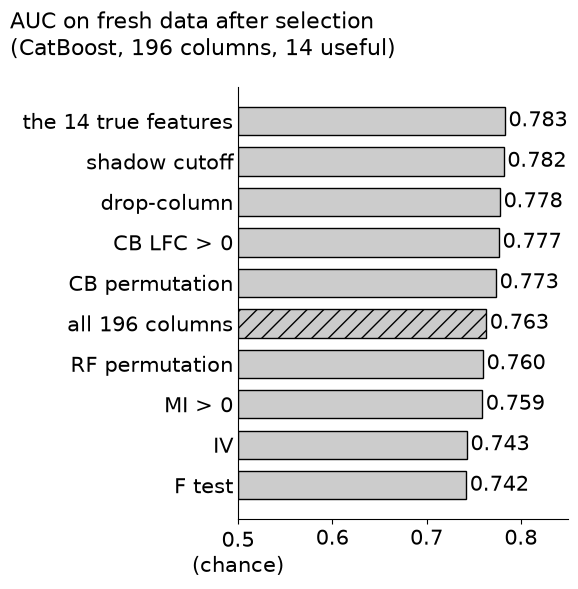

In [41]:
if QUICK:
    print("Skipped in QUICK mode.")
else:
    v = pd.Series({k: med[m] for k, m in FIG3.items()}).sort_values()
    print(v.round(3).to_string())

    fig, ax = plt.subplots(figsize=(6, 6))
    bars = ax.barh(np.arange(len(v)), v - 0.5, left=0.5, height=0.7, color="0.8", edgecolor="black", lw=1)
    bars[list(v.index).index("all 196 columns")].set_hatch("//")
    for i, x in enumerate(v):
        ax.text(x + 0.004, i, f"{x:.3f}", va="center", fontsize=15)
    ax.set_yticks(np.arange(len(v)), v.index, fontsize=15)
    ax.set_xlim(0.5, 0.85)
    ax.set_xticks([0.5, 0.6, 0.7, 0.8], ["0.5\n(chance)", "0.6", "0.7", "0.8"], fontsize=15)
    ax.tick_params(axis="y", length=0)
    ax.spines[["top", "right"]].set_visible(False)
    fig.suptitle("AUC on fresh data after selection\n(CatBoost, 196 columns, 14 useful)", x=0.02, ha="left",
                 fontsize=16)
    fig.subplots_adjust(left=0.4, right=0.95, top=0.85, bottom=0.13)
    fig.savefig("standalone_tests_selection_cost.png")
    plt.show()

### 5d: Figure 2, who finds the weak feature

Median rank of the weak feature over seeds (1 = best). Columns "A" and "B": city in case A and hour
in case B (3a) at s = 0.25, rank among 5 columns; the s = 1 columns are left out so that the
weak-pool columns fit (the 3a tables hold them). Medians are rounded to whole ranks. Columns
"Pool ... full": city and hour in the 3b pool (s = 1, 3 seeds); "Pool ... weak": the 4a pool at
s = 0.25 (6 seeds); rank among 196 columns. Gray = the weak feature is missed: in 3a, it is in the
top 2 in fewer than 80% of seeds (4 of 5); in the pool, its median rank is above 30. The color
tracks the weak feature only: mRMR RF keeps hour in B but loses distance_km in some seeds, so its
"found" count in 3a is lower. In the pool, drop-column runs on the CB LFC top 30. The figure is
drawn here because the weak-pool columns come from 4a.

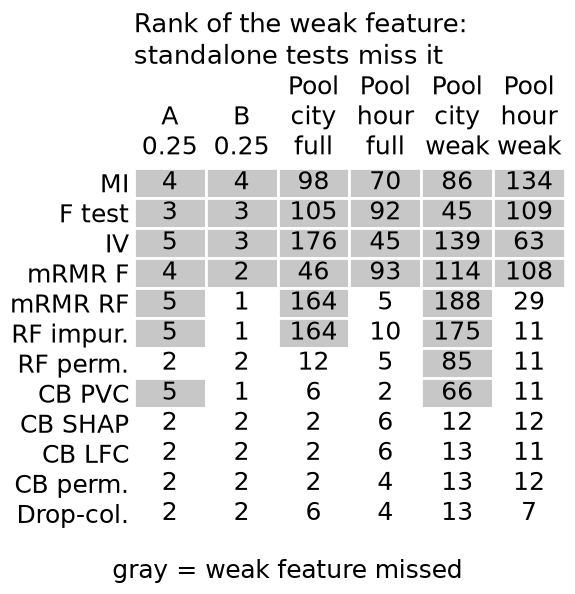

In [42]:
if QUICK:
    print("Skipped in QUICK mode.")
else:
    grid, miss = pd.DataFrame(index=METHODS), pd.DataFrame(index=METHODS)
    for c in "AB":
        d = R3[(R3.case == c) & (R3.s == P5_S)].groupby("method")
        name = f"{c}\n{P5_S:g}"
        grid[name] = d.weak_rank.median()
        miss[name] = d.weak_rank.apply(lambda r: (r <= 2).mean() < 0.8)
    for label, P in (("full", P3B), ("weak", P4A[P4A.s == P5_S])):
        for f in ("city", "hour"):
            name = f"Pool\n{f}\n{label}"
            grid[name] = P.groupby("method")[f"rank {f}"].median()
            miss[name] = grid[name] > 30
    short = {"RF permutation": "RF perm.", "CB permutation": "CB perm.", "Drop-column": "Drop-col.",
             "RF impurity": "RF impur."}

    fig, ax = plt.subplots(figsize=(6, 6))
    nr, nc = grid.shape
    for i, m in enumerate(grid.index):
        for j, col in enumerate(grid.columns):
            ax.add_patch(plt.Rectangle((j, nr - 1 - i), 1, 1, facecolor="0.78" if miss.loc[m, col] else "white",
                                       edgecolor="white", lw=2))
            ax.text(j + 0.5, nr - 0.5 - i, f"{np.floor(grid.loc[m, col] + 0.5):.0f}", ha="center", va="center", fontsize=18)
    ax.set_xlim(0, nc)
    ax.set_ylim(0, nr)
    ax.set_xticks(np.arange(nc) + 0.5, grid.columns, fontsize=18)
    ax.xaxis.tick_top()
    ax.set_yticks(np.arange(nr) + 0.5, [short.get(m, m) for m in grid.index[::-1]], fontsize=18)
    ax.tick_params(length=0)
    for sp in ax.spines.values():
        sp.set_visible(False)
    ax.set_title("Rank of the weak feature:\nstandalone tests miss it", loc="left", fontsize=19)
    fig.text(0.5, 0.015, "gray = weak feature missed", ha="center", fontsize=18)
    fig.tight_layout(rect=(0, 0.06, 1, 1))
    fig.savefig("standalone_tests_who_finds.png")
    plt.show()

### Hypotheses of Part 5

In [43]:
if QUICK:
    print("Skipped in QUICK mode.")
else:
    lines5 = []
    ok19, ok20, txt19, txt20 = [], [], [], []
    for fm in OTHER_FINALS:
        g, sp = GAP5A.loc[fm], SPREAD[fm]
        if use[fm] <= sp:
            txt19.append(f"{fm}: not testable (use of the interactions {use[fm]:.3f} within the spread {sp:.3f})")
            txt20.append(txt19[-1])
            continue
        d14, dF, d196 = g["shadow minus 14 true"], g["shadow minus F test"], g["shadow minus all 196"]
        ok19.append(abs(d14) <= 0.01 and dF >= 0.01 and dF > sp)
        ok20.append(d196 > 0 and d196 > sp)
        txt19.append(f"{fm}: shadow minus 14 true {d14:+.3f}, shadow minus F test {dF:+.3f} (spread {sp:.3f})")
        txt20.append(f"{fm}: shadow minus all 196 {d196:+.3f} (spread {sp:.3f})" + ("" if d196 > sp else ", not separated"))
    lines5.append(("H19", verdict(ok19) if ok19 else "not testable", "; ".join(txt19)))
    lines5.append(("H20", verdict(ok20) if ok20 else "not testable", "; ".join(txt20)))
    lr = AUC5A["Logistic regression"]
    d_ft, d_use = lr["F test"] - lr["shadow cutoff"], use["Logistic regression"]
    lines5.append(("H21", verdict([abs(d_ft) <= 0.005, abs(d_use) <= 0.005]),
                   f"logistic regression: F test minus shadow {d_ft:+.3f}; 14 true minus 10 additive {d_use:+.3f}"))
    full = F5B[F5B.forest == "max_features=1.0, leaf=20"]
    sq = F5B[F5B.forest == "max_features=sqrt, leaf=20"]
    n3 = int((full.interaction_only_top14 >= 3).sum())
    gap_sq = (sq["CatBoost holdout"] - sq["forest holdout"]).median()
    lines5.append(("H22", verdict([n3 >= 2, gap_sq >= 0.02]),
                   f"max_features=1.0 keeps at least 3 of 4 interaction-only in its top 14 in {n3} of {len(full)} seeds; "
                   f"at sqrt CatBoost minus forest holdout AUC {gap_sq:+.3f} (median)"))
    gain_a = F5C[(F5C.case == "A") & (F5C.method == "LGB gain")]
    miss_a = {s: int((gain_a[gain_a.s == s].weak_rank > 2).sum()) for s in FE_S}
    perm25 = {c: found_count(F5C, "LGB permutation", c, 0.25) for c in CASES}
    lines5.append(("H23", verdict([v >= 4 for v in miss_a.values()] + [v >= 4 for v in perm25.values()]),
                   f"gain misses city in A in {miss_a[0.25]} (s=0.25) and {miss_a[0.1]} (s=0.1) of {len(STRENGTH_SEEDS)}; "
                   "permutation finds both at s=0.25: " + ", ".join(f"{c} {v}" for c, v in perm25.items())))
    pp = P5C[P5C.method == "LGB permutation"]["interaction-only in top 14"]
    lines5.append(("H24", verdict([bool((pp == 4).all())]),
                   f"LightGBM permutation keeps all 4 interaction-only in its top 14 in {int((pp == 4).sum())} of {len(pp)} seeds"))
    HYP5 = pd.DataFrame(lines5, columns=["hypothesis", "verdict", "evidence"]).set_index("hypothesis")
    with pd.option_context("display.max_colwidth", 400):
        print(HYP5.to_string())
    print("\nUse of hour, u and v alone (14 true minus 10 additive + city) against the refit spread:",
          {fm: f"{use_hour_uv[fm]:.3f} vs {SPREAD[fm]:.3f}" + ("" if use_hour_uv[fm] > SPREAD[fm] else ", inside")
           for fm in OTHER_FINALS})

                  verdict                                                                                                                                                                                                                                              evidence
hypothesis                                                                                                                                                                                                                                                                     
H19                partly  LightGBM: shadow minus 14 true -0.000, shadow minus F test +0.038 (spread 0.000); Random forest: shadow minus 14 true +0.000, shadow minus F test +0.005 (spread 0.003); MLP: shadow minus 14 true -0.002, shadow minus F test +0.019 (spread 0.009)
H20             confirmed                                                                                      LightGBM: shadow minus all 196 +0.013 (spread 0.000); Random forest: shad

## Claims

Each Part 2 number next to the reference run (a Linux container, 2 cores, catboost 1.2.10). Tolerances: exact for counts and column names;
0.0005 for numbers that depend only on the data (rates, mutual information, p-values, information
value, case C); 0.004 for numbers from a trained CatBoost model, whose third decimal moves with
CatBoost's own seed (refit-noise check); 0.01 for shares and regression coefficients. The CTR
counts, the `log_price` share of CTR elements and the interaction ranks move with the CPU type, so
they are "printed only". The share of CTRs with a numeric split moved much less between the runs so far and is checked. A
failing check does not stop the notebook; failures are listed at the end.

In [44]:
A, B = P2["A"], P2["B"]
ta, tb = A["tab"], B["tab"]
claims = [
    *[(f"A: acceptance rate, city {k}", e, A["rates"].iloc[k], "data") for k, e in enumerate([0.496, 0.496, 0.506, 0.500])],
    ("A: MI city", 0.0000, ta.loc["city", "MI"], "data"),
    ("A: MI log_price", 0.0710, ta.loc["log_price", "MI"], "data"),
    ("A: chi-square p of city", 0.4261, ta.loc["city", "p (chi2 / ANOVA)"], "data"),
    ("A: IV city", 0.0003, ta.loc["city", "IV"], "data"),
    ("A: IV log_price", 0.4961, ta.loc["log_price", "IV"], "data"),
    ("A: IV noise, lowest", 0.0008, ta.loc[NOISE, "IV"].min(), "data"),
    ("A: IV noise, highest", 0.0012, ta.loc[NOISE, "IV"].max(), "data"),
    ("A: AUC alone, city", 0.5000, ta.loc["city", "AUC alone"], "model"),
    ("A: AUC alone, log_price", 0.6932, ta.loc["log_price", "AUC alone"], "model"),
    ("A: AUC, all five columns", 0.857, A["aucs"]["all five columns"], "model"),
    ("A: ceiling", 0.861, A["aucs"]["ceiling (true probability)"], "data"),
    ("A: drop-column, city", 0.1679, ta.loc["city", "drop-col dAUC"], "model"),
    ("A: drop-column, log_price", 0.3478, ta.loc["log_price", "drop-col dAUC"], "model"),
    ("A: MI top 2", "log_price + noise_2", " + ".join(A["top2"]), "exact"),
    ("A: AUC of the MI top 2", 0.690, A["aucs"]["MI top 2"], "model"),
    *[(f"A: AUC, {k}", e, v, "model") for (k, v), e in zip(P2["encodings"].items(), [0.857, 0.691, 0.857, 0.857])],
    ("A: CTR definitions", 91, P2["ctr"]["n"], "info"),
    ("A: CTRs with a numeric split", 88, P2["ctr"]["with_numeric"], "info"),
    ("A: share of CTRs with a numeric split", round(88 / 91, 3), P2["ctr"]["with_numeric"] / P2["ctr"]["n"], "share"),
    ("A: log_price share of numeric CTR elements", 0.80, P2["ctr"]["log_price_share"], "info"),
    *[(f"B: acceptance rate, hours {4 * k}-{4 * k + 4}", e, B["rates"].iloc[k], "data")
      for k, e in enumerate([0.507, 0.492, 0.501, 0.488, 0.503, 0.504])],
    ("B: MI distance_km", 0.0024, tb.loc["distance_km", "MI"], "data"),
    ("B: MI hour", 0.0005, tb.loc["hour", "MI"], "data"),
    ("B: MI noise_1", 0.0034, tb.loc["noise_1", "MI"], "data"),
    ("B: IV distance_km", 0.0197, tb.loc["distance_km", "IV"], "data"),
    ("B: IV hour", 0.0009, tb.loc["hour", "IV"], "data"),
    ("B: ANOVA p of hour", 0.7459, tb.loc["hour", "p (chi2 / ANOVA)"], "data"),
    ("B: AUC alone, hour", 0.50245, tb.loc["hour", "AUC alone"], "model"),
    ("B: AUC alone, distance_km", 0.53215, tb.loc["distance_km", "AUC alone"], "model"),
    ("B: AUC, all five columns", 0.810, B["aucs"]["all five columns"], "model"),
    ("B: ceiling", 0.816, B["aucs"]["ceiling (true probability)"], "data"),
    ("B: drop-column, hour", 0.2820, tb.loc["hour", "drop-col dAUC"], "model"),
    ("B: drop-column, distance_km", 0.3098, tb.loc["distance_km", "drop-col dAUC"], "model"),
    ("B: MI top 2", "noise_1 + distance_km", " + ".join(B["top2"]), "exact"),
    ("B: AUC of the MI top 2", 0.528, B["aucs"]["MI top 2"], "model"),
    ("MI seeds: weak kept, A", 4, P2["mi_seeds"].loc["weak", "A"], "exact"),
    ("MI seeds: weak kept, B", 4, P2["mi_seeds"].loc["weak", "B"], "exact"),
    ("MI seeds: strong kept, A", 20, P2["mi_seeds"].loc["strong", "A"], "exact"),
    ("MI seeds: strong kept, B", 17, P2["mi_seeds"].loc["strong", "B"], "exact"),
    ("MI seeds: both kept, A", 4, P2["mi_seeds"].loc["both real", "A"], "exact"),
    ("MI seeds: both kept, B", 3, P2["mi_seeds"].loc["both real", "B"], "exact"),
    ("C: corr(x1, t)", 0.427, P2["C"]["corr x1"], "data"),
    ("C: corr(x2, t)", 0.001, P2["C"]["corr x2"], "data"),
    ("C: holdout R2, x1", 0.182, P2["C"]["R2 x1"], "data"),
    ("C: holdout R2, x2", -0.000, P2["C"]["R2 x2"], "data"),
    ("C: holdout R2, x1 + x2", 0.916, P2["C"]["R2 x1 + x2"], "data"),
    ("C: coefficient of x1", 1, P2["C"]["coef x1 + x2"][0], "coefficient"),
    ("C: coefficient of x2", -2, P2["C"]["coef x1 + x2"][1], "coefficient"),
    ("Interaction: rank of the true pair, A seed 42", 4, P2["inter_rank_42"], "info"),
    *[(f"Interaction: ranks over seeds, {k}", e, P2["inter_ranks"][k], "info") for k, e in
      zip(P2["inter_ranks"], [[1, 2, 1, 2, 1, 2], [1, 1, 1, 1, 1, 1], [1, 1, 1, 1, 1, 1]])],
    ("City as a plain number, relabeled ids (no reference)", "-", P2["encodings"]["city as a plain number, relabeled ids"], "info"),
]
TOL = {"data": 0.0005, "model": CB_REFIT_NOISE, "share": 0.01, "coefficient": 0.01}
out, failures = [], []
for claim, expected, mine, kind in claims:
    if kind == "info":
        status = "printed only"
    else:
        try:
            if kind == "exact":
                assert expected == mine
            else:
                assert abs(float(mine) - expected) <= TOL[kind]
            status = "ok"
        except AssertionError:
            status = "DIFFERENT"
            failures.append(claim)
    shown = f"{mine:.5f}" if isinstance(mine, float) else str(mine)
    out.append((claim, expected, shown, kind, status))
with pd.option_context("display.max_rows", 200, "display.max_colwidth", 60):
    print(pd.DataFrame(out, columns=["claim", "reference", "this run", "tolerance", "status"]).to_string(index=False))

print("\nMain Part 3 tables, repeated:\n")
for s in (1, 0.25):
    print(f"3a, s = {s}: found in x of {len(STRENGTH_SEEDS)} [median weak rank]")
    print(found_table(R3, s).to_string(), "\n")
print("3b, own cutoffs (useful / interaction-only / noise kept, per seed)")
print(CUT_TABLE.to_string())
print("\n3b, interaction-only features (of 4) in the top 14, per seed")
print(TOPK["interaction-only in top 14"].to_string())

print("\nFailed checks:")
print("\n".join(f"  - {f}" for f in failures) if failures else "  none")

                                                claim             reference              this run   tolerance       status
                           A: acceptance rate, city 0                 0.496               0.49593        data           ok
                           A: acceptance rate, city 1                 0.496               0.49621        data           ok
                           A: acceptance rate, city 2                 0.506               0.50625        data           ok
                           A: acceptance rate, city 3                   0.5               0.49995        data           ok
                                           A: MI city                   0.0               0.00003        data           ok
                                      A: MI log_price                 0.071               0.07101        data           ok
                              A: chi-square p of city                0.4261               0.42613        data           ok
                

In [45]:
if QUICK:
    print("Skipped in QUICK mode.")
else:
    def span(v):
        v = sorted(int(x) for x in v)
        return f"{v[0]}" if v[0] == v[-1] else f"{v[0]} to {v[-1]}"


    def pool_numbers(P, CUTS, SH):
        io = " / ".join(span(P[P.method == m]["interaction-only in top 14"]) for m in ("MI", "F test", "IV", "mRMR F"))
        kept = " / ".join(span(CUTS[CUTS.rule == r].useful) for r in ("F test, BH q < 0.05", "IV >= 0.02"))
        lfc_noise = span(CUTS[CUTS.rule == "CB LFC > 0"].noise)
        shadow = f"{SH.noise.mean():.2f} / {EXPECTED_NOISE_KEPT:.2f} / {SH.useful.mean():.1f} of 14"
        t = P.groupby("method").seconds.median()
        times = " / ".join(f"{t[m]:.0f}" for m in ("CB LFC", "CB permutation", "RF permutation")) + \
            f" / {CUTS[CUTS.rule == 'Shadow (CB LFC)'].seconds.median():.0f} / {t['Drop-column']:.0f}"
        return [io, kept, lfc_noise, shadow, times]


    def a_ranks(G, methods, s_values):
        return " / ".join(span(G[(G.case == "A") & (G.method == m) & G.s.isin(s_values)].weak_rank) for m in methods)

    q = ["Interaction-only features in the top 14, MI / F test / IV / mRMR F (pool)",
         "Useful features kept by F test (BH q < 0.05) / IV (>= 0.02) (pool)",
         "Noise columns kept by CB LFC > 0 (pool)",
         "Shadow cutoff: mean noise kept / chance level / useful kept (pool)",
         "Seconds on the pool: CB LFC / CB permutation / RF permutation / shadow step per shuffle / drop-column on 30"]
    old = ["0, 0, 0 for each", "10 of 14 / 9 of 14", "41 to 46", "0.93 / 0.92 / 14 of 14", "5 / 23 / 37 / 9 / 50"]
    full4a = pool_numbers(P4A[P4A.s == 1], CUT4A[CUT4A.s == 1], SHADOW4A[SHADOW4A.s == 1])
    weak4a = pool_numbers(P4A[P4A.s == 0.25], CUT4A[CUT4A.s == 0.25], SHADOW4A[SHADOW4A.s == 0.25])
    POST2 = pd.DataFrame({"quantity": q, "previous version": old, "this run, Part 3": pool_numbers(P3B, CUT, SHADOW),
                          "Part 4, s = 1": full4a, "Part 4, s <= 0.25": weak4a})
    lib_rf = ALT4[(ALT4.case == "A") & (ALT4.s == 1) & (ALT4.method == "lib mRMR RF")].weak_rank
    POST2.loc[len(POST2)] = ["mRMR RF rank of city, case A, s = 1 (of 5)", "3 to 5 in every seed",
                             span(R3[(R3.case == "A") & (R3.s == 1) & (R3.method == "mRMR RF")].weak_rank),
                             "library mRMR RF (4c): " + span(lib_rf), ""]
    POST2.loc[len(POST2)] = ["RF impurity / CB PVC rank of city, case A, s <= 0.25 (of 5)", "5 in all 5 seeds",
                             a_ranks(R3, ("RF impurity", "CB PVC"), (0.25, 0.1)),
                             "", "4b, N = 40,000: " + a_ranks(GRID[GRID.n == 40_000], ("RF impurity", "CB PVC"), (0.25, 0.1))]
    print("\nNumbers post 2 may quote (ranges over seeds; Part 3 is the 3b pool, or 3a for the case A rows; "
          "Part 4 columns are the 4a pool unless a cell names another block)\n")
    with pd.option_context("display.max_colwidth", 120, "display.width", 250):
        print(POST2.to_string(index=False))


    def auc_span(v):
        return f"{v.min():.3f}" if f"{v.min():.3f}" == f"{v.max():.3f}" else f"{v.min():.3f} to {v.max():.3f}"


    def fe_quote(m):
        d, q = FE[FE.method == m], FEP[FEP.method == m]
        found = {s: " / ".join(str(found_count(FE, m, c, s)) for c in CASES) for s in FE_S}
        return {"selector": m, "both kept, s = 0.25, A / B / D": found[0.25], "both kept, s = 0.1, A / B / D": found[0.1],
                "mean noise kept of 3, s = 0.25 / 0.1": " / ".join(f"{d[d.s == s].noise.mean():.1f}" for s in FE_S),
                "3a seconds": f"{d.seconds.median():.1f}",
                "pool seeds": q.seed.nunique(), "pool useful / interaction-only": f"{span(q.useful)} / {span(q.interaction_only)}",
                "pool noise, Gaussian / four-level": f"{span(q.gaussian_noise)} / {span(q.four_level_noise)}",
                "pool AUC": auc_span(q.auc), "pool seconds": f"{q.seconds.median():.0f}"}


    print("\n4d, feature_engine selectors (3a: of 5 seeds; pool: ranges over seeds, s = 0.25)\n")
    print(pd.DataFrame([fe_quote(m) for m in FE_SELECTORS]).to_string(index=False))


    def e_quote(m):
        d, q = E4[E4.method == m], E4P[E4P.method == m]
        found = {s: " / ".join(str(found_count(E4, m, c, s)) for c in CASES) for s in FE_S}
        return {"method": m, "both in top 2, s = 0.25, A / B / D": found[0.25], "both in top 2, s = 0.1, A / B / D": found[0.1],
                "3a seconds (MultiSURF on 5,000 rows)": f"{d.seconds.median():.1f}",
                "pool interaction-only in top 30": span(q["interaction-only in top 30"]),
                "pool AUC, top 14": auc_span(q.auc), "pool seconds": f"{q.seconds.median():.0f}"}


    print("\n4e (3a: of 5 seeds; pool: range over seeds, s = 0.25)\n")
    print(pd.DataFrame([e_quote(m) for m in E_METHODS]).to_string(index=False))
    print("\nPool pair ranks, worst over seeds:", PAIRS.groupby("s").max().drop(columns="seed").to_dict("index"))

    print(f"\nPart 5. 5a, pool at s = {P5_S:g}, AUC gaps of each final model (medians over seeds). The CatBoost "
          "row repeats the 4a refits, unchanged from d1521b7; the other rows are new. Refit spreads are measured on "
          "the pool (seed 7100); logistic regression has none\n")
    q5 = GAP5A.drop(columns="city alone").assign(**{"refit spread": pd.Series(SPREAD)}).reindex(FINAL_MODELS)
    print(q5.round(3).to_string())
    print("\n5b, forest permutation importance (pool, s = 0.25): interaction-only in the top 14 per seed, "
          "and CatBoost minus forest holdout AUC (median). In d1521b7 the 4a RF permutation "
          "kept 1 in every seed")
    print(F5B.assign(gap=F5B["CatBoost holdout"] - F5B["forest holdout"]).groupby("forest", sort=False)
          .agg(top14=("interaction_only_top14", seeds_str), gap=("gap", "median")).round(3).to_string())
    print("\n5c, LightGBM as the selector: both real features in the top 2 at s = 0.25, A / B / D (of 5)")
    print({m: " / ".join(str(found_count(F5C, m, c, 0.25)) for c in CASES) for m in LGB_METHODS})
    print("pool, interaction-only in the top 14 per seed:",
          {m: seeds_str(P5C[P5C.method == m]["interaction-only in top 14"]) for m in LGB_METHODS})


Numbers post 2 may quote (ranges over seeds; Part 3 is the 3b pool, or 3a for the case A rows; Part 4 columns are the 4a pool unless a cell names another block)

                                                                                                   quantity       previous version         this run, Part 3                     Part 4, s = 1        Part 4, s <= 0.25
                                  Interaction-only features in the top 14, MI / F test / IV / mRMR F (pool)       0, 0, 0 for each            0 / 0 / 0 / 0 0 to 1 / 0 to 1 / 0 to 1 / 0 to 2            0 / 0 / 0 / 0
                                         Useful features kept by F test (BH q < 0.05) / IV (>= 0.02) (pool)     10 of 14 / 9 of 14                   10 / 9                      10 to 11 / 9                  10 / 10
                                                                    Noise columns kept by CB LFC > 0 (pool)               41 to 46                 41 to 46                          26 to 38   

## Summary

- **H1 (control): partly.** MI, the F test and IV find the weak feature about as often as
  chance: they miss it in all five seeds in 14 of 36 cells, against 12.8 expected for a method
  blind to it. In the 3b pool the F test puts one interaction-only feature in its top 30 in one seed;
  in 4a at s = 1 it does so in 4 of 6 seeds.
- **H2: confirmed.** At s = 1, mRMR with forest relevance loses city in every seed: its redundancy
  term divides city's relevance by city's correlation with log_price.
- **H3 and H5: confirmed, the main result.** At s <= 0.25 in case A, RF impurity and CatBoost's
  default importance (PVC) rank city last in every seed; permutation importance, CB LFC and
  drop-column keep it in the top 2. With four-level noise columns both recover city: split-based
  scores favor the column with more distinct values. CB LFC and CB permutation computed on the
  training rows still keep city, so the training rows are not the cause. For CB PVC the four-level noise columns are also categorical, so type and number of
  values change together.
- **H6: confirmed.** Over 5 shuffles of each of 3 seeds, the shadow cutoff keeps all 14 useful
  features and about one noise column per run (0 to 3), against 0.92 expected by chance.
- **H7: confirmed, but it says little:** both methods find the pair in every run of 3a.
- **Correlated copy (3d).** With a 0.95-correlated copy, drop-column credits neither distance nor
  the copy, while permutation importance keeps distance high.
- **H8: partly.** In the pool at s = 0.25, RF impurity and CB PVC drop city below rank 30 in most
  seeds, and CB LFC and CB permutation keep all four interaction-only features in their top 30 in
  every seed. RF permutation does not: it keeps one or two of the four and ranks city far down,
  while on five columns at the same strength it finds the pair in every seed. 5a and 5b point to
  the model: the forest barely fits the joint effects, city's included (5a: 0.005), and more
  columns per split do not change that (H22).
- **H9: confirmed.** At s = 0.25 the shadow cutoff keeps 3.83 of the 4 interaction-only features
  on average, 2 in the worst of 12 runs, and about as many noise columns as chance. At s = 1 on the
  new seeds it keeps more noise than chance (1.33 against 0.92), still under the H6 bar, and in one run (seed
  7103) it keeps 12 of the 14 useful features and 2 of the 4 interaction-only ones.
- **H10: partly.** CMIM and JMI pick log_price first in A and then find city in every seed, at
  both strengths, where every mRMR variant misses it in at least 4 of 5 seeds. The prediction for B was wrong: a pair member
  is picked first in every run, so they find the pair there too. In D the pair is found only when
  u or v is picked first. In the pool they keep city (JMI also hour) but never u or v, whose
  interaction has no standalone part.
- **H11: partly.** CB SHAP finds the pair in A at s = 0.25 in every seed, where CB PVC misses in
  every seed. In the pool both rank the four-level noise columns last, so the gap is the same and
  the second part fails. Per seed, the median rank of the four-level noise is 196, 196, 196 for both,
  and that of the Gaussian noise 89.5, 90.5, 89.5 (CB SHAP) and 89.5, 89.5, 89.5 (CB PVC). Both give
  at least half of the 32 four-level columns the lowest score, so they share rank 196 and the test
  cannot separate the two methods.
- **Where the model-based methods fail (4b).** Every method fails with few rows and a weak
  joint effect. RF impurity and CB PVC never find the pair in A at s <= 0.25 in the grid. At s = 0.05 and
  N = 40,000 the loss-based methods are one seed apart, which 5 seeds cannot separate: in A, CB LFC
  4 of 5, CB permutation and drop-column 3 of 5; in B, these three 3 of 5, against 4 or 5 of 5 for
  RF impurity, RF permutation, CB PVC and CB SHAP. With 100 noise columns at s = 0.25, RF impurity, RF permutation
  and CB PVC lose the pair in A; CB SHAP, CB LFC, CB permutation and drop-column keep it.
- **Library mRMR (4c).** With F relevance the library gives the same order as the mRMR of Part 3
  in every run. With its own forest it differs in about half the runs and still loses city in A.
  With `cat_features` its default leave-one-out encoding makes a column with no link to the target
  look like the best feature.
- **H12: confirmed,** but nearly by construction: RFE is a cross-validated drop-column with a bar
  of 0.01 AUC, and it keeps both real features at s = 0.1 exactly when the 3a drop-column loss of
  the weak one is above 0.01, in 14 of 15 runs. So it loses hour in B at s = 0.1 in all 5 seeds,
  where hour is worth about 0.002 AUC on fresh data (0.578 against 0.580). On one pool seed (7100)
  it keeps 12 of the 14 useful features (3 of the 4 interaction-only) and no noise in about 20 minutes;
  the refit on its columns scores 0.764, against 0.761 for all 196 columns and 0.780 for the 14
  useful features on the same seed.
- **H13: confirmed.** The probe selector drops city in A in every seed at both strengths. Its
  mean noise count at s = 0.25 (1.13 of 3) passes the bar of 1 because of B (2.2; A and D 0.6). In
  the pool it keeps 13 of the 14 useful features in every seed (the one it drops is city), 13 to
  70 of the 150 Gaussian noise columns, depending on the seed, and none of the four-level ones; the refit on its columns scores the same as all 196 columns (median AUC 0.764
  against 0.763). Probe all is worse: it keeps all 3 noise columns in every 3a run and 129 to 149
  Gaussian noise columns in the pool.
- **H14: confirmed.** Shuffling keeps both real features in every case at s = 0.25 and loses hour
  in B at s = 0.1 in every seed. In the pool it keeps 13 or 14 useful features and no noise in
  about 20 seconds, and the refit on its columns has median AUC 0.782 on fresh data, against 0.783
  with the 14 useful features. Its bar is the mean AUC drop over all columns, which falls as noise
  columns are added; in the pool it was tested at 196 columns and s = 0.25 only.
- **H15: confirmed.** The `feature_engine` mRMR never keeps both real features in A. Its result
  depends on the column order: on reversed columns it keeps both in B at s = 0.25 in 1 seed
  instead of 3. On one pool seed (7100) the refit on its columns scores 0.735 and 0.721, below
  0.761 for all 196 columns on that seed.
- **H16: confirmed.** CatBoost's `select_features` puts both real features in its top 2 in every
  3a run, at s = 0.1 too, by SHAP and by LFC. In the pool it ranks the 14 useful features first in
  every seed, in about a minute per seed. It adds little over one fit of CB LFC or CB SHAP, which
  do the same in the pool in about 5 seconds and miss one seed in one 3a cell each at s = 0.1. Like
  the other ranking rows it is told the number to keep (top 2, top 14), unlike the 4d selectors,
  and it uses the holdout rows for early stopping and scoring, which they never see.
- **H17: partly.** MultiSURF finds the XOR pair in D in every seed but misses city in A in 3 of 5
  seeds, not 4, and finds the pair in B at s = 0.1 in 2 of 5. It ran on 5,000 rows, against 14,000
  to 28,000 for the other methods. In the pool it fails: 9 or 10 useful features in its top 14 and at most 1 of the 4
  interaction-only features in its top 30.
- **H18: confirmed.** CatBoost's interaction ranking puts all three true pairs in the top 10 of
  19,110 at s = 1 in every seed. At s = 0.25 city and log_price fall to ranks 18 and 31 in two
  seeds, and u and v to rank 23 in one. The top 10 also holds at least 7 other pairs, so it is a
  list of candidates to check, and the ranks move with the CPU type (Part 2). The city and
  log_price pair is additive in log-odds, so its rank shows that the trees use both together.
- **H19: partly.** In the pool at s = 0.25 the shadow-cutoff set scores within 0.002 AUC of the 14
  true features for every final model. It beats the F test set by 0.038 for LightGBM and 0.019 for
  the MLP, positive in all 6 seeds for both, but by only 0.005 for the forest. All three pass the
  rule set before the run (14 true minus 10 additive above the refit spread). For the forest and
  the MLP most of that gap is city, which is not an interaction (H21). Hour, u and v on top of the
  10 additive features and city add 0.024 for LightGBM (6 of 6 seeds). For the forest they add
  0.001 to 0.003 in all 6 seeds, not above its refit spread of 0.003, and for the MLP 0.003, positive
  in 4 of 6 seeds and inside its spread of 0.009. (A spread is the range of 5 refits on one seed.)
  So at s = 0.25 only LightGBM and CatBoost use the interactions by more than the noise, and for
  the forest and the MLP H19 tests city and the noise columns. LightGBM's gain depends on its
  settings, which are not tuned; only one setting was run. At s = 1 the MLP and the forest use the
  interactions (0.890 and 0.797 on the 14 true features, against 0.786 and 0.759 on the 10
  additive features and city), and the shadow-cutoff set costs them 0.016 and 0.008. No refit
  spread was measured at s = 1.
- **H20: confirmed.** All 196 columns score below the shadow-cutoff set for LightGBM (by 0.013),
  the forest (0.013) and the MLP (0.044), positive in all 6 seeds for each. LightGBM with these
  settings has no random part, so its refit spread is 0. The settings are not tuned: on all 196
  columns LightGBM (0.747), the forest (0.733) and the MLP (0.724) score below logistic regression
  (0.765), which itself scores 0.009 lower on all 196 columns than on the 14 true features. For the
  forest and the MLP the F test set also beats all 196 columns (by 0.007 and 0.025), so much of
  their gain is from dropping noise. The RF permutation set, which fails in 4a, scores below all
  196 columns for CatBoost and LightGBM (0.003 each; for CatBoost inside the refit noise) and
  logistic regression (0.009), and above them for the forest (0.008) and the MLP (0.015).
- **H21: not confirmed, because the premise is wrong for city.** Logistic regression gains 0.021
  from the 14 true features over the 10 additive ones, and the F test set scores 0.022 below the
  shadow-cutoff set. The generator's city term is c times (log_price minus the city's price
  level), with c = 8s (2 at s = 0.25). That is a city term plus a log_price term, so it is additive
  in the logit. For every final model city works like x2 in case C (no standalone signal, additive
  in the model), not like an interaction; only hour, u and v interact. The 5a table shows it: for
  logistic regression city alone adds 0.017 to 0.024 AUC to the 10 additive features (6 of 6
  seeds), and hour, u and v on top add 0.000. "Interaction-only" in this notebook means no
  standalone signal (Part 3).
- **H22: partly.** At "sqrt" the forest's holdout AUC is 0.028 below CatBoost's (median of the
  per-seed gaps; medians 0.733 and 0.762; ceiling 0.805). With all columns per split its
  permutation importance keeps 1, 0 and 2 of the 4 interaction-only features in its top 14, and
  its holdout AUC falls to 0.716 (0.713 with `min_samples_leaf=5`). The data point to the first
  reading: the forest barely fits the joint effects. In 5a (city one-hot; 5b uses integer codes)
  hour, u and v add 0.001 for the forest, against 0.026 for CatBoost, and at "sqrt" the one
  interaction-only feature in the 5b top 14 is hour (rank 11 in every seed), which has a small
  standalone effect. So the failure is in the model more than in permutation importance. This also
  tests H4.
- **H23: confirmed.** LightGBM's gain importance misses city in A in all 5 seeds at s = 0.25 and
  0.1, as CB PVC does, and in D at s = 0.1 it finds the pair in 1 of 5 seeds, against 4 of 5 for CB
  PVC. Its holdout permutation importance finds both features in every seed of A,
  B and D at s = 0.25 and 0.1, and its shadow cutoff keeps both in 8 to 10 of the 10 runs per cell
  with 0.2 to 0.8 noise columns on average.
- **H24: not confirmed.** In the pool LightGBM's permutation importance keeps all 4
  interaction-only features in its top 14 in 1 of 3 seeds (3, 2 and 4), though all 4 are in its top
  30 in every seed. The misses are u and v (ranks 19 and 20); city and hour are in the top 14 in
  every seed. Its shadow cutoff keeps 2 to 4 of them and 0 to 5 noise columns per run. This
  tests LightGBM with the untuned settings of 5a (0.760 on the 14 true features, against 0.783 for
  CatBoost), and the AUC of a refit on the columns it keeps is not measured.
- **Part 5 runtime:** 30 minutes (5a 9, its refit-noise check 1, 5b 7, 5c 12), within the
  60-minute budget, so nothing was cut.
- **Cost of a selection** (CatBoost refit on the kept columns, scored on fresh data; pool at
  s = 0.25, medians over 6 seeds): 0.783 with the 14 useful features and 0.763 with all 196. The
  4a cutoffs score 0.782 (shadow), 0.778 (drop-column), 0.777 (CB LFC > 0), 0.773 (CB permutation),
  0.760 (RF permutation), 0.759 (MI > 0), and 0.742 to 0.743 for the F test and IV, which drop
  all four interaction-only features. The top 14 of `select_features` scores 0.783 by SHAP and by
  LFC (it is told to keep 14 and keeps the 14 useful features), and that of MultiSURF 0.737. The
  shadow row is its first shuffle. CatBoost's refit spread on the pool is 0.003 on the
  shadow-cutoff set and 0.007 on all 196 columns (5a), so shadow, select_features and the 14 true
  features are not ordered, nor are drop-column and CB LFC > 0, and RF permutation and MI > 0 are
  not separated from all 196 columns. All times are on 14 cores at 196 columns; the cost at real
  column counts is not measured. The verdicts closest to their bars are
  H12 (14 of 15 against 12), H13 (1.13 against 1), H17 (3 of 5 against 4), H11, which failed
  on an exact tie, the forest's use of the interactions in H19 (0.005 against a spread of 0.003)
  and H22 (0.028 against 0.02).
- **CPU-dependent:** the `log_price` share of CTR elements (0.80 in the reference run, 0.71 in
  this one).
- **Also:** for the forest and CatBoost importances the XOR case was about as hard as case B; the
  four-level city was the hard case.
- **Hour and the F test.** The F test misses the main effect of hour, which has no linear trend (3c).
- **Hour in the pool** is not purely interaction-only: the acceptance rate by 4-hour bin moves from
  0.384 to 0.407 at s = 1 (0.315 to 0.335 at s = 0.25). At s = 1 it is higher near midnight and
  noon, where the hour x distance term is strongest. The standalone tests still give hour median ranks of 45
  to 93 of 196 in 3b.

In [46]:
print("Runtime per block, seconds:", {k: round(v) for k, v in TIMES.items()})
print(f"Total runtime: {(time.perf_counter() - T0) / 60:.1f} min on {cpu_model()} with N_JOBS = {N_JOBS}")

Runtime per block, seconds: {'Part 2 case A': 71, 'Part 2 case B': 42, 'Part 2 MI seeds': 10, 'Part 2 coding': 18, 'Part 2 interaction': 21, 'Part 2 refit noise': 77, 'Part 3a': 625, 'Part 3a control': 25, 'Part 3b': 451, 'Part 3c': 22, 'Part 3d': 47, 'Part 4a': 1474, 'Part 4b grid': 548, 'Part 4b, 100 noise columns': 1517, 'Part 4c': 176, 'Part 4c pool': 3, 'Part 4d': 1025, 'Part 4d pool': 1723, 'Part 4e': 1085, 'Part 4e pool': 1001, 'Part 5a': 559, 'Part 5a refit noise': 82, 'Part 5b': 440, 'Part 5c': 366, 'Part 5c pool': 371}
Total runtime: 196.4 min on Apple M4 Pro with N_JOBS = -1
